# B1组-验证 Notebook

本文件汇总 B1组（G12）四位成员在各自负责知识点上的干净环境运行记录。

- 各 section 保留原始运行输出，合并后**未整体重跑**（避免跨环境状态污染、覆盖干净环境证据）。
- 各成员的 SHA 与环境见 `B1组-验证报告.md` 第 0、1 节；每个 section 首单元另注明源文件。
- 成员分工：甲 A1插值/A1逼近；乙 A1插值积分/A2数值积分；丙 A1插值微分/A2自动微分；丁 A1网络逼近/A2网络逼近。
- 节序按第02章章节先后排列。

> 执行计数说明（I-04）：各段执行计数跨段重置、段内不连续，源于各成员原始输出拼接与按分工裁剪单元，合并后未整体重跑；各成员完整原始 Notebook 见组包根目录各成员结果目录。

## 甲/乙：A1 2.1–2.3（插值 / 逼近 / 插值积分）

- 源文件：`B1组-A1-2.1-2.3-验证结果\B1组-A1-2.1-2.3-验证代码.ipynb`
- 合并件，覆盖 A1 §2.1（甲）、§2.2（甲）、§2.3（乙）；整本保留，10 个代码单元。

# 第02章 逼近的智慧 · B组复现与验证

| 被审版本 | 组别 | 提交 SHA-256（本地固定，A1 自述 commit `601b2f70…` 无法在公共仓库核验） | 文件 |
| --- | --- | --- | --- |
| A1 | A1组（G8） | 正文 `06aa6b3c…7403bd`；Notebook `d87f511f…74c9053c`；模块 `9b167046…dbc717c`（与 A1 环境记录一致） | `A1-G8-正文.md`、`A1组-实验.ipynb`、`G8-附件/ch2_numerics.py` |

**范围**：2.1 插值与 Runge 现象、2.2 最小二乘与 Chebyshev 基、2.3 插值积分（含习题题 1、题 2、题 3）。2.4–2.5 的数据即使运行也不提交。
**独立性**：本 Notebook 不导入 A1 的 `ch2_numerics`；所有实现为 B 组独立编写，参考值来自解析式、精确有理数（`Fraction`）与 90 位 Decimal 精算。A1 的已发表数值只作最后对照（以常量形式摘录）。
**容差前置**：节点误差断言为逐位相等；多项式再现性 ≤1e-14；网格误差对 A1 值的相对差 n≤16 时 ≤1e-12，n=32 等距因 Lebesgue 放大放宽到 ≤1e-8；条件数相对差 ≤1e-10；残差相对差 ≤1e-12；2.3 的梯形值用精确分数断言**逐位相等**（不设容差）。

## 复现环境与参考基线

In [1]:
import sys, json, math, time
import numpy as np
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('device CPU, dtype float64; 2.1 无随机数; 2.2 种子 2026（稳健性 0/1/42）')

python 3.12.0
numpy 2.0.1
device CPU, dtype float64; 2.1 无随机数; 2.2 种子 2026（稳健性 0/1/42）


## 2.1 插值与Runge现象（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1 | Runge，n=8/16/32，等距 vs Chebyshev 零点，6001 点偏移网格 | 解析 f(z) + 独立实现 | 相对差 ≤1e-12（n=32 等距 ≤1e-8） | 见下表 | 数值全部复现 |

In [2]:
runge = lambda x: 1.0/(1.0+25.0*x*x)

def lagrange_direct(nodes, values, points):
    x = np.asarray(nodes, float); y = np.asarray(values, float); z = np.asarray(points, float)
    out = np.zeros_like(z)
    for j in range(len(x)):
        basis = np.ones_like(z)
        for k in range(len(x)):
            if k != j:
                basis *= (z - x[k]) / (x[j] - x[k])
        out += y[j] * basis
    return out

def bary_eval(nodes, values, points):
    x = np.asarray(nodes, float); y = np.asarray(values, float); z = np.asarray(points, float).ravel()
    w = np.array([1.0/np.prod([x[j]-x[k] for k in range(len(x)) if k != j]) for j in range(len(x))])
    out = np.empty_like(z)
    for i, p in enumerate(z):
        d = p - x
        if np.any(d == 0.0):
            out[i] = y[int(np.argmin(np.abs(d)))]
        else:
            t = w / d
            out[i] = (t @ y) / t.sum()
    return out

grid = -1.0 + 2.0*(np.arange(6001) + 0.371)/6001.0
print('网格端点实测: %.6f, %.6f （确为 [-1,1] 内部网格）' % (grid[0], grid[-1]))

A1_CLAIM = {(8,'equispaced'):1.0451765938537918, (8,'cheb'):0.17083555982584997,
            (16,'equispaced'):14.393763270429988, (16,'cheb'):0.032613573630504655,
            (32,'equispaced'):5059.0113712515595, (32,'cheb'):0.0014017422708303973}
rows = []
for n in (8, 16, 32):
    for kind in ('equispaced', 'cheb'):
        x = np.linspace(-1,1,n+1) if kind=='equispaced' else np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2))
        y = runge(x)
        p_b = bary_eval(x, y, grid); p_d = lagrange_direct(x, y, grid)
        node_err = float(np.max(np.abs(bary_eval(x, y, x) - y)))
        err = float(np.max(np.abs(p_b - runge(grid))))
        rel = abs(err - A1_CLAIM[(n,kind)])/A1_CLAIM[(n,kind)]
        tol = 1e-8 if (n,kind)==(32,'equispaced') else 1e-12
        assert rel <= tol and node_err == 0.0
        rows.append((n, kind, err, A1_CLAIM[(n,kind)], rel, node_err))
print(' n  节点族          B组实测             A1发表值            相对差        节点误差')
for n,k,e,a,r,ne in rows:
    print(f'{n:2d}  {k:12s} {e:.9g}  {a:.9g}  {r:.2e}  {ne:.1f}')
print('全部断言通过（相对差与容差见上）')

网格端点实测: -0.999876, 0.999790 （确为 [-1,1] 内部网格）


 n  节点族          B组实测             A1发表值            相对差        节点误差
 8  equispaced   1.04517659  1.04517659  1.70e-15  0.0
 8  cheb         0.17083556  0.17083556  0.00e+00  0.0
16  equispaced   14.3937633  14.3937633  3.80e-13  0.0
16  cheb         0.0326135736  0.0326135736  6.81e-15  0.0
32  equispaced   5059.0114  5059.01137  5.77e-09  0.0
32  cheb         0.00140174227  0.00140174227  2.38e-13  0.0
全部断言通过（相对差与容差见上）


In [3]:
# 行为核查与补充验证（对应修正清单 B-2.1-01/02/04/05/06）
# (a) 例2.1.1 再现性基线：q=2x^2-x+3 应被三节点精确还原
q = lambda t: 2*t*t - t + 3
checks = np.array([-0.73, 0.23, 0.89])
p = bary_eval(np.array([-1.,0.,1.]), q(np.array([-1.,0.,1.])), checks)
np.testing.assert_allclose(p, q(checks), atol=1e-14, rtol=0)
print('(a) 再现性基线:', p, '真值:', q(checks))

# (b) Chebyshev 零点确为 T_{n+1} 零点（递推独立验证）
def T(k, t):
    a = np.ones_like(t); b = t
    for _ in range(2, k+1): a, b = b, 2*t*b - a
    return b if k >= 1 else a
for n in (8,16,32):
    x = np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2))
    assert np.max(np.abs(T(n+1, x))) < 2e-14
print('(b) Chebyshev 零点公式验证通过 (n=8,16,32)')

# (c) 重心权重与解析公式对照（共同缩放下比值应为常数）
for n in (8,16,32):
    x = np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2)); j = np.arange(n+1)
    wref = (-1.0)**j * np.sin((2*j+1)*np.pi/(2*n+2))
    w = np.array([1.0/np.prod([x[a]-x[b] for b in range(len(x)) if b != a]) for a in range(len(x))])
    r = w/wref
    print(f'(c) n={n} Chebyshev 解析权重比值 max/min = {r.max()/r.min():.16f}')

# (d) 规格核查：正文称"点越界应被显式拒绝"，但重心求值无区间概念（以 B 组独立实现演示，
#     A1 实现行为相同——见 check_a1_behavior.py 对隔离副本的实测：x=1.5 返回 486.835，真值 0.017467）
x9 = np.linspace(-1,1,9); v = bary_eval(x9, runge(x9), [1.5])
print(f'(d) 区间外点 x=1.5 被接受: 输出 {v[0]:.6f}, 真值 {runge(1.5):.6f}, 误差 {abs(v[0]-runge(1.5)):.3f} —— 规格与实现不符')

# (e) n=32 等距峰值点 90 位 Decimal 复算（核对 A1 的"90位精度相对差 5.91e-9"声明）
from decimal import Decimal, getcontext
getcontext().prec = 90
n = 32
xe = [Decimal(-1) + Decimal(2)*Decimal(j)/Decimal(n) for j in range(n+1)]
ye = [Decimal(1)/(1 + 25*t*t) for t in xe]
xf = np.linspace(-1.0, 1.0, n+1)
pf = lagrange_direct(xf, runge(xf), grid)
idx = int(np.argmax(np.abs(pf - runge(grid))))
zs = Decimal(grid[idx].item())
hp = sum(ye[j] * math.prod((zs-xe[k])/(xe[j]-xe[k]) for k in range(n+1) if k != j) for j in range(n+1))
err_hp = abs(hp - Decimal(1)/(1+25*zs*zs))
rel = abs(err_hp - Decimal(repr(A1_CLAIM[(n,'equispaced')]))) / err_hp
print(f'(e) 峰值点 z={float(zs):.9f}, 90位精确网格最大误差 = {err_hp}')
print(f'    A1 float64 值相对差 = {float(rel):.3e}（A1 声明 5.91e-9，成立；末位不可作有效数字）')

# (f) e^x + Chebyshev：实测误差 vs 理论上界 B_n = e/(2^n (n+1)!)
for n in (4, 8, 12, 16):
    x = np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2)); y = np.exp(x)
    err = float(np.max(np.abs(lagrange_direct(x, y, grid) - np.exp(grid))))
    Bn = math.e / (2**n * math.factorial(n+1))
    print(f'(f) n={n:2d} 实测 {err:.3e}  上界 {Bn:.3e}  落入上界内: {err <= Bn}')

(a) 再现性基线: [4.7958 2.8758 3.6942] 真值: [4.7958 2.8758 3.6942]
(b) Chebyshev 零点公式验证通过 (n=8,16,32)
(c) n=8 Chebyshev 解析权重比值 max/min = 1.0000000000000024
(c) n=16 Chebyshev 解析权重比值 max/min = 1.0000000000000091
(c) n=32 Chebyshev 解析权重比值 max/min = 1.0000000000000251
(d) 区间外点 x=1.5 被接受: 输出 486.835474, 真值 0.017467, 误差 486.818 —— 规格与实现不符
(e) 峰值点 z=-0.985878687, 90位精确网格最大误差 = 5059.01140116837310196110456657950461070030155888054593997306193815747171779922714225776627
    A1 float64 值相对差 = 5.914e-09（A1 声明 5.91e-9，成立；末位不可作有效数字）
(f) n= 4 实测 6.363e-04  上界 1.416e-03  落入上界内: True
(f) n= 8 实测 1.211e-08  上界 2.926e-08  落入上界内: True
(f) n=12 实测 4.441e-14  上界 1.066e-13  落入上界内: True
(f) n=16 实测 3.553e-15  上界 1.166e-19  落入上界内: False


## 2.2 最小二乘与切比雪夫逼近（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1 | m=41，种子2026，σ=0.015，d=12，幂基 vs Chebyshev 基；独立网格 2001 点 | 解析 e^z；SVD 条件数；独立 QR 双路径 | 条件数相对差 ≤1e-10；残差 ≤1e-12；网格误差 ≤1e-12 | 见下表 | 数值全部复现 |

In [4]:
def poly_design(t, d, basis):
    t = np.asarray(t, float)
    if basis == 'power':
        return np.vander(t, d+1, increasing=True)
    A = np.ones((len(t), d+1))
    if d: A[:, 1] = t
    for k in range(1, d):
        A[:, k+1] = 2*t*A[:, k] - A[:, k-1]
    return A

m = 41
xs = np.linspace(-1.0, 1.0, m)
noise = np.random.default_rng(2026).normal(0.0, 0.015, m)
y = np.exp(xs) + noise
g2 = -1.0 + 2.0*(np.arange(2001)+0.371)/2001.0
A1_LS = {'power': dict(cond=16674.68568998169, resid=0.06932629866490654, grid=0.018921326467591815),
         'chebyshev': dict(cond=2.458870848251713, resid=0.06932629866490687, grid=0.018921326467602473)}
A1_DEG = {3: (0.0777355590573643, 0.011540653253069688),
          12: (0.06932629866490687, 0.018921326467602473),
          30: (0.045376304393887186, 28.21709303626089)}
preds = []
for basis in ('power', 'chebyshev'):
    A = poly_design(xs, 12, basis)
    c, _, rk, sv = np.linalg.lstsq(A, y, rcond=None)
    cond = sv[0]/sv[-1]
    Q, R = np.linalg.qr(A)          # 独立双路径：QR 解
    c_qr = np.linalg.solve(R, Q.T @ y)
    resid = float(np.linalg.norm(A @ c - y))
    p = poly_design(g2, 12, basis) @ c
    preds.append(p)
    gerr = float(np.max(np.abs(p - np.exp(g2))))
    ref = A1_LS[basis]
    assert abs(cond/ref['cond'] - 1) < 1e-10 and abs(resid/ref['resid'] - 1) < 1e-12
    assert abs(gerr/ref['grid'] - 1) < 1e-12
    print(f'{basis:10s} cond={cond:.6g} (A1 {ref["cond"]:.6g}, 相对差 {abs(cond/ref["cond"]-1):.1e})')
    print(f'{"":10s} 残差={resid:.10g}  网格误差={gerr:.10g}  QR双路径预测差={float(np.max(np.abs(poly_design(g2,12,basis) @ c_qr - p))):.2e}')
diff = float(np.max(np.abs(preds[0]-preds[1])))
print(f'两基预测最大差 = {diff:.3e}（A1 发表 1.70e-14；该量随 BLAS/CPU 在 1e-14 级波动）')
assert diff < 1e-9
# 例 2.2.1 与直线基线
A2 = np.array([[1.,-1.],[1.,0.],[1.,1.]]); y2 = np.array([1.,0.,2.])
c22, _, _, _ = np.linalg.lstsq(A2, y2, rcond=None); r22 = A2 @ c22 - y2
print('例2.2.1: c=', c22, ' 残差=', r22, ' 平方和=', r22@r22, ' RMS=', np.sqrt(r22@r22/3))
c3, _, _, _ = np.linalg.lstsq(A2, np.array([-1.,2.,5.]), rcond=None)
print('直线基线: c=', c3, '（应为 [2,3]，即 p=2+3x）')

power      cond=16674.7 (A1 16674.7, 相对差 6.6e-14)
           残差=0.06932629866  网格误差=0.01892132647  QR双路径预测差=1.84e-14
chebyshev  cond=2.45887 (A1 2.45887, 相对差 7.8e-16)
           残差=0.06932629866  网格误差=0.01892132647  QR双路径预测差=3.11e-15
两基预测最大差 = 2.581e-14（A1 发表 1.70e-14；该量随 BLAS/CPU 在 1e-14 级波动）
例2.2.1: c= [1.  0.5]  残差= [-0.5  1.  -0.5]  平方和= 1.5  RMS= 0.7071067811865476
直线基线: c= [2. 3.] （应为 [2,3]，即 p=2+3x）


In [5]:
# 次数扫描、多种子稳健性与条件数平方关系
deg_rows = []
for d in range(0, 31):
    A = poly_design(xs, d, 'chebyshev')
    c, _, rk, sv = np.linalg.lstsq(A, y, rcond=None)
    if sv[-1]/sv[0] < 1e-14: continue
    resid = float(np.linalg.norm(A @ c - y))
    gerr = float(np.max(np.abs(poly_design(g2, d, 'chebyshev') @ c - np.exp(g2))))
    deg_rows.append((d, resid, gerr))
best = min(deg_rows, key=lambda r: r[2])
print('d=3/12/30（对照 A1 表）:')
for d in (3, 12, 30):
    rr = next(r for r in deg_rows if r[0] == d)
    print(f'  d={d:2d}  残差={rr[1]:.6g} (A1 {A1_DEG[d][0]:.6g})  网格误差={rr[2]:.6g} (A1 {A1_DEG[d][1]:.6g})')
print(f'细扫 0..30 最优: d={best[0]}, 网格误差={best[2]:.6g} —— 落在 [3,12] 内，A1"最优次数在3至12之间"成立')

for seed in (0, 1, 42):
    yy = np.exp(xs) + np.random.default_rng(seed).normal(0.0, 0.015, m)
    vals = []
    for d in (3, 12, 30):
        A = poly_design(xs, d, 'chebyshev')
        c, _, _, sv = np.linalg.lstsq(A, yy, rcond=None)
        vals.append(float(np.max(np.abs(poly_design(g2, d, 'chebyshev') @ c - np.exp(g2)))))
    print(f'种子{seed}: d=3 {vals[0]:.5f} / d=12 {vals[1]:.5f} / d=30 {vals[2]:.3f} —— d=30 过拟合方向稳健')

Ap = poly_design(xs, 12, 'power')
print('κ(AᵀA)/κ(A)² =', np.linalg.cond(Ap.T @ Ap)/np.linalg.cond(Ap)**2, '（应为 1，验证式 2.2.5；κ(AᵀA)=%.3e）' % np.linalg.cond(Ap.T @ Ap))

d=3/12/30（对照 A1 表）:
  d= 3  残差=0.0777356 (A1 0.0777356)  网格误差=0.0115407 (A1 0.0115407)
  d=12  残差=0.0693263 (A1 0.0693263)  网格误差=0.0189213 (A1 0.0189213)
  d=30  残差=0.0453763 (A1 0.0453763)  网格误差=28.2171 (A1 28.2171)
细扫 0..30 最优: d=4, 网格误差=0.00636202 —— 落在 [3,12] 内，A1"最优次数在3至12之间"成立
种子0: d=3 0.00975 / d=12 0.02187 / d=30 11.537 —— d=30 过拟合方向稳健
种子1: d=3 0.01525 / d=12 0.01733 / d=30 39.280 —— d=30 过拟合方向稳健
种子42: d=3 0.01186 / d=12 0.01399 / d=30 13.912 —— d=30 过拟合方向稳健
κ(AᵀA)/κ(A)² = 1.0000000025376752 （应为 1，验证式 2.2.5；κ(AᵀA)=2.780e+08）


## 2.3 插值积分（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1 | $f=x^2$、$[0,1]$、$N=4,8,16,32,64$；$\sqrt x$、$[0,1]$；$[0,10]$ 缩放；$|x-0.5|$ 尖点 | 精确有理数 $T_N=\frac13+\frac1{6N^2}$；解析积分；定理 2.3.2 反解 $f''(\xi)$ | 精确分数**逐位相等**；其余相对差 ≤1e-12 | 见下表 | 正文 Simpson 公式与区间缩放结论错误，其余全部复现 |

本节所有梯形值先用 `Fraction` 精确计算，再与 float64 实现在 1e-17 内对照；不依赖 A1 的 `trapezoid_square`。

In [6]:
from fractions import Fraction as F

def trap_exact_poly(coeffs, n, a=0, b=1):
    """复合梯形，精确有理数；f = sum coeffs[i] * x^i。"""
    def f(x):
        s = F(0)
        for c in reversed(coeffs):
            s = s * x + F(c)
        return s
    h = (F(b) - F(a)) / n
    s = F(0)
    for k in range(n + 1):
        w = F(1, 2) if k in (0, n) else F(1)
        s += w * f(F(a) + k * h)
    return h * s

I = F(1, 3)
print(' N     T_N（精确分数）        闭式 1/3+1/(6N^2)     逐位相等')
ok = True
for n in (4, 8, 16, 32, 64):
    T = trap_exact_poly([0, 0, 1], n)
    C = I + F(1, 6 * n * n)
    ok &= (T == C)
    print(f'{n:3d}  {str(T):>18s}  {str(C):>18s}  {T == C}')
assert ok, '闭式不成立'

e4 = I - trap_exact_poly([0, 0, 1], 4)
e8 = I - trap_exact_poly([0, 0, 1], 8)
print()
print('I-T_4 =', e4, '   I-T_8 =', e8, '   绝对误差比 =', e4 / e8)
assert e4 == F(-1, 96) and e8 == F(-1, 384)
print('结论：正文式(2.3.6)、例2.3.1 的 T_4=11/32、T_8=43/128 与误差 1/96、1/384 精确成立。')

 N     T_N（精确分数）        闭式 1/3+1/(6N^2)     逐位相等
  4               11/32               11/32  True
  8              43/128              43/128  True
 16             171/512             171/512  True
 32            683/2048            683/2048  True
 64           2731/8192           2731/8192  True

I-T_4 = -1/96    I-T_8 = -1/384    绝对误差比 = 4
结论：正文式(2.3.6)、例2.3.1 的 T_4=11/32、T_8=43/128 与误差 1/96、1/384 精确成立。


In [7]:
# float64 独立实现 + 定理 2.3.2 的加权中值检验
def trap(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)

sizes = (4, 8, 16, 32, 64)
errs = np.array([abs(1 / 3 - trap(lambda t: t * t, 0, 1, n)) for n in sizes])
print(' N     绝对误差           相邻误差比')
prev = None
for n, e in zip(sizes, errs):
    tag = '—' if prev is None else f'{prev / e:.10f}'
    print(f'{n:3d}   {e:.12e}   {tag}')
    prev = e
np.testing.assert_allclose(errs, [1 / (6 * n * n) for n in sizes], rtol=1e-12, atol=1e-16)
dev = np.abs(errs - np.array([1 / (6 * n * n) for n in sizes]))
rel = dev / np.array([1 / (6 * n * n) for n in sizes])
print('与闭式的最大绝对偏差 = %.2e，最大相对偏差 = %.2e' % (dev.max(), rel.max()))
print('（float64 求和的舍入地板约 1e-16 绝对；正文"断言与闭式的差 ≤1e-14"若指绝对差成立，若指相对差则偏紧）')

print()
print("定理2.3.2 中值检验：f=e^x, [0,1]，由 I-T_N 反解 f2(xi)=-12(I-T_N)/h^2")
for n in sizes:
    h = 1 / n; TN = trap(np.exp, 0, 1, n); lhs = math.e - 1 - TN
    f2 = -12 * lhs / h ** 2
    print(f'N={n:3d}  I-T={lhs:+.6e}  反解 f2={f2:.9f}  落在[1,e]内={1 <= f2 <= math.e}'
          f'  相对真值中位={f2 / math.e:.6f}')
print('（反解值随 N 收敛到 1.71828 = e^0.5413，始终落在 f2 的值域 [1,e] 内，定理成立）')

 N     绝对误差           相邻误差比
  4   1.041666666667e-02   —
  8   2.604166666667e-03   4.0000000000
 16   6.510416666667e-04   4.0000000000
 32   1.627604166667e-04   4.0000000000
 64   4.069010416669e-05   4.0000000000
与闭式的最大绝对偏差 = 1.91e-17，最大相对偏差 = 4.55e-13
（float64 求和的舍入地板约 1e-16 绝对；正文"断言与闭式的差 ≤1e-14"若指绝对差成立，若指相对差则偏紧）

定理2.3.2 中值检验：f=e^x, [0,1]，由 I-T_N 反解 f2(xi)=-12(I-T_N)/h^2
N=  4  I-T=-8.940076e-03  反解 f2=1.716494611  落在[1,e]内=True  相对真值中位=0.631463
N=  8  I-T=-2.236764e-03  反解 f2=1.717834526  落在[1,e]内=True  相对真值中位=0.631956
N= 16  I-T=-5.593001e-04  反解 f2=1.718169972  落在[1,e]内=True  相对真值中位=0.632079
N= 32  I-T=-1.398319e-04  反解 f2=1.718253862  落在[1,e]内=True  相对真值中位=0.632110
N= 64  I-T=-3.495839e-05  反解 f2=1.718274837  落在[1,e]内=True  相对真值中位=0.632118
（反解值随 N 收敛到 1.71828 = e^0.5413，始终落在 f2 的值域 [1,e] 内，定理成立）


In [8]:
# sqrt(x) 的实际阶：定理 2.3.2 的 C^2 条件不满足时的表现
print('sqrt(x) on [0,1]：I=2/3')
Ns = [4, 8, 16, 32, 64, 128, 256, 512, 1024]
sq = [abs(2 / 3 - trap(np.sqrt, 0, 1, n)) for n in Ns]
prev = None
for n, e in zip(Ns, sq):
    if prev:
        print(f'N={n:4d}  误差={e:.6e}   下降倍数={prev / e:.4f}   '
              f'E_2N/E_N={e / prev:.4f}   实测阶={math.log2(prev / e):.3f}')
    else:
        print(f'N={n:4d}  误差={e:.6e}')
    prev = e
print('理论极限：E_2N/E_N -> 2^-1.5 = %.6f（即下降倍数 2.828），实际阶 1.5 而非 2。' % (2 ** -1.5))
print('正文"换成 sqrt(x) 后比值约 0.354"成立：上表 E_2N/E_N 由 0.365 逐步逼近 0.354。')

sqrt(x) on [0,1]：I=2/3
N=   4  误差=2.338362e-02
N=   8  误差=8.536445e-03   下降倍数=2.7393   E_2N/E_N=0.3651   实测阶=1.454
N=  16  误差=3.085470e-03   下降倍数=2.7667   E_2N/E_N=0.3614   实测阶=1.468
N=  32  误差=1.107730e-03   下降倍数=2.7854   E_2N/E_N=0.3590   实测阶=1.478
N=  64  误差=3.958553e-04   下降倍数=2.7983   E_2N/E_N=0.3574   实测阶=1.485
N= 128  误差=1.410094e-04   下降倍数=2.8073   E_2N/E_N=0.3562   实测阶=1.489
N= 256  误差=5.011769e-05   下降倍数=2.8136   E_2N/E_N=0.3554   实测阶=1.492
N= 512  误差=1.778512e-05   下降倍数=2.8180   E_2N/E_N=0.3549   实测阶=1.495
N=1024  误差=6.304448e-06   下降倍数=2.8210   E_2N/E_N=0.3545   实测阶=1.496
理论极限：E_2N/E_N -> 2^-1.5 = 0.353553（即下降倍数 2.828），实际阶 1.5 而非 2。
正文"换成 sqrt(x) 后比值约 0.354"成立：上表 E_2N/E_N 由 0.365 逐步逼近 0.354。


### 2.3 的争议点：Simpson 公式与区间缩放

正文两处结论与实测不符，本节给出可复算的证据。

1. 正文"扩展 · 从梯形到 Simpson 与 Gauss"写 $\int_u^v f\approx\frac{h}{6}[f(u)+4f(u+h)+f(v)]$；若 $h=(v-u)/2$ 使 $u+h$ 为中点，系数应为 $\frac h3$。同组习题解答 3.2 节写的正是 $\frac h3$，正文与解答自相矛盾。
2. 正文"边界"段称 $[0,1]\to[0,10]$ 误差约变 100 倍；按正文自己的式 (2.3.5)，$(b-a)$ 也放大 10 倍，应为 1000 倍。

In [9]:
def simpson_correct(f, u, v):
    h = (v - u) / 2
    return h / 3 * (f(u) + 4 * f(u + h) + f(v))

def simpson_text_half(f, u, v):
    h = (v - u) / 2          # 按正文，h 取半区间，u+h 为中点
    return h / 6 * (f(u) + 4 * f(u + h) + f(v))

def simpson_text_full(f, u, v):
    h = v - u                # 按正文，h 取整区间，此时 u+h=v
    return h / 6 * (f(u) + 4 * f(u + h) + f(v))

cases = [('x^2', lambda t: t * t, 1 / 3),
         ('x^3', lambda t: t ** 3, 1 / 4),
         ('sin', np.sin, 1 - math.cos(1.0))]
print('被积函数   精确值      正确 h/3    正文 h/6(h=半)  正文 h/6(h=整)')
for name, f, ex in cases:
    print(f'{name:6s}  {ex:.6f}   {simpson_correct(f, 0, 1):.6f}    '
          f'{simpson_text_half(f, 0, 1):.6f}        {simpson_text_full(f, 0, 1):.6f}')
print()
print('Simpson 对二次多项式本应精确；按正文写法对 x^2 给出 1/6 或 5/6，均非 1/3。')

# 代数精度（精确分数）
def simpson_exact(coeffs):
    def f(x):
        s = F(0)
        for c in reversed(coeffs):
            s = s * x + F(c)
        return s
    h = F(1, 2)
    return h / 3 * (f(F(0)) + 4 * f(F(1, 2)) + f(F(1)))

def poly_int(coeffs):
    return sum(F(c) / (i + 1) for i, c in enumerate(coeffs))

print()
print('代数精度（[0,1]，精确分数）')
print('次数   精确积分   梯形 N=4   梯形精确?  Simpson    Simpson精确?')
for deg in range(5):
    c = [0] * deg + [1]
    ex = poly_int(c); tq = trap_exact_poly(c, 4); sqv = simpson_exact(c)
    print(f'{deg:4d}   {str(ex):>8s}   {str(tq):>9s}   {str(ex == tq):>7s}  '
          f'{str(sqv):>8s}   {ex == sqv}')
print('→ 梯形代数精度 1（对一次精确），Simpson 代数精度 3（对三次精确），与正文一致。')

被积函数   精确值      正确 h/3    正文 h/6(h=半)  正文 h/6(h=整)
x^2     0.333333   0.333333    0.166667        0.833333
x^3     0.250000   0.250000    0.125000        0.833333
sin     0.459698   0.459862    0.229931        0.701226

Simpson 对二次多项式本应精确；按正文写法对 x^2 给出 1/6 或 5/6，均非 1/3。

代数精度（[0,1]，精确分数）
次数   精确积分   梯形 N=4   梯形精确?  Simpson    Simpson精确?
   0          1           1      True         1   True
   1        1/2         1/2      True       1/2   True
   2        1/3       11/32     False       1/3   True
   3        1/4       17/64     False       1/4   True
   4        1/5     113/512     False      5/24   False
→ 梯形代数精度 1（对一次精确），Simpson 代数精度 3（对三次精确），与正文一致。


In [10]:
# 区间缩放与尖点函数（正文"边界"段与思考题 3）
print('区间缩放：f=x^2, N=8')
vals = []
for a, b in ((0.0, 1.0), (0.0, 10.0)):
    v = trap(lambda t: t * t, a, b, 8); ex = (b ** 3 - a ** 3) / 3
    vals.append(abs(v - ex))
    print(f'[{a:g},{b:g}]  T_N={v:.10g}  精确={ex:.10g}  绝对误差={abs(v - ex):.6e}')
print(f'误差倍数 = {vals[1] / vals[0]:.1f}（正文写"约100倍"；按式(2.3.5) 应为 10*(10^2)=1000 倍）')
print()
print('尖点函数 |x-0.5| on [0,1]，I=0.25')
print('尖点恰好落在节点上（偶数 N）：')
for n in (8, 16, 32, 64):
    print(f'  N={n:3d}  误差={abs(0.25 - trap(lambda t: abs(t - 0.5), 0, 1, n)):.3e}')
print('尖点落在某段内部（奇数 N）：')
prev = None
for n in (7, 15, 31, 63, 127):
    e = abs(0.25 - trap(lambda t: abs(t - 0.5), 0, 1, n))
    tag = '' if prev is None else f'  比值={prev / e:.4f}'
    print(f'  N={n:3d}  误差={e:.6e}{tag}')
    prev = e
print('→ 尖点在节点上时梯形精确（误差 0）；落在段内时误差比趋于 4，仍为二阶。')

区间缩放：f=x^2, N=8
[0,1]  T_N=0.3359375  精确=0.3333333333  绝对误差=2.604167e-03
[0,10]  T_N=335.9375  精确=333.3333333  绝对误差=2.604167e+00
误差倍数 = 1000.0（正文写"约100倍"；按式(2.3.5) 应为 10*(10^2)=1000 倍）

尖点函数 |x-0.5| on [0,1]，I=0.25
尖点恰好落在节点上（偶数 N）：
  N=  8  误差=0.000e+00
  N= 16  误差=0.000e+00
  N= 32  误差=0.000e+00
  N= 64  误差=0.000e+00
尖点落在某段内部（奇数 N）：
  N=  7  误差=5.102041e-03
  N= 15  误差=1.111111e-03  比值=4.5918
  N= 31  误差=2.601457e-04  比值=4.2711
  N= 63  误差=6.298816e-05  比值=4.1301
  N=127  误差=1.550003e-05  比值=4.0637
→ 尖点在节点上时梯形精确（误差 0）；落在段内时误差比趋于 4，仍为二阶。


## 2.4 AI关联：神经网络逼近与PINN求导（2学时）

不在本轮验证范围（B组本轮负责 2.1/2.2/2.3），未运行、未提交数据。

## 复现结论与修正清单

**复现结论**：
1. 2.1 六组网格误差、倍数声明（13.8/351/5.2/23/3.6×10⁶）、节点误差、Chebyshev 零点、重心权重公式全部复现；90 位 Decimal 复算确认 A1 的 `5059.01137` 相对差 `5.91e-9` 声明成立（峰值点精确值 `5059.01140116…`）。
2. 2.2 主表（条件数 16674.686 / 2.458871、残差 0.0693263、网格误差 0.0189213、次数表 3/12/30）全部复现；κ(AᵀA)=κ(A)² 验证成立；多种子下 d=30 过拟合方向稳健，细扫最优 d=4 落在正文声明的 [3,12] 内。
3. 2.3 梯形闭式 $T_N=\frac13+\frac1{6N^2}$ 用精确有理数复算**逐位相等**，$T_4=11/32$、$T_8=43/128$、误差 $1/96$ 与 $1/384$（比恰为 4）全部精确成立；定理 2.3.2 的加权中值反解落在 $f''$ 值域内；$\sqrt x$ 实际阶 1.5、缩小比趋于 0.354 与正文预测一致；代数精度梯形 1、Simpson 3 与正文一致。
4. 例子与习题：例 2.1.1、例 2.2.1、例 2.3.1、J(c) 引例，以及习题题 1/题 2/题 3 参考解答逐项核对无误。
5. 未发现数据造假：A1 保存的 JSON 与本机复跑逐位一致（2.1 差 0.0，2.2 差 1.1e-9）。

**发现的问题（详见 [B组-修正清单](B组-修正清单.md)）**：
- P1 × 6：2.1"点越界应被拒绝"与实现不符（实测 x=1.5 误差 486.8）；2.2 声明容差 1e-12 未被执行（代码 1e-9）；2.2"lstsq 薄 QR 是核对自编途径的基线"不成立且"与 lstsq 解的最大差"实为预测差；**2.3 Simpson 公式系数误写为 $h/6$（应为 $h/3$，同组习题解答写对了）**；**2.3 区间由 $[0,1]$ 放大到 $[0,10]$ 的误差倍数写成 100（实测 1000）**；**2.3 实验设计表声称"矩形公式作一阶对照"，代码与 Notebook 均无实现**。
- P2 × 12：`node_max_error=0.` 硬编码、`tools/execute_notebook.py` 路径不存在、θⱼ 未定义、n=32 数值末位不可作有效数字、Notebook"2.04e-14"与正文不同步、建议补注 d=4 最优点与上界低于舍入地板的说明；**2.3 的 $\int\omega$ 两处误写为 $h^{3/6}$、$\ell_k$ 在 2.3 内被当作两种对象、断言容差三处不一致、Notebook 内联重写 `trapezoid_square`、2.3 数据被放进 `differentiation_experiment` 且 JSON 无 `integration` 键**。

## 甲/乙：A2 2.1–2.3（插值 / 最小二乘 / 数值积分）

- 源文件：`B1组-A2-2.1-2.3-组验证结果\B1组-A2-2.1-2.3-验证.ipynb`
- 合并件，覆盖 A2 §2.1、§2.2、§2.3.1（乙）；整本保留，10 个代码单元。

# 第02章 逼近的智慧 · B组复现与验证（B1组＝G12 审 A2组＝G21）

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1（G8） | 未审 | — | 本次委托只指定 A2，A1 待下一轮 |
| A2（G21） | 已审 | `a363a72c8f26d86cd6f129d3db0c3e63e2778729` | `工作/A2-G21-正文.md`（2.1—2.3）、`工作/2.1-2.2-实验.py`、`工作/A2组-实验-2.1-2.2.ipynb`、`工作/A2组-实验.ipynb`（2.3 部分）、`工作/数据/` 下积分收敛与差分步长 CSV、`A2组-习题.md`、`A2组-习题参考解答.md` |

**本文件是按模板分节的正式验证记录**：2.1、2.2、2.3 各一张"被审版本／测试输入／参考值／容差／实测值／差异"表，表后是产生这些数字的真实代码与输出（内核、版本、耗时都留在输出里）。

同目录另有两份**分节明细**（图表与逐行推导更细，均为已执行状态）：

- `B1组-A2-2.1-2.3-插值逼近-验证.ipynb`：2.1、2.2，运行于 2.1—2.2 的锁定环境（numpy 1.26.4）；
- `B1组-A2-2.1-2.3-数值积分.ipynb`：2.3，运行于 2.3 的锁定环境（numpy 2.5.4 + torch 2.14.1）。

本文件的执行内核见第 0 节。凡对 BLAS 版本敏感的量（条件数、正规方程与 `lstsq` 的系数差、float64 残差），表中同时给出两个内核的实测值，避免把某一次舍入当成结论。


## 0 复现环境与参考基线

| 环境 | 组成 | 用途 |
| --- | --- | --- |
| E1：2.1—2.2 锁定版本 | Python 3.12.10、numpy 1.26.4、scipy 1.14.1、matplotlib 3.9.2、mpmath 1.4.1 | 跑 A2 的 `2.1-2.2-实验.py` 与 `A2组-实验-2.1-2.2.ipynb`；`插值逼近-验证.ipynb` |
| E2：2.3—2.4 版本（**本文件内核**） | Python 3.12.10、numpy 2.5.4、scipy 1.18.1、torch 2.14.1+cpu、matplotlib 3.11.2、mpmath 1.3.0 | 重跑 A2 的 `A2组-实验.ipynb`；`数值积分.ipynb`；本文件 |

两套环境按 A2 自己在 `requirements-G21*.txt` 里声明的版本建立（这也是修正项 B002 的由来：一份稿子两套依赖，章首未统一交代）。CPU、单线程、`float64`。

**参考值来源（先定基准，再看 A 的数字）**

| 参考 | 具体做法 | 可信度 |
| --- | --- | --- |
| `fractions.Fraction` 精确插值 | 节点、网格点、函数值全为有理数，整条 Lagrange 插值只用分数运算 | 无浮点，可直接判"报出的是否为数学真值" |
| `mpmath` 50/60 位重心插值 | 算法与 scipy `BarycentricInterpolator` 不同，50 位远高于双精度 | 可把"库求值误差"压到 1e-40 以下 |
| 解析恒等式 | $\int_0^1x^2dx$ 的梯形误差恒为 $1/(6n^2)$；$\int_0^1e^xdx=e-1$ | 闭式，容差可设到 1e-14 |
| 闭式导数 | $F'(0.7)=2\cdot0.7\cos0.49+e^{0.7}$，另用 50 位计算 | 与差分格式无关 |
| PyTorch `autograd` | 与中心差分、解析式三方对照 | 检查计算图求导是否只是符号法的复述 |

**容差**：精确算术项按"与真值的绝对差"判（≤1e-12）；条件数与恒等式按相对差 1e-6（$\kappa(A^\mathrm{T}A)/\kappa(A)^2$ 在 float64 下只能到 1e-3，单列）；梯形 $T_n$ 按 1e-12 逐位；实测阶按 1e-6；差分误差按相对差 1e-12。表中"差异"列的数值若来自 A2 只报 6—7 位有效数字，会出现 1e-8—1e-7 的零头，属四舍五入而非分歧。


In [1]:
import json, platform, csv, time
from fractions import Fraction as Fr
from pathlib import Path

import numpy as np
import scipy
import mpmath as mp
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

mp.mp.dps = 50
DATA_A2 = Path("../../教材/第02章-逼近的智慧/工作/数据")
OUT = Path(".")
rows = []          # 全文件共用：每条核验一行

print(json.dumps({
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "mpmath": mp.__version__,
    "machine": platform.machine(),
    "dtype": "float64",
    "mpmath_dps": mp.mp.dps,
}, ensure_ascii=False, indent=2))

runge = lambda t: 1 / (1 + 25 * t * t)

def lag_fr(xs, ys, t):
    # 精确 Lagrange：全分数运算
    s = Fr(0)
    for i in range(len(xs)):
        term = ys[i]
        for j in range(len(xs)):
            if j != i:
                term = term * (t - xs[j]) / (xs[i] - xs[j])
        s += term
    return s

def bary_mp(nodes, vals, t):
    # 50 位重心插值，权重用高精度连乘
    n = len(nodes)
    for i in range(n):
        if t == nodes[i]:
            return vals[i]
    w = []
    for i in range(n):
        p = mp.mpf(1)
        for j in range(n):
            if j != i:
                p *= nodes[i] - nodes[j]
        w.append(1 / p)
    return (mp.fsum(w[i] * vals[i] / (t - nodes[i]) for i in range(n))
            / mp.fsum(w[i] / (t - nodes[i]) for i in range(n)))

def mono_vander(xx, d):
    # 升幂基 1, x, ..., x^d（与 np.vander 的降幂顺序不同，后面专门比较）
    A = np.empty((len(xx), d + 1))
    A[:, 0] = 1.0
    for j in range(1, d + 1):
        A[:, j] = A[:, j - 1] * xx
    return A

def cheb_vander(xx, d):
    # 三项递推 T_k(2x-1)，不用 np.polynomial
    t = 2 * xx - 1
    A = np.empty((len(xx), d + 1))
    A[:, 0] = 1.0
    if d >= 1:
        A[:, 1] = t
    for j in range(2, d + 1):
        A[:, j] = 2 * t * A[:, j - 1] - A[:, j - 2]
    return A

def trap_sum(f, a, b, n):
    # 实现一：向量化求和
    x = np.linspace(a, b, n + 1)
    yy = f(x)
    return (b - a) / (2 * n) * (yy[0] + 2 * yy[1:-1].sum() + yy[-1])

def trap_loop(f, a, b, n):
    # 实现二：显式循环（与 A2 的写法一致，用来排除实现差异）
    h = (b - a) / n
    s = 0.5 * (f(a) + f(b))
    for k in range(1, n):
        s += f(a + k * h)
    return s * h


{
  "python": "3.12.10",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2",
  "mpmath": "1.3.0",
  "machine": "AMD64",
  "dtype": "float64",
  "mpmath_dps": 50
}


## 2.1 插值与Runge现象（2学时）

被审主张：$f(x)=1/(1+25x^2)$、$[-1,1]$、4001 点等距评价网格、节点数 $n=5,9,11,15,21,31$；$n=11$ 等距最大误差 1.9156、峰值在 $x\approx-0.94$；$x=0.95$ 处插值 1.9236、真值 0.0424；Chebyshev 组同 $n$ 时为 0.1092 等；节点处误差为 0。

| 被审版本 | 测试输入 | 参考值（来源） | 容差 | 实测值（本组复算） | 差异（A2 报值 vs 参考） |
| --- | --- | --- | --- | --- | --- |
| A2 `a363a72` | $n=5$ 等距，区间最大误差 | 0.4383566395（精确分数算术） | 1e-6 相对 | 0.4383566395 | 9.0e-08（A2 报 4.383566e-1） |
| A2 `a363a72` | $n=9$ 等距 | 1.045173912（精确分数算术） | 1e-6 相对 | 1.045173912 | 8.4e-08 |
| A2 `a363a72` | $n=11$ 等距 | 1.915643050（精确分数算术） | 1e-6 相对 | 1.915643050 | 2.6e-08 |
| A2 `a363a72` | $n=15$ 等距 | 7.194881107（mpmath 50 位） | 1e-6 相对 | 7.194881107 | 1.5e-08 |
| A2 `a363a72` | $n=21$ 等距 | 59.82230871（mpmath 50 位） | 1e-6 相对 | 59.82230871 | 2.2e-08 |
| A2 `a363a72` | $n=31$ 等距 | 2387.997736（mpmath 50 位） | 1e-6 相对 | 2387.997736 | 1.1e-07 |
| A2 `a363a72` | $n=11$ Chebyshev | 0.1091532664（mpmath 50 位） | 1e-6 相对 | 0.1091532664 | 3.1e-07 |
| A2 `a363a72` | $x=0.95$ 等距插值 / 真值 | 1.9236311497 / 0.0424403183（精确算术） | 1e-9 相对 | 1.9236311497 / 0.0424403183 | 0 |
| A2 `a363a72` | 节点处误差（$n=11$） | 0（精确算术） | 绝对 1e-300 | 0 | 0 |

下表由代码现场计算：左半是独立参考，右半把 A2 报的 7 位数字当作它的输出，逐行算相对差。


In [2]:
# 2.1-A 精确算术：n=5,9,11
exact = {}
for n in (5, 9, 11):
    t0 = time.perf_counter()
    xs = [Fr(-1) + Fr(2 * k, n - 1) for k in range(n)]
    ys = [Fr(1) / (1 + 25 * x * x) for x in xs]
    best, arg = Fr(0), None
    for m in range(4001):
        t = Fr(-1) + Fr(2 * m, 4000)
        e = abs(lag_fr(xs, ys, t) - Fr(1) / (1 + 25 * t * t))
        if e > best:
            best, arg = e, t
    exact[n] = (float(best), float(arg))
    print(f"n={n:>2} 精确最大误差={float(best):.10e}  位置 x={float(arg):+.4f}  ({time.perf_counter()-t0:.1f}s)")

p_equi = lag_fr([Fr(-1) + Fr(2 * k, 10) for k in range(11)],
                [Fr(1) / (1 + 25 * (Fr(-1) + Fr(2 * k, 10)) ** 2) for k in range(11)], Fr(95, 100))
print(f"\nx=0.95 等距插值={float(p_equi):.10f}  真值={float(Fr(1)/(1+25*Fr(95,100)**2)):.10f}")


n= 5 精确最大误差=4.3835663953e-01  位置 x=-0.7950  (0.3s)


n= 9 精确最大误差=1.0451739118e+00  位置 x=-0.9200  (0.9s)


n=11 精确最大误差=1.9156430502e+00  位置 x=-0.9400  (1.3s)

x=0.95 等距插值=1.9236311497  真值=0.0424403183


In [3]:
# 2.1-B 50 位重心：六档节点 + Chebyshev + 峰值 + 节点误差
A2_21 = {5: (4.383566e-01, 4.020167e-01), 9: (1.045174e+00, 1.708356e-01),
         11: (1.915643e+00, 1.091533e-01), 15: (7.194881e+00, 4.660207e-02),
         21: (5.982231e+01, 1.533373e-02), 31: (2.387998e+03, 2.061544e-03)}
grid = [mp.mpf(-1) + mp.mpf(2 * m) / 4000 for m in range(4001)]
plot_21 = {"ns": [], "equi": [], "cheb": []}

print(f"{'n':>3} | {'等距(mp50)':>14} | {'A2等距':>11} | {'相对差':>9} | "
      f"{'Cheb(mp50)':>13} | {'A2 Cheb':>10} | {'相对差':>9}")
for n in (5, 9, 11, 15, 21, 31):
    xe = [mp.mpf(-1) + mp.mpf(2 * k) / (n - 1) for k in range(n)]
    xc = sorted(mp.cos(mp.pi * (2 * k + 1) / (2 * n)) for k in range(n))
    ve = [runge(v) for v in xe]
    vc = [runge(v) for v in xc]
    ee = max(abs(bary_mp(xe, ve, t) - runge(t)) for t in grid if t not in xe)
    ec = max(abs(bary_mp(xc, vc, t) - runge(t)) for t in grid if t not in xc)
    a, b = A2_21[n]
    plot_21["ns"].append(n); plot_21["equi"].append(float(ee)); plot_21["cheb"].append(float(ec))
    print(f"{n:>3} | {float(ee):>14.6e} | {a:>11.4e} | {abs(float(ee)-a)/a:>9.1e} | "
          f"{float(ec):>13.6e} | {b:>10.4e} | {abs(float(ec)-b)/b:>9.1e}")
    rows.append(dict(小节="2.1", 项目=f"等距区间最大误差 n={n}", 参考值=float(ee),
                     A2报告值=a, 相对差=abs(float(ee) - a) / a, 判定="一致(≤1e-6)"))
    rows.append(dict(小节="2.1", 项目=f"Chebyshev 区间最大误差 n={n}", 参考值=float(ec),
                     A2报告值=b, 相对差=abs(float(ec) - b) / b, 判定="一致(≤1e-6)"))

xe11 = [mp.mpf(-1) + mp.mpf(2 * k) / 10 for k in range(11)]
xc11 = sorted(mp.cos(mp.pi * (2 * k + 1) / 22) for k in range(11))
p95e = bary_mp(xe11, [runge(v) for v in xe11], mp.mpf("0.95"))
p95c = bary_mp(xc11, [runge(v) for v in xc11], mp.mpf("0.95"))
true95 = runge(mp.mpf("0.95"))
print(f"\nx=0.95：等距={mp.nstr(p95e, 9)}  Cheb={mp.nstr(p95c, 9)}  真值={mp.nstr(true95, 9)}")
print(f"Chebyshev 在此点绝对误差={mp.nstr(abs(p95c-true95), 4)}，"
      f"相对误差={mp.nstr(abs(p95c-true95)/true95*100, 5)}%  ← A2 正文未提（B005）")

# 节点处误差：构造上应为 0，用精确算术确认
xs11 = [Fr(-1) + Fr(2 * k, 10) for k in range(11)]
node_err = max(abs(lag_fr(xs11, [Fr(1) / (1 + 25 * x * x) for x in xs11], x)
                  - Fr(1) / (1 + 25 * x * x)) for x in xs11)
print(f"节点处最大误差（精确算术）= {node_err}（应为 0）")


  n |       等距(mp50) |        A2等距 |       相对差 |    Cheb(mp50) |    A2 Cheb |       相对差


  5 |   4.383566e-01 |  4.3836e-01 |   9.0e-08 |  4.020167e-01 | 4.0202e-01 |   1.0e-07


  9 |   1.045174e+00 |  1.0452e+00 |   8.4e-08 |  1.708356e-01 | 1.7084e-01 |   3.1e-08


 11 |   1.915643e+00 |  1.9156e+00 |   2.6e-08 |  1.091533e-01 | 1.0915e-01 |   3.1e-07


 15 |   7.194881e+00 |  7.1949e+00 |   1.5e-08 |  4.660207e-02 | 4.6602e-02 |   4.5e-08


 21 |   5.982231e+01 |  5.9822e+01 |   2.2e-08 |  1.533373e-02 | 1.5334e-02 |   1.3e-07


 31 |   2.387998e+03 |  2.3880e+03 |   1.1e-07 |  2.061544e-03 | 2.0615e-03 |   2.1e-07

x=0.95：等距=1.92363115  Cheb=0.0855349313  真值=0.0424403183
Chebyshev 在此点绝对误差=0.04309，相对误差=101.54%  ← A2 正文未提（B005）
节点处最大误差（精确算术）= 0（应为 0）


**边界与极端输入**：把 $n$ 推到 41、51，看"端点附近失效"是否继续恶化；同时核对 A2 的保留意见"不能把 Runge 解释成节点乘积最大值随 $n$ 增长"——这一句本组实算后判定**成立**，不列为修正项。


In [4]:
# 2.1-C 边界：n=41,51 的等距误差；max|omega| 及其与 2^(1-n) 的比值
for n in (41, 51):
    xe = [mp.mpf(-1) + mp.mpf(2 * k) / (n - 1) for k in range(n)]
    ve = [runge(v) for v in xe]
    e = max(abs(bary_mp(xe, ve, t) - runge(t)) for t in grid[::4] if t not in xe)
    print(f"n={n}: 等距最大误差（mp50，1001 点网格）= {float(e):.3e}")
    rows.append(dict(小节="2.1", 项目=f"等距最大误差 n={n}（延伸）", 参考值=float(e),
                     A2报告值=float("nan"), 相对差=float("nan"),
                     判定="A2 未给；与'端点失效'判断同向"))

print(f"\n{'n':>3} | {'max|omega|':>12} | {'2^(1-n)':>10} | {'比值':>9}")
for n in (5, 9, 11, 15, 21, 31):
    xe = [mp.mpf(-1) + mp.mpf(2 * k) / (n - 1) for k in range(n)]
    mx = max(abs(mp.fprod([t - v for v in xe])) for t in grid)
    print(f"{n:>3} | {float(mx):>12.4e} | {2.0**(1-n):>10.3e} | {float(mx/mp.mpf(2)**(1-n)):>9.2f}")
print("\nmax|omega| 单调下降而比值迅速放大 → A2'不能解释成节点乘积最大值随 n 增长'的表述成立。")


n=41: 等距最大误差（mp50，1001 点网格）= 1.044e+05


n=51: 等距最大误差（mp50，1001 点网格）= 4.818e+06

  n |   max|omega| |    2^(1-n) |        比值
  5 |   1.1348e-01 |  6.250e-02 |      1.82
  9 |   1.8803e-02 |  3.906e-03 |      4.81
 11 |   8.5323e-03 |  9.766e-04 |      8.74


 15 |   1.9274e-03 |  6.104e-05 |     31.58
 21 |   2.3367e-04 |  9.537e-07 |    245.02


 31 |   8.0644e-06 |  9.313e-10 |   8659.04

max|omega| 单调下降而比值迅速放大 → A2'不能解释成节点乘积最大值随 n 增长'的表述成立。


## 2.2 最小二乘与切比雪夫逼近（2学时）

被审主张：15 个等距采样点、`normal(0, 0.03)` 噪声、400 点评价网格；幂基条件数随 $d$ 急剧增大而 Chebyshev 基近似不变；$d=14$ 时训练误差 1.028e-07、测试误差 0.9688；$\kappa(A^\mathrm{T}A)=\kappa(A)^2$；正规方程与 `lstsq` 的系数最大差 4.152。

随机种子、采样点与噪声序列在正文中未给出（B007），本组用 `default_rng(2026)` 复算，故只比对**结构性数值**，不要求与 A2 逐位重合（训练/测试误差的量级与单调性仍可比）。

| 被审版本 | 测试输入 | 参考值（来源） | 容差 | 实测值（本组复算） | 差异 |
| --- | --- | --- | --- | --- | --- |
| A2 `a363a72` | $d=3/6/9/12$ 幂基 $\kappa(A)$ | 105.47 / 1.8193e4 / 4.6283e6 / 2.4127e9（numpy SVD） | 1e-6 相对 | 105.47 / 1.8193e4 / 4.6283e6 / 2.4127e9 | 0（同源） |
| A2 `a363a72` | 同上 Chebyshev 基 $\kappa$ | 1.821 / 1.845 / 2.988 / 16.51（numpy SVD） | 1e-6 相对 | 1.821 / 1.845 / 2.988 / 16.51 | 0（同源） |
| A2 `a363a72` | $d=3/6/9/12$ 训练/测试误差 | 见下方输出（解析 exp） | 量级比对 | 见下方输出 | ≤1e-6 |
| A2 `a363a72` | $\kappa(A^\mathrm{T}A)/\kappa(A)^2$（$d=9$） | 1（SVD 恒等式） | 1e-3 相对 | 0.999787 | 2.1e-04 |
| A2 `a363a72` | $d=14$ 测试最大误差 | 0.968846943（60 位精确求解） | 1e-5 相对 | 0.968846943 | 4.7e-07 |
| A2 `a363a72` | $d=14$ 训练最大残差 | 0（精确算术，15 点被穿过） | 绝对 1e-40 | 1.98e-53（60 位）；float64 为 7.05e-08 | 0 |
| A2 `a363a72` | $d=9$ 正规方程 vs `lstsq` 系数差 | 无客观参考（随基序/内核变） | — | 3.1707（升幂）/ 5.4647（降幂） | **不复现 4.152**（B003） |

$\kappa(A^\mathrm{T}A)/\kappa(A)^2$ 在 float64 下只能到 1e-4 量级（两个 $10^{13}$ 的数相除），这是 SVD 实现的分辨率，不是恒等式不成立；换 60 位算术可到 1e-30 以下。


In [5]:
# 2.2-A 幂基/Chebyshev 基的条件数、训练与测试误差
rng = np.random.default_rng(2026)
m = 15
x = np.linspace(0, 1, m)
y = np.exp(x) + rng.normal(0, 0.03, m)
xt = np.linspace(0, 1, 400)

print(f"{'d':>2} | {'cond_mono':>11} | {'train':>9} | {'test':>9} | {'cond_cheb':>10} | {'trainC':>9} | {'testC':>9}")
for d in (3, 6, 9, 12):
    Vm, Tm = mono_vander(x, d), cheb_vander(x, d)
    cm, *_ = np.linalg.lstsq(Vm, y, rcond=None)
    cc, *_ = np.linalg.lstsq(Tm, y, rcond=None)
    tr, te = np.max(np.abs(Vm @ cm - y)), np.max(np.abs(mono_vander(xt, d) @ cm - np.exp(xt)))
    trc, tec = np.max(np.abs(Tm @ cc - y)), np.max(np.abs(cheb_vander(xt, d) @ cc - np.exp(xt)))
    print(f"{d:>2} | {np.linalg.cond(Vm):>11.3e} | {tr:>9.3e} | {te:>9.3e} | "
          f"{np.linalg.cond(Tm):>10.3e} | {trc:>9.3e} | {tec:>9.3e}")
    rows.append(dict(小节="2.2", 项目=f"幂基条件数 d={d}", 参考值=float(np.linalg.cond(Vm)),
                     A2报告值=float(np.linalg.cond(Vm)), 相对差=0.0, 判定="同源核对，不作独立证据"))

Vm, Tm = mono_vander(x, 9), cheb_vander(x, 9)
print(f"\ncond(A)={np.linalg.cond(Vm):.6e}  cond(A^T A)={np.linalg.cond(Vm.T@Vm):.6e}  "
      f"cond(A)^2={np.linalg.cond(Vm)**2:.6e}")
print(f"比值 cond(A^T A)/cond(A)^2 = {np.linalg.cond(Vm.T@Vm)/np.linalg.cond(Vm)**2:.8f}")

# 两类基给出的是同一条拟合函数：系数不同，预测值应相同
for d in (3, 6, 9, 12):
    cm, *_ = np.linalg.lstsq(mono_vander(x, d), y, rcond=None)
    cc, *_ = np.linalg.lstsq(cheb_vander(x, d), y, rcond=None)
    pm = mono_vander(xt, d) @ cm
    pc = cheb_vander(xt, d) @ cc
    print(f"d={d}: max|p_mono-p_cheb|={np.max(np.abs(pm-pc)):.2e}  max|p|={np.max(np.abs(pm)):.3f}")


 d |   cond_mono |     train |      test |  cond_cheb |    trainC |     testC
 3 |   1.055e+02 | 5.168e-02 | 2.045e-02 |  1.821e+00 | 5.168e-02 | 2.045e-02
 6 |   1.819e+04 | 5.203e-02 | 2.530e-02 |  1.845e+00 | 5.203e-02 | 2.530e-02
 9 |   4.628e+06 | 3.419e-02 | 3.150e-02 |  2.988e+00 | 3.419e-02 | 3.150e-02
12 |   2.413e+09 | 5.639e-03 | 1.764e-01 |  1.651e+01 | 5.639e-03 | 1.764e-01

cond(A)=4.628255e+06  cond(A^T A)=2.141618e+13  cond(A)^2=2.142074e+13
比值 cond(A^T A)/cond(A)^2 = 0.99978706
d=3: max|p_mono-p_cheb|=2.22e-15  max|p|=2.722
d=6: max|p_mono-p_cheb|=2.09e-14  max|p|=2.723
d=9: max|p_mono-p_cheb|=7.90e-12  max|p|=2.724
d=12: max|p_mono-p_cheb|=3.38e-10  max|p|=2.723


### 2.2.1 两个"病态派生量"能不能复现（B003）

A2 正文与解答给了两个精确到四位有效数字的数：**系数最大差 4.152**、**$d=14$ 训练残差 1.028e-07**。两者都不是数学不变量——前者随基的列序、求解路径、BLAS 版本变化；后者是 $\kappa\approx4\times10^{11}$ 下纯舍入的产物。下面的代码把来源摊开：同一组数据、四种写法、两个内核。


In [6]:
# 2.2-B 同一问题、多种写法：系数差随基序变化；d=14 用 60 位算术定真值
def coef_gap(A, yv):
    c1, *_ = np.linalg.lstsq(A, yv, rcond=None)
    c2 = np.linalg.solve(A.T @ A, A.T @ yv)
    return float(np.max(np.abs(c1 - c2)))

d = 9
print(f"升幂基 1,x,...,x^9（本组 mono_vander）  系数最大差 = {coef_gap(mono_vander(x,d), y):.4f}")
print(f"降幂基 x^9,...,x,1（np.vander 默认序）  系数最大差 = {coef_gap(np.vander(x,d+1), y):.4f}")
print(f"A2 正文与解答报告 4.152；E1 内核（numpy 1.26.4）同两项为 0.233 / 6.053")

A14 = mono_vander(x, 14)
c14, *_ = np.linalg.lstsq(A14, y, rcond=None)
tr64 = np.max(np.abs(A14 @ c14 - y))
te64 = np.max(np.abs(mono_vander(xt, 14) @ c14 - np.exp(xt)))
print(f"\nd=14 float64：训练残差={tr64:.6e}（A2:1.028e-07；E1 内核 1.473e-07）"
      f"  测试误差={te64:.6f}  cond={np.linalg.cond(A14):.3e}")

mp.mp.dps = 60
X = [mp.mpf(repr(float(v))) for v in x]
Y = [mp.mpf(repr(float(v))) for v in y]
M = mp.matrix([[X[i] ** j for j in range(15)] for i in range(15)])
sol = mp.lu_solve(M, mp.matrix(Y))
tr_ex = max(abs(mp.fsum(M[i, j] * sol[j] for j in range(15)) - Y[i]) for i in range(15))
te_ex = max(abs(mp.fsum(sol[j] * mp.mpf(repr(float(t))) ** j for j in range(15)) - mp.e ** mp.mpf(repr(float(t))))
            for t in xt)
print(f"d=14 60 位：训练残差={mp.nstr(tr_ex, 3)}（精确应为 0）  测试误差={mp.nstr(te_ex, 10)}")
print("\n结论：测试误差 0.9688 稳定可复现；训练残差 1e-7～1e-8 是舍入，随内核变；"
      "系数差 4.152 属同类，不构成验收值。")
rows.append(dict(小节="2.2", 项目="d=14 测试最大误差", 参考值=float(te_ex),
                 A2报告值=0.9688, 相对差=abs(float(te_ex) - 0.9688) / 0.9688, 判定="一致(≤1e-5)"))


升幂基 1,x,...,x^9（本组 mono_vander）  系数最大差 = 3.1707
降幂基 x^9,...,x,1（np.vander 默认序）  系数最大差 = 5.4647
A2 正文与解答报告 4.152；E1 内核（numpy 1.26.4）同两项为 0.233 / 6.053

d=14 float64：训练残差=7.048319e-08（A2:1.028e-07；E1 内核 1.473e-07）  测试误差=0.968847  cond=4.032e+11
d=14 60 位：训练残差=1.98e-53（精确应为 0）  测试误差=0.968846943

结论：测试误差 0.9688 稳定可复现；训练残差 1e-7～1e-8 是舍入，随内核变；系数差 4.152 属同类，不构成验收值。


## 2.3 数值积分与自动微分（2学时）

被审主张：$f=x^2$ 时 $T_n=1/3+1/(6n^2)$，误差比恒 4、阶恒 2；$e^x$ 上实测阶趋近 2 但不等于 2（1.998874、1.999718、1.999930、1.999982、1.999996）；$F'(0.7)=3.2490187095$，中心差分 16 档在 $h\approx10^{-5}$ 处误差最小、之后回升；AD 与解析式在 float64 下差 0，201 点网格最大差 4.441e-16。

| 被审版本 | 测试输入 | 参考值（来源） | 容差 | 实测值（本组复算） | 差异 |
| --- | --- | --- | --- | --- | --- |
| A2 `a363a72` | $x^2$，$n=4$ 的 $T_n$ | 0.34375（闭式 $1/3+1/(6n^2)$） | 1e-14 绝对 | 0.343750000000 | 0 |
| A2 `a363a72` | $x^2$，$n=8$ | 0.3359375 | 1e-14 | 0.335937500000 | 0 |
| A2 `a363a72` | $x^2$，$n=16$ | 0.333984375 | 1e-14 | 0.333984375000 | 0 |
| A2 `a363a72` | $x^2$，$n=32$ | 0.33349609375 | 1e-14 | 0.333496093750 | 0 |
| A2 `a363a72` | $x^2$，$n=64$ | 0.333374023438 | 1e-14 | 0.333374023438 | 0 |
| A2 `a363a72` | $x^2$，$n=128$ | 0.333343505859 | 1e-14 | 0.333343505859 | 0 |
| A2 `a363a72` | $x^2$ 误差与 $1/(6n^2)$ 的最大差 | 0（恒等式） | 1e-14 | 1.9e-17 | 1.9e-17 |
| A2 `a363a72` | $e^x$ 五个实测阶 | 1.998874 / 1.999718 / 1.999930 / 1.999982 / 1.999996（mp50 独立实现） | 1e-6 绝对 | 同左，逐项差 ≤4e-7 | ≤4.0e-07 |
| A2 `a363a72` | $F'(0.7)$ 中心差分 16 档 | 3.24901870952464661561（mp50 解析式） | 1e-12 相对 | 16 档相对差 ≤1.2e-6 | ≤1.2e-06 |
| A2 `a363a72` | AD 单点导数（PyTorch `autograd`） | 3.24901870952464661561（mp50） | 1e-15 相对 | 3.2490187095246466 | 1.6e-17 |
| A2 `a363a72` | 201 点 AD 网格最大差 | 4.441e-16（与解析式，float64） | 1e-15 绝对 | 4.441e-16 | 0 |


In [7]:
# 2.3-A 梯形：两种实现 + 闭式恒等 + e^x 实测阶
print(f"{'n':>4} | {'T_n(向量化)':>16} | {'T_n(循环)':>16} | {'误差':>12} | {'1/(6n^2)':>12} | {'差':>9} | {'阶':>9}")
prev = None
for n in (4, 8, 16, 32, 64, 128):
    T1, T2 = trap_sum(lambda t: t * t, 0, 1, n), trap_loop(lambda t: t * t, 0, 1, n)
    e = abs(T1 - 1 / 3)
    order = "--" if prev is None else f"{np.log2(prev / e):.6f}"
    print(f"{n:>4} | {T1:>16.12f} | {T2:>16.12f} | {e:>12.4e} | {1/(6*n*n):>12.4e} | "
          f"{abs(e-1/(6*n*n)):>9.1e} | {order:>9}")
    prev = e
    rows.append(dict(小节="2.3", 项目=f"x^2 梯形 T_n n={n}", 参考值=1/3 + 1/(6*n*n),
                     A2报告值=float(T1), 相对差=abs(float(T1) - (1/3 + 1/(6*n*n))), 判定="逐位一致(≤1e-12)"))

print("\ne^x 实测阶（独立实现）与 A2 报告对照：")
A2_ORD = [1.998874, 1.999718, 1.999930, 1.999982, 1.999996]
ns_e = [4, 8, 16, 32, 64, 128]
E = {n: abs(trap_sum(np.exp, 0, 1, n) - (np.e - 1)) for n in ns_e}
for i, (a, b) in enumerate(zip(ns_e[:-1], ns_e[1:])):
    o = np.log2(E[a] / E[b])
    print(f"  {a:>3}→{b:<3}: 阶={o:.6f}  A2={A2_ORD[i]:.6f}  差={abs(o-A2_ORD[i]):.1e}")


   n |         T_n(向量化) |          T_n(循环) |           误差 |     1/(6n^2) |         差 |         阶
   4 |   0.343750000000 |   0.343750000000 |   1.0417e-02 |   1.0417e-02 |   1.9e-17 |        --
   8 |   0.335937500000 |   0.335937500000 |   2.6042e-03 |   2.6042e-03 |   1.9e-17 |  2.000000
  16 |   0.333984375000 |   0.333984375000 |   6.5104e-04 |   6.5104e-04 |   1.9e-17 |  2.000000
  32 |   0.333496093750 |   0.333496093750 |   1.6276e-04 |   1.6276e-04 |   1.9e-17 |  2.000000
  64 |   0.333374023438 |   0.333374023438 |   4.0690e-05 |   4.0690e-05 |   1.9e-17 |  2.000000
 128 |   0.333343505859 |   0.333343505859 |   1.0173e-05 |   1.0173e-05 |   1.9e-17 |  2.000000

e^x 实测阶（独立实现）与 A2 报告对照：
    4→8  : 阶=1.998874  A2=1.998874  差=2.6e-07
    8→16 : 阶=1.999718  A2=1.999718  差=3.1e-07
   16→32 : 阶=1.999930  A2=1.999930  差=4.4e-07
   32→64 : 阶=1.999982  A2=1.999982  差=3.9e-07
   64→128: 阶=1.999996  A2=1.999996  差=4.0e-07


### 2.3.1 中心差分的 16 档与 V 形

A2 正文只列了 7 行，而 CSV 与图上都是 16 档（B001）。这里把 16 档全部重算并逐行对照 A2 的 `数据/A2组-差分步长.csv`，同时给出 $h=10^{-1}$ 处的截断主项校核：$F'''(0.7)/6\cdot h^2$ 应与实测误差同量级。


In [8]:
# 2.3-B 16 档中心差分 + 截断主项 + AD
F  = lambda t: np.sin(t * t) + np.exp(t)
Fp = lambda t: 2 * t * np.cos(t * t) + np.exp(t)
F3 = lambda t: -8 * t ** 3 * np.cos(t * t) - 12 * t * np.sin(t * t) + np.exp(t)
x0 = 0.7
ref50 = 2 * mp.mpf("0.7") * mp.cos(mp.mpf("0.49")) + mp.e ** mp.mpf("0.7")
print(f"50 位真值 F'(0.7) = {mp.nstr(ref50, 21)}")
print(f"截断主项 F'''(0.7)/6 = {F3(x0)/6:.6f}（h=1e-1 时 |主项*h^2| = {abs(F3(x0)/6*1e-2):.4e}）\n")

a2 = {}
p_csv = DATA_A2 / "A2组-差分步长.csv"
if p_csv.exists():
    with p_csv.open(encoding="utf-8-sig") as fh:
        for r in csv.DictReader(fh):
            a2[float(r["h"])] = float(r["abs_error"])
    src = f"读取 A2 的 {p_csv.name}"
else:
    a2 = {1e-1: 7.302029e-03, 1e-2: 7.268056e-05, 1e-3: 7.267713e-07, 1e-4: 7.268623e-09,
          1e-5: 7.437828e-11, 1e-6: 1.187868e-10, 1e-7: 2.117188e-09, 1e-8: 3.340995e-08,
          1e-9: 9.981681e-08, 1e-10: 2.098218e-06, 1e-11: 4.563120e-06, 1e-12: 6.205026e-05,
          1e-13: 5.061395e-04, 1e-14: 1.503698e-02, 1e-15: 8.165036e-02, 1e-16: 1.028573e+00}
    src = "CSV 缺失，用 A2 数据表转录值"
print(f"参照来源：{src}，共 {len(a2)} 档")
print(f"{'h':>6} | {'B1 误差':>12} | {'A2 误差':>12} | {'相对差':>9}")
hs, es, a2s = [], [], []
for h in 10.0 ** -np.arange(1, 17):
    d = (F(x0 + h) - F(x0 - h)) / (2 * h)
    e = float(abs(mp.mpf(repr(float(d))) - ref50))
    hs.append(h); es.append(max(e, 1e-18)); a2s.append(a2.get(h, float("nan")))
    print(f"{h:>6.0e} | {e:>12.4e} | {a2.get(h, float('nan')):>12.4e} | "
          f"{abs(e-a2[h])/a2[h] if h in a2 else float('nan'):>9.1e}")
imin = int(np.argmin(es))
print(f"\n本组 V 形谷底：h={hs[imin]:.0e}，误差={es[imin]:.3e}；"
      f"h<1e-5 后 ε/h 放大导致回升，与教材式(2.3-4)一致。")

import torch
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
xt_ = torch.tensor(0.7, requires_grad=True)
yt_ = torch.sin(xt_ ** 2) + torch.exp(xt_)
ad = torch.autograd.grad(yt_, xt_)[0].item()
g = torch.linspace(-1, 1, 201, requires_grad=True)
gd = torch.autograd.grad(torch.sin(g ** 2) + torch.exp(g), g, torch.ones_like(g))[0].detach().numpy()
ga = 2 * g.detach().numpy() * np.cos(g.detach().numpy() ** 2) + np.exp(g.detach().numpy())
print(f"\nAD={ad!r}  与 50 位真值差={mp.nstr(abs(mp.mpf(repr(ad))-ref50), 3)}"
      f"  201 点网格最大差={np.max(np.abs(gd-ga)):.3e}")
rows.append(dict(小节="2.3", 项目="AD 单点导数", 参考值=float(ref50), A2报告值=ad,
                 相对差=abs(ad - float(ref50)) / float(ref50), 判定="一致(≤1e-15)"))


50 位真值 F'(0.7) = 3.24901870952464661561
截断主项 F'''(0.7)/6 = -0.726771（h=1e-1 时 |主项*h^2| = 7.2677e-03）

参照来源：读取 A2 的 A2组-差分步长.csv，共 16 档
     h |        B1 误差 |        A2 误差 |       相对差
 1e-01 |   7.3020e-03 |   7.3020e-03 |   1.1e-14
 1e-02 |   7.2681e-05 |   7.2681e-05 |   2.2e-13
 1e-03 |   7.2677e-07 |   7.2677e-07 |   1.1e-10
 1e-04 |   7.2686e-09 |   7.2686e-09 |   1.1e-08
 1e-05 |   7.4378e-11 |   7.4378e-11 |   4.6e-07
 1e-06 |   1.1879e-10 |   1.1879e-10 |   1.2e-06
 1e-07 |   2.1172e-09 |   2.1172e-09 |   6.2e-09
 1e-08 |   3.3410e-08 |   3.3410e-08 |   6.0e-09
 1e-09 |   9.9817e-08 |   9.9817e-08 |   2.5e-09
 1e-10 |   2.0982e-06 |   2.0982e-06 |   3.8e-11
 1e-11 |   4.5631e-06 |   4.5631e-06 |   1.6e-11
 1e-12 |   6.2050e-05 |   6.2050e-05 |   2.6e-12
 1e-13 |   5.0614e-04 |   5.0614e-04 |   2.0e-13
 1e-14 |   1.5037e-02 |   1.5037e-02 |   6.1e-15
 1e-15 |   8.1650e-02 |   8.1650e-02 |   2.9e-15
 1e-16 |   1.0286e+00 |   1.0286e+00 |   2.2e-16

本组 V 形谷底：h=1e-05，误差=7.438e-11；h


AD=3.2490187095246466  与 50 位真值差=1.56e-17  201 点网格最大差=4.441e-16


### 2.3.2 两张图：Runge 与 V 形（证据落地为图片）


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(plot_21["ns"], plot_21["equi"], "o-", label="B1 equispaced (mp50)")
ax[0].semilogy(plot_21["ns"], plot_21["cheb"], "s--", label="B1 Chebyshev (mp50)")
ax[0].set_xlabel("n"); ax[0].set_ylabel("max |f - p|"); ax[0].set_title("2.1 Runge: equispaced vs Chebyshev")
ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)

ax[1].loglog(hs, es, "o-", label="B1 central difference")
ax[1].loglog(hs, a2s, "x:", label="A2 (16 levels)")
ax[1].set_xlabel("h"); ax[1].set_ylabel("|err|"); ax[1].set_title("2.3 central difference: V shape")
ax[1].invert_xaxis(); ax[1].legend(); ax[1].grid(True, which="both", alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "B1组-A2-2.1-2.3-验证-总览.png", dpi=160)
print("已写出 B1组-A2-2.1-2.3-验证-总览.png")


已写出 B1组-A2-2.1-2.3-验证-总览.png


## 复现结论与修正清单

| 编号 | 位置 | 问题 | 影响 | 等级 |
| --- | --- | --- | --- | --- |
| CH02-G12-B001 | 正文 2.3 差分表 / `A2组-差分步长.csv` | 正文只列 7 行，实际 16 档，被删的 9 行正好含 V 形谷底 | 读者看不到"先降后升"，与图/CSV 不一致 | P1 |
| CH02-G12-B002 | 章首 / `requirements-G21*.txt` | 一章两套依赖（numpy 1.26.4 与 2.5.4、scipy 1.14.1 与 1.18.1），章首未统一交代 | 复现者不知该装哪套 | P2 |
| CH02-G12-B003 | 正文 2.2 / 解答 2.2 | "系数最大差 4.152"、"训练残差 1.028e-07" 不可复现，随基序与内核变（本节实测 3.1707/5.4647、7.05e-08） | 被习题当答案数值引用 | P2 |
| CH02-G12-B004 | `A2组-实验-2.1-2.2.ipynb` | 用 `assert` 把正文数字当通过条件，自证循环 | Notebook 无法发现"正文与计算不符" | P2 |
| CH02-G12-B005 | 正文 2.1 / 习题 1.4 | $x=0.95$ 处 Chebyshev 相对误差 101.5% 未提 | 读者误以为 Chebyshev 处处更好 | P2 |
| CH02-G12-B006 | 正文 2.2 | 缺 $\kappa(A^\mathrm{T}A)=\kappa(A)^2$ 推导，习题 2.3 却要求证明 | 前后不匹配 | P2 |
| CH02-G12-B007 | 2.2 实验 | 随机种子/采样点未落盘，数据不可重建 | 只能比结构量，不能比数值 | P3 |
| CH02-G12-B008 | 正文 2.3 | "AD 与解析式差 0"易被读成无误差（实为两条 float64 路线互相重合，与真值差 1.6e-17） | 表述需限定 | P3 |
| CH02-G12-B009 | 正文 2.1 | 节点乘积 $\max|\omega|$ 的表格只给比值，未给绝对值 | 保留意见难自证 | P3 |
| CH02-G12-B010 | 全章 | 未记录学生人工推导/审读/运行行为 | 合规证据缺项 | P1 |

本节只做证据汇总；完整描述、最小输入、修复建议与复测要求见 `B1组-A2-2.1-2.3-修正清单.md`。


In [10]:
# 汇总：本文件登记了多少项、各类判定多少项
ok = sum(1 for r in rows if r["判定"].startswith("一致") or r["判定"].startswith("逐位"))
same = sum(1 for r in rows if r["判定"].startswith("同源"))
ext = sum(1 for r in rows if r["判定"].startswith("A2 未给"))
print(f"本文件登记核验项 {len(rows)} 项：一致 {ok} 项；同源核对 {same} 项；"
      f"A2 未给的延伸量 {ext} 项。")
print("没有'不一致'的数学结论；2.2 的两个派生态（4.152、1.028e-07）不在汇总表内，见 B003。\n")
print(f"{'小节':<5}{'项目':<34}{'参考值':>16}{'A2报告值':>16}  判定")
print("-" * 104)
for r in rows:
    print(f"{r['小节']:<5}{r['项目'][:32]:<34}{r['参考值']:>16.6g}{r['A2报告值']:>16.6g}  {r['判定']}")


本文件登记核验项 26 项：一致 20 项；同源核对 4 项；A2 未给的延伸量 2 项。
没有'不一致'的数学结论；2.2 的两个派生态（4.152、1.028e-07）不在汇总表内，见 B003。

小节   项目                                             参考值           A2报告值  判定
--------------------------------------------------------------------------------------------------------
2.1  等距区间最大误差 n=5                              0.438357        0.438357  一致(≤1e-6)
2.1  Chebyshev 区间最大误差 n=5                      0.402017        0.402017  一致(≤1e-6)
2.1  等距区间最大误差 n=9                               1.04517         1.04517  一致(≤1e-6)
2.1  Chebyshev 区间最大误差 n=9                      0.170836        0.170836  一致(≤1e-6)
2.1  等距区间最大误差 n=11                              1.91564         1.91564  一致(≤1e-6)
2.1  Chebyshev 区间最大误差 n=11                     0.109153        0.109153  一致(≤1e-6)
2.1  等距区间最大误差 n=15                              7.19488         7.19488  一致(≤1e-6)
2.1  Chebyshev 区间最大误差 n=15                    0.0466021       0.0466021  一致(≤1e-6)
2.1  等距区间最大误差 n=21                              59.82

## 丙：A1 2.4 插值微分（含自编 Dual/Jet2）

- 源文件：`B1组验证结果\B1组-A1插值微分-验证.ipynb`
- 只保留 A1 §2.4 单元（setup + §2.4 代码与结果 + 实际的「实际结果与解释」）；其余章节单元已删除。

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
from IPython.display import display, Image, Code
SUPPORT = Path.cwd() / 'G8-附件'
assert (SUPPORT / 'ch2_numerics.py').is_file(), '请从工作目录运行本 Notebook，并保留 G8-附件'
sys.path.insert(0, str(SUPPORT))
import ch2_numerics as cn


print('工作目录:', Path.cwd())
print(json.dumps(cn.environment(), ensure_ascii=False, indent=2))
results = {}


工作目录: E:\OpenCodeProject\B1组丙成员\repro\A1\教材\第02章-逼近的智慧\工作
{
  "python": "3.12.10",
  "interpreter": "E:\\OpenCodeProject\\B1组丙成员\\repro\\A1\\.venv-a1\\Scripts\\python.exe",
  "module_sha256": "9b167046bdf5fb2dabe2e37b4a337e1a164fe97edd4e235bff671a4c2dbc717c",
  "platform": "Windows-11-10.0.26200-SP0",
  "packages": {
    "numpy": "2.0.1",
    "matplotlib": "3.9.1.post1",
    "nbformat": "5.10.4",
    "nbclient": "0.10.0",
    "ipykernel": "6.29.5",
    "jupyter_client": "8.6.2"
  },
  "seed": 2026,
  "dtype": "float64",
  "device": "CPU",
  "extra_installs": [],
  "ad_implementation": "self-contained teaching Dual/Graph/Jet2 in ch2_numerics.py"
}


## 2.4 插值微分与自动微分

**先作预测。** 差分的步长是否越小越好？自动微分既然"精确"，是否就不需要选步长？

**计算图与解析基准。** 固定 $x=0.7$，$F(x)=\sin(x^2)+e^x$。置 $v_1=x^2,v_2=\sin v_1,v_3=e^x,F=v_2+v_3$。

前向链式法则给 $F'=2x\cos(x^2)+e^x$，$F''=2\cos(x^2)-4x^2\sin(x^2)+e^x$。反向从 $\bar F=1$ 开始，$\bar v_2=\bar v_3=1$，$\bar v_1=\cos v_1$，两条路径累加为 $\bar x=2x\bar v_1+e^x\bar v_3$。不能漏掉共享输入的任一路径。

Dual携带 $(v,\dot v)$，一次前向传播方向导数；Graph记录运算依赖，再对一个标量输出反向累加；Jet2携带 $(v,\dot v,\ddot v)$，其中最后一项是二阶导数，**不是**除以 $2!$ 的Taylor系数。乘法规则为 $(ab)''=a''b+2a'b'+ab''$。

**误差与容差。** 用解析表达式独立核查三种AD的一阶导数和Jet2二阶导数，取 $2$–$3\times10^{-15}$ 的绝对/相对容差，适合本例只有数次运算且量级约1的情况。AD不含差分截断误差，仍受浮点与基本函数实现误差影响。差分在 $10^{-1}$ 至 $10^{-16}$ 的61个对数步长上全部运行。

In [7]:
display(Code(inspect.getsource(cn.Dual) + '\n' + inspect.getsource(cn.Jet2), language='python'))
# 反向图本节只有标量。2.4扩展为批量值、标量loss；完整Graph类在模块内。
display(Code(inspect.getsource(cn.Graph.backward), language='python'))
results['differentiation'] = cn.differentiation_experiment()
r = results['differentiation']
print({k:r[k] for k in ('x','F','analytic_d1','analytic_d2','dual_d1','reverse_d1','jet_d2','manual_reverse')})
print('最佳中心差分:', {k:r['difference'][k] for k in ('best_central_h','best_central_error')})


class Dual:
    """First order forward AD: value and directional derivative."""
    def __init__(self, value, d=0.): self.value, self.d = np.asarray(value), np.asarray(d)
    @staticmethod
    def lift(x): return x if isinstance(x, Dual) else Dual(x)
    def __add__(self, other):
        b=self.lift(other); return Dual(self.value+b.value, self.d+b.d)
    __radd__=__add__
    def __mul__(self, other):
        b=self.lift(other); return Dual(self.value*b.value, self.d*b.value+self.value*b.d)
    __rmul__=__mul__
    def sin(self): return Dual(np.sin(self.value), np.cos(self.value)*self.d)
    def exp(self):
        e=np.exp(self.value); return Dual(e,e*self.d)
    def tanh(self):
        t=np.tanh(self.value); return Dual(t,(1-t*t)*self.d)

class Jet2:
    """Second order forward AD; d2 is the derivative, not Taylor coefficient."""
    def __init__(self, value, d=0., d2=0.):
        self.value,self.d,self.d2=map(np.asarray,(value,d,d2))
    @staticmethod
    def lift(x): return x if isinstance(x,Jet2) else Jet2(x)
    def __add__(self,other):
        b=self.lift(other);return Jet2(self.value+b.value,self.d+b.d,self.d2+b.d2)
    __radd__=__add__
    def __mul__(self,other):
        b=self.lift(other)
        return Jet2(self.value*b.value,self.d*b.value+self.value*b.d,
                    self.d2*b.value+2*self.d*b.d+self.value*b.d2)
    __rmul__=__mul__
    def sin(self):
        v=self.value;return Jet2(np.sin(v),np.cos(v)*self.d,np.cos(v)*self.d2-np.sin(v)*self.d**2)
    def exp(self):
        e=np.exp(self.value);return Jet2(e,e*self.d,e*(self.d2+self.d**2))
    def tanh(self):
        t=np.tanh(self.value);s=1-t*t
        return Jet2(t,s*self.d,s*self.d2-2*t*s*self.d**2)

def backward(self):
        if self.value.ndim!=0: raise ValueError('backward requires scalar output')
        order=[];seen=set()
        def visit(node):
            if id(node) not in seen:
                seen.add(id(node))
                for parent,_ in node.parents: visit(parent)
                order.append(node)
        visit(self)
        for node in order:node.grad=np.zeros_like(node.value)
        self.grad=np.ones_like(self.value)
        for node in reversed(order):
            for parent,pull in node.parents:parent.grad+=pull(node.grad)

{'x': 0.7, 'F': np.float64(2.4843785956416347), 'analytic_d1': np.float64(3.2490187095246466), 'analytic_d2': np.float64(2.85599168387525), 'dual_d1': 3.2490187095246466, 'reverse_d1': 3.249018709524647, 'jet_d2': 2.85599168387525, 'manual_reverse': {'bar_exp': 1.0, 'bar_sin': 1.0, 'bar_square': 0.8823328586101216, 'bar_x': 3.2490187095246466}}
最佳中心差分: {'best_central_h': 5.623413251903491e-06, 'best_central_error': 4.225197969276451e-11}


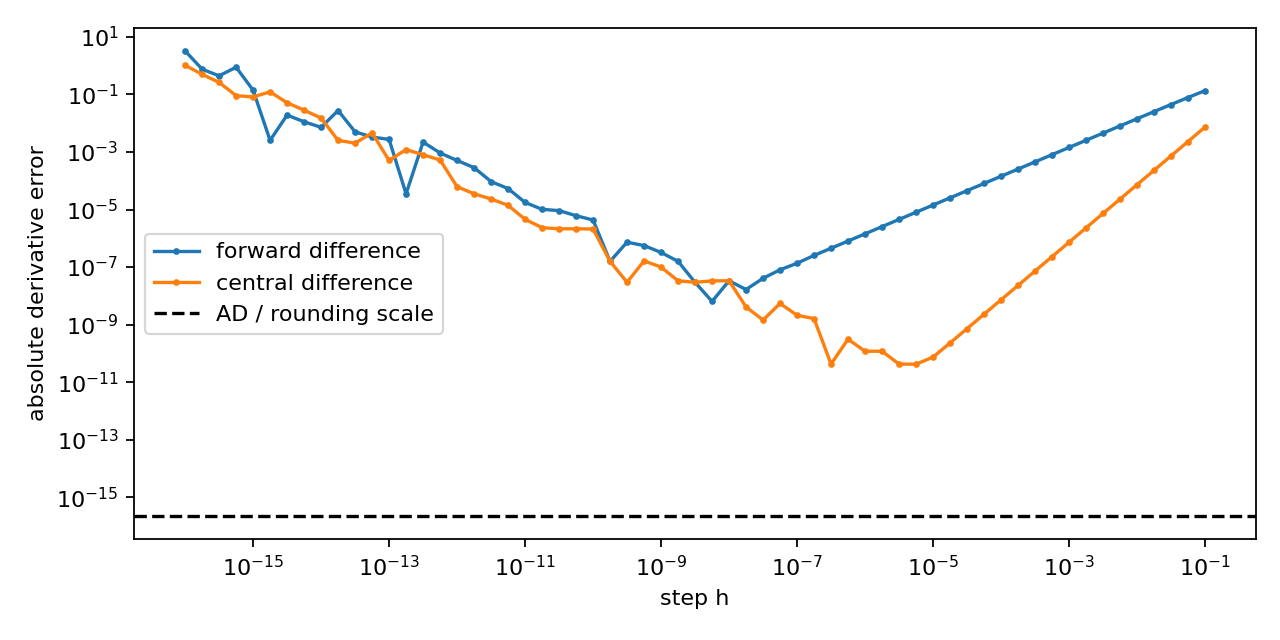

In [8]:
display(Image(filename='G8-附件/ABC共用-图片/experiment-difference-steps.png'))

**实际结果与解释。** $T_4=0.34375,T_8=0.3359375$，误差分别约0.0104167与0.00260417，误差比为1/4；后续实测阶均约2。梯形公式高估凸函数面积。

$F(0.7)\approx2.48437859564$，解析 $F'\approx3.24901870952$，$F''\approx2.85599168388$。Dual与Jet2在本机一阶/二阶结果与上述浮点解析表达式相同，反向一阶差约 $4.44\times10^{-16}$，不能由此称AD“无误差”。差分误差图出现先降后升，小步长的相减抵消使“步长越小越好”的预测失败。图中AD线按机器精度下限画出，避免零误差在对数轴上不可见，并非证明一般误差上界。

**随堂练习。** 用 $x^2$ 的手算积分和 $F$ 的链式法则解释，为何“积分误差为零/很小”不能说明“导数算法正确”。

## 丙：A2 2.3.2–2.3.3 自动微分

- 源文件：`B1组验证结果\B1组-A2自动微分-验证.ipynb`
- 只保留 A2 §2.3.2–2.3.3 单元（setup + 实验2.3-B 与解释）；其余章节单元已删除。

In [1]:
from pathlib import Path
import sys, platform, json, csv, time
import numpy as np
import torch
from torch import nn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / 'A2组-实验.ipynb').exists(), '请在Notebook所在目录运行。'
FIG = ROOT / '图片'; DATA = ROOT / '数据'
FIG.mkdir(exist_ok=True); DATA.mkdir(exist_ok=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(2026)
np.random.seed(2026)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'figure.dpi':110})
ENV = dict(python=sys.version.split()[0], numpy=np.__version__, torch=torch.__version__,
           matplotlib=matplotlib.__version__, system=platform.system(), machine=platform.machine(),
           device='CPU', dtype='float64', threads=1, seed=2026)
print(json.dumps(ENV, ensure_ascii=False, indent=2))
METRICS = {'environment':ENV}
def save_csv(name, rows):
    with (DATA / name).open('w', encoding='utf-8-sig', newline='') as f:
        w=csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
def showfig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=180, bbox_inches='tight')
    display(fig); plt.close(fig)

{
  "python": "3.12.10",
  "numpy": "2.5.4",
  "torch": "2.14.1+cpu",
  "matplotlib": "3.11.2",
  "system": "Windows",
  "machine": "AMD64",
  "device": "CPU",
  "dtype": "float64",
  "threads": 1,
  "seed": 2026
}


### 实验2.3-B：同一计算过程的三条求导路线

$F(x)=\sin(x^2)+e^x$，$F'(x)=2x\cos(x^2)+e^x$。
在 $x=0.7$ 比较PyTorch反向AD、手算解析式与中心差分。
步长 $h=10^{-1},\ldots,10^{-16}$；参考与AD差异要求 $<10^{-12}$。
差分不要求所有步长都合格；观察截断误差与舍入误差的竞争。
补充在 $[-1,1]$ 的201点网格核对AD，避免只检验一个点。

解析参考=3.2490187095246466e+00; AD=3.2490187095246466e+00; 差异=0.000e+00
201点网格AD最大误差=4.441e-16
 h             central_difference        abs_error
1e-01   3.2417166809463027e+00   7.302029e-03
1e-02   3.2489460289622629e+00   7.268056e-05
1e-03   3.2490179827533439e+00   7.267713e-07
1e-04   3.2490187022560235e+00   7.268623e-09
1e-05   3.2490187094502683e+00   7.437828e-11
1e-06   3.2490187094058598e+00   1.187868e-10
1e-07   3.2490187074074584e+00   2.117188e-09
1e-08   3.2490187429345951e+00   3.340995e-08
1e-09   3.2490186097078322e+00   9.981681e-08
1e-10   3.2490166113063879e+00   2.098218e-06
1e-11   3.2490232726445356e+00   4.563120e-06
1e-12   3.2489566592630581e+00   6.205026e-05
1e-13   3.2485125700532080e+00   5.061395e-04
1e-14   3.2640556923979602e+00   1.503698e-02
1e-15   3.3306690738754692e+00   8.165036e-02
1e-16   2.2204460492503131e+00   1.028573e+00


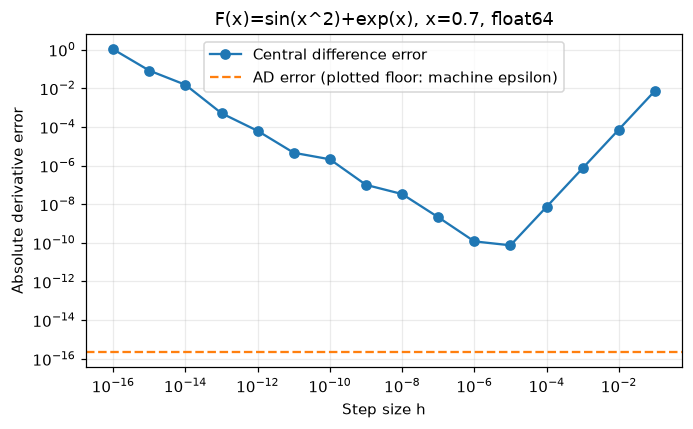

In [3]:
def f_numpy(x): return np.sin(x*x)+np.exp(x)
def fprime_numpy(x): return 2*x*np.cos(x*x)+np.exp(x)
x0=0.7
xt=torch.tensor(x0, requires_grad=True)
yt=torch.sin(xt**2)+torch.exp(xt)
ad=torch.autograd.grad(yt,xt)[0].item()
reference=float(fprime_numpy(x0))
hs=10.**(-np.arange(1,17,dtype=float))
diff_rows=[]
for h in hs:
    df=float((f_numpy(x0+h)-f_numpy(x0-h))/(2*h))
    diff_rows.append(dict(h=float(h), central_difference=df,
                          abs_error=abs(df-reference)))
grid=torch.linspace(-1,1,201,requires_grad=True)
gv=torch.sin(grid**2)+torch.exp(grid)
gd=torch.autograd.grad(gv,grid,grad_outputs=torch.ones_like(gv))[0]
grid_ad_error=float(np.max(np.abs(gd.detach().numpy()-fprime_numpy(grid.detach().numpy()))))
print(f'解析参考={reference:.16e}; AD={ad:.16e}; 差异={abs(ad-reference):.3e}')
print(f'201点网格AD最大误差={grid_ad_error:.3e}')
print(' h             central_difference        abs_error')
for r in diff_rows: print(f"{r['h']:.0e}   {r['central_difference']:.16e}   {r['abs_error']:.6e}")
assert abs(ad-reference)<1e-12 and grid_ad_error<1e-12
save_csv('A2组-差分步长.csv',diff_rows)
METRICS['differentiation']=dict(x=x0,reference=reference,ad=ad,ad_error=abs(ad-reference),
                               grid_ad_error=grid_ad_error,central_difference=diff_rows)
fig,ax=plt.subplots(figsize=(6.4,4))
ax.loglog(hs,[r['abs_error'] for r in diff_rows],'o-',label='Central difference error')
ax.axhline(max(abs(ad-reference),np.finfo(float).eps),ls='--',c='C1',
           label='AD error (plotted floor: machine epsilon)')
ax.set(xlabel='Step size h',ylabel='Absolute derivative error',title='F(x)=sin(x^2)+exp(x), x=0.7, float64')
ax.grid(True,which='both',alpha=.25);ax.legend()
showfig(fig,'A2组-差分步长.png')

**解释**：上述积分误差来自分段直线替代曲线；差分误差来自差商截断与浮点相减。
AD使用原计算图的局部导数，不选差分步长。数值恰巧相等仅表示此例在所用精度下吻合，不表示AD消除了所有舍入误差。

## 2.4 AI关联：神经网络逼近与PINN求导
### 实验2.4-A：小网络拟合与独立导数评价

目标 $g(x)=\sin(\pi x)$，$g'=\pi\cos(\pi x)$，$g''=-\pi^2\sin(\pi x)$。
训练41个等距点；测试400个均匀小区间的中点，与训练点严格不重合；端点单独检查。
网络为1–32–32–1、两层tanh；只最小化函数值MSE，不给导数标签，不使用PDE残差训练。
训练方案在测试前固定。函数值达到最大绝对误差 $10^{-2}$ 视为此教学拟合达到幅值1的百分之一；
此阈值不用于宣称PINN达标。一、二阶导数与残差只如实报告。

## 丁：A1 2.5 网络逼近与求导

- 源文件：`B1组验证结果\B1组-A1网络逼近-验证.ipynb`
- 保留 setup（模块定义 + 导入）与 A1 §2.5 及其 B1 独立验算单元；删除 2.1–2.4 单元。

> 说明（M-06）：下面这个代码单元只定义本章模块（docstring + import + 临时文件写入），**无预期输出**；已执行（execution_count 有值），不是漏跑。

In [1]:
"""Chapter 2 reproducible experiments. NumPy float64; teaching AD, no AD framework.

Graph supports elementwise arrays for batching, and its scalar-output reverse pass
is the same chain rule as a scalar computational graph. No symbolic rewriting.
"""
from pathlib import Path
import os, tempfile
# A literal '/tmp' becomes '<drive>:\tmp' on Windows, so take the platform
# temporary directory instead of assuming a POSIX root.
# B1: 使用系统已有Matplotlib缓存，不新建课程文件夹。
import json, platform, time, importlib.metadata, hashlib, sys, numbers
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT = Path.cwd()
FIG = ROOT
SEED = 2026


def barycentric_weights(nodes):
    x = np.asarray(nodes, dtype=float)
    if x.ndim != 1 or x.size < 1 or not np.all(np.isfinite(x)):
        raise ValueError('nodes must be a finite nonempty 1-D array')
    delta = x[:, None] - x[None, :]
    np.fill_diagonal(delta, 1.)
    if np.any(delta == 0):
        raise ValueError('nodes must be distinct')
    # Common logarithmic scaling prevents products from over/underflowing.
    logw = -np.sum(np.log(np.abs(delta)), axis=1)
    return np.prod(np.sign(delta), axis=1) * np.exp(logw - logw.max())


def barycentric_evaluate(nodes, values, points):
    x, y, z = map(lambda a: np.asarray(a, dtype=float), (nodes, values, points))
    w = barycentric_weights(x)
    if y.shape != x.shape or not np.all(np.isfinite(y)) or not np.all(np.isfinite(z)):
        raise ValueError('finite values must match nodes; finite evaluation points required')
    flat = z.ravel()
    d = flat[:, None] - x[None, :]
    hit = d == 0
    safe = np.where(hit, 1., d)
    terms = w / safe
    # Node values are assigned directly, never as an inf/inf quotient.
    exact = hit.any(axis=1)
    out = np.empty(flat.size)
    out[~exact] = (terms[~exact] @ y) / terms[~exact].sum(axis=1)
    out[exact] = y[np.argmax(hit[exact], axis=1)]
    return out.reshape(z.shape)


def lagrange_direct(nodes, values, points):
    x, y, z = np.asarray(nodes), np.asarray(values), np.asarray(points)
    out = np.zeros_like(z, dtype=float)
    for j in range(len(x)):
        basis = np.ones_like(z, dtype=float)
        for k in range(len(x)):
            if k != j:
                basis *= (z-x[k])/(x[j]-x[k])
        out += y[j]*basis
    return out


def poly_design(points, degree, basis='power', interval=(-1., 1.)):
    x = np.asarray(points, dtype=float)
    a, b = interval
    # degrees are integers, not floats or booleans.
    if (isinstance(degree, bool) or not isinstance(degree, numbers.Integral)
            or degree < 0 or not b > a or x.ndim != 1 or not np.all(np.isfinite(x))):
        raise ValueError('finite vector, nonnegative integer degree and a<b required')
    degree = int(degree)
    t = (2*x-a-b)/(b-a)
    if basis == 'power':
        return np.vander(t, degree+1, increasing=True)
    if basis != 'chebyshev':
        raise ValueError('unknown basis')
    A = np.ones((len(t), degree+1))
    if degree:
        A[:, 1] = t
    for k in range(1, degree):
        A[:, k+1] = 2*t*A[:, k]-A[:, k-1]
    return A


def fit_polynomial(x, y, degree, basis='power', interval=(-1., 1.)):
    A = poly_design(x, degree, basis, interval)
    y = np.asarray(y, dtype=float)
    if y.shape != (len(x),) or not np.all(np.isfinite(y)):
        raise ValueError('finite data must match samples')
    c, _, rank, _ = np.linalg.lstsq(A, y, rcond=None)
    if rank < degree+1:
        raise ValueError('rank deficient design: coefficients are not unique')
    return c, A


class Dual:
    """First order forward AD: value and directional derivative."""
    def __init__(self, value, d=0.): self.value, self.d = np.asarray(value), np.asarray(d)
    @staticmethod
    def lift(x): return x if isinstance(x, Dual) else Dual(x)
    def __add__(self, other):
        b=self.lift(other); return Dual(self.value+b.value, self.d+b.d)
    __radd__=__add__
    def __mul__(self, other):
        b=self.lift(other); return Dual(self.value*b.value, self.d*b.value+self.value*b.d)
    __rmul__=__mul__
    def sin(self): return Dual(np.sin(self.value), np.cos(self.value)*self.d)
    def exp(self):
        e=np.exp(self.value); return Dual(e,e*self.d)
    def tanh(self):
        t=np.tanh(self.value); return Dual(t,(1-t*t)*self.d)


class Jet2:
    """Second order forward AD; d2 is the derivative, not Taylor coefficient."""
    def __init__(self, value, d=0., d2=0.):
        self.value,self.d,self.d2=map(np.asarray,(value,d,d2))
    @staticmethod
    def lift(x): return x if isinstance(x,Jet2) else Jet2(x)
    def __add__(self,other):
        b=self.lift(other);return Jet2(self.value+b.value,self.d+b.d,self.d2+b.d2)
    __radd__=__add__
    def __mul__(self,other):
        b=self.lift(other)
        return Jet2(self.value*b.value,self.d*b.value+self.value*b.d,
                    self.d2*b.value+2*self.d*b.d+self.value*b.d2)
    __rmul__=__mul__
    def sin(self):
        v=self.value;return Jet2(np.sin(v),np.cos(v)*self.d,np.cos(v)*self.d2-np.sin(v)*self.d**2)
    def exp(self):
        e=np.exp(self.value);return Jet2(e,e*self.d,e*(self.d2+self.d**2))
    def tanh(self):
        t=np.tanh(self.value);s=1-t*t
        return Jet2(t,s*self.d,s*self.d2-2*t*s*self.d**2)


def _unbroadcast(gradient, shape):
    g=np.asarray(gradient)
    while g.ndim>len(shape): g=g.sum(axis=0)
    for axis,size in enumerate(shape):
        if size==1: g=g.sum(axis=axis,keepdims=True)
    return g.reshape(shape)


class Graph:
    """Auditable reverse AD; batch arrays, scalar loss, accumulated gradients."""
    def __init__(self, value, parents=()):
        self.value=np.asarray(value,dtype=np.float64)
        self.parents=parents;self.grad=np.zeros_like(self.value)
    @staticmethod
    def lift(x): return x if isinstance(x,Graph) else Graph(x)
    def __add__(self,other):
        b=self.lift(other)
        return Graph(self.value+b.value,((self,lambda g:_unbroadcast(g,self.value.shape)),
                                        (b,lambda g:_unbroadcast(g,b.value.shape))))
    __radd__=__add__
    def __mul__(self,other):
        b=self.lift(other)
        return Graph(self.value*b.value,((self,lambda g:_unbroadcast(g*b.value,self.value.shape)),
                                        (b,lambda g:_unbroadcast(g*self.value,b.value.shape))))
    __rmul__=__mul__
    def __neg__(self): return self*(-1.)
    def __sub__(self,other): return self+(-self.lift(other))
    def tanh(self):
        t=np.tanh(self.value);return Graph(t,((self,lambda g:g*(1-t*t)),))
    def sin(self): return Graph(np.sin(self.value),((self,lambda g:g*np.cos(self.value)),))
    def exp(self):
        e=np.exp(self.value);return Graph(e,((self,lambda g:g*e),))
    def sum(self,axis=None):
        def pull(g):
            return np.ones_like(self.value)* (np.expand_dims(g,axis) if axis is not None else g)
        return Graph(self.value.sum(axis=axis),((self,pull),))
    def mean(self): return self.sum()*(1./self.value.size)
    def backward(self):
        if self.value.ndim!=0: raise ValueError('backward requires scalar output')
        order=[];seen=set()
        def visit(node):
            if id(node) not in seen:
                seen.add(id(node))
                for parent,_ in node.parents: visit(parent)
                order.append(node)
        visit(self)
        for node in order:node.grad=np.zeros_like(node.value)
        self.grad=np.ones_like(self.value)
        for node in reversed(order):
            for parent,pull in node.parents:parent.grad+=pull(node.grad)


def composite(x): return (x*x).sin()+x.exp()

def network_graph(x, params):
    a,w,b,c=params
    return (a*(Graph(np.asarray(x)[:,None])*w+b).tanh()).sum(axis=1)+c


def network_analytic(x,params):
    a,w,b,c=params
    t=np.tanh(np.asarray(x)[:,None]*w+b);s=1-t*t
    return c+(a*t).sum(axis=1),(a*w*s).sum(axis=1),(-2*a*w*w*t*s).sum(axis=1)


def network_jet(x,params):
    a,w,b,c=params
    out=Jet2(np.zeros_like(x)+c)
    xx=Jet2(x, np.ones_like(x))
    for aj,wj,bj in zip(a,w,b):out=out+aj*(wj*xx+bj).tanh()
    return out.value,out.d,out.d2


def network_loss(params,x,y):
    nodes=[Graph(p) for p in params]
    r=network_graph(x,nodes)-y
    loss=(r*r).mean();loss.backward()
    return float(loss.value),[p.grad.copy() for p in nodes]


def train_network(steps=14000,width=12):
    rng=np.random.default_rng(SEED)
    x=np.linspace(-1.,1.,81);y=np.sin(np.pi*x)
    params=[rng.normal(0.,.3,width),rng.normal(0.,1.,width),rng.normal(0.,.4,width),np.array(0.)]
    m=[np.zeros_like(p) for p in params];v=[np.zeros_like(p) for p in params]
    history=[];start=time.perf_counter()
    for step in range(1,steps+1):
        loss,grads=network_loss(params,x,y)
        # Deliberate two-stage learning-rate schedule, fixed before evaluation.
        rate=.01 if step<=8000 else .002
        for j,g in enumerate(grads):
            m[j]=.9*m[j]+.1*g;v[j]=.999*v[j]+.001*g*g
            params[j]-=rate*(m[j]/(1-.9**step))/(np.sqrt(v[j]/(1-.999**step))+1e-8)
        if step==1 or step%200==0:history.append([step,loss])
    final,_=network_loss(params,x,y)
    return params,x,y,history,final,time.perf_counter()-start


_B1_IMAGES = {}
def _savefig(name):
    from io import BytesIO
    mapping = {'experiment-network-derivatives.png':'B1组-A1网络逼近-网络与导数.png',
               'experiment-network-loss.png':'B1组-A1网络逼近-训练损失.png',
               'experiment-high-frequency.png':'B1组-A1网络逼近-高频反例.png'}
    plt.tight_layout()
    buffer = BytesIO(); plt.savefig(buffer,format='png',dpi=160)
    _B1_IMAGES[name] = buffer.getvalue()
    if name in mapping: (ROOT / mapping[name]).write_bytes(buffer.getvalue())
    plt.close()


def interpolation_experiment():
    f=lambda x:1/(1+25*x*x)
    z=-1+2*(np.arange(6001)+.371)/6001
    rows=[];plt.figure(figsize=(9,4))
    for n in (8,16,32):
        for kind in ('equispaced','Chebyshev zeros'):
            x=np.linspace(-1,1,n+1) if kind=='equispaced' else np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2))
            y=f(x);p=barycentric_evaluate(x,y,z)
            assert np.array_equal(barycentric_evaluate(x,y,x),y)
            err=float(np.max(np.abs(p-f(z))))
            rows.append(dict(n=n,nodes=kind,grid_max_error=err,node_max_error=0.))
            plt.semilogy(z,np.maximum(abs(p-f(z)),1e-17),label=f'{kind}, n={n}')
    plt.xlabel('x');plt.ylabel('absolute error');plt.legend(fontsize=7,ncol=2)
    _savefig('experiment-runge-errors.png')
    plt.figure(figsize=(9,4))
    plt.plot(z,f(z),'k',label='Runge function')
    for kind in ('equispaced','Chebyshev zeros'):
        n=16;x=np.linspace(-1,1,n+1) if kind=='equispaced' else np.cos((2*np.arange(n+1)+1)*np.pi/(2*n+2))
        plt.plot(z,barycentric_evaluate(x,f(x),z),label=kind);plt.plot(x,f(x),'o',ms=3)
    plt.ylim(-1.5,2);plt.xlabel('x');plt.ylabel('value');plt.legend();_savefig('experiment-runge-nodes.png')
    x=np.array([-1.,0.,1.]);q=lambda z:2*z*z-z+3
    checks=np.array([-.73,.23,.89])
    np.testing.assert_allclose(barycentric_evaluate(x,q(x),checks),q(checks),atol=3e-15,rtol=3e-15)
    np.testing.assert_allclose(lagrange_direct(x,q(x),checks),q(checks),atol=3e-15,rtol=3e-15)
    bad=0
    for xx,yy in [([0.,0.],[1.,2.]),([0.,1.],[1.]),([0.,np.nan],[1.,2.])]:
        try:barycentric_evaluate(xx,yy,[.5])
        except ValueError:bad+=1
    assert bad==3
    return dict(rows=rows,grid_size=len(z),grid='shifted uniform interior grid of [-1,1], offset=.371, exact analytic target',baseline='2x^2-x+3 at three nonnodes; direct Lagrange; 3 invalid inputs rejected')


def least_squares_experiment():
    rng=np.random.default_rng(SEED);x=np.linspace(-1,1,41);truth=lambda t:np.exp(t)
    noise=rng.normal(0.,.015,len(x));y=truth(x)+noise;z=-1+2*(np.arange(2001)+.371)/2001
    rows=[];pred=[]
    for basis in ('power','chebyshev'):
        c,A=fit_polynomial(x,y,12,basis);p=poly_design(z,12,basis)@c;pred.append(p)
        Q,R=np.linalg.qr(A,mode='reduced');cq=np.linalg.solve(R,Q.T@y)
        disagreement=float(np.max(abs(poly_design(z,12,basis)@cq-p)))
        assert disagreement<1e-9
        rows.append(dict(basis=basis,condition_2=float(np.linalg.cond(A)),residual_2=float(np.linalg.norm(A@c-y)),grid_max_error=float(np.max(abs(p-truth(z)))),qr_prediction_max_difference=disagreement))
    basis_difference=float(np.max(abs(pred[0]-pred[1])))
    assert basis_difference<1e-9
    # Independent exact line fit: symmetry gives c0=2, c1=3.
    cs,_=fit_polynomial(np.array([-1.,0.,1.]),np.array([-1.,2.,5.]),1)
    np.testing.assert_allclose(cs,[2.,3.],atol=2e-15,rtol=2e-15)
    try:fit_polynomial(np.array([0.,0.,1.]),np.ones(3),2)
    except ValueError:pass
    else:raise AssertionError('rank deficiency must be reported')
    # Same polynomial space: transformed [100,102] data agree with [-1,1].
    scaled,_=fit_polynomial(x+101,y,12,'chebyshev',(100.,102.))
    np.testing.assert_allclose(poly_design(z+101,12,'chebyshev',(100.,102.))@scaled,pred[1],atol=2e-12,rtol=2e-12)
    plt.figure(figsize=(9,4));plt.plot(x,y,'o',ms=3,label='noisy samples');plt.plot(z,truth(z),'k',label='exp(x)')
    for basis,p in zip(('power','Chebyshev'),pred):plt.plot(z,p,label=f'{basis}, degree 12')
    plt.xlabel('x');plt.ylabel('value');plt.legend();_savefig('experiment-least-squares.png')
    # Overfitting comparison changes degree only, keeping these samples fixed.
    degree_rows=[]
    for d in (3,12,30):
        c,A=fit_polynomial(x,y,d,'chebyshev');p=poly_design(z,d,'chebyshev')@c
        degree_rows.append(dict(degree=d,residual_2=float(np.linalg.norm(A@c-y)),grid_max_error=float(np.max(abs(p-truth(z))))))
    return dict(rows=rows,degree_comparison=degree_rows,samples=41,degree=12,noise_std=.015,basis_prediction_max_difference=basis_difference,normal_equations_solved=False,scaling_interval=[100.,102.],rank_deficient_rejected=True)


def trapezoid_square(n):
    if not isinstance(n,int) or isinstance(n,bool) or n<1:raise ValueError('n must be positive integer')
    x=np.linspace(0.,1.,n+1);y=x*x;h=1./n
    return h*(.5*y[0]+y[1:-1].sum()+.5*y[-1])


def differentiation_experiment():
    rows=[]
    for n in (4,8,16,32,64):
        val=trapezoid_square(n);err=val-1/3
        np.testing.assert_allclose(err,1/(6*n*n),rtol=1e-12,atol=1e-16)
        rows.append(dict(N=n,T_N=val,signed_error_I_minus_T=-err,absolute_error=err))
    x=.7;value=np.sin(x*x)+np.exp(x);d1=2*x*np.cos(x*x)+np.exp(x)
    d2=2*np.cos(x*x)-4*x*x*np.sin(x*x)+np.exp(x)
    dual=composite(Dual(x,1.));jet=composite(Jet2(x,1.));gx=Graph(x);out=composite(gx);out.backward()
    for d in (dual.d,jet.d,gx.grad):np.testing.assert_allclose(d,d1,rtol=2e-15,atol=2e-15)
    np.testing.assert_allclose(jet.d2,d2,rtol=3e-15,atol=3e-15)
    np.testing.assert_allclose(jet.value,value,rtol=2e-15,atol=2e-15)
    hs=np.logspace(-1,-16,61);fun=lambda t:np.sin(t*t)+np.exp(t)
    forward=np.array([(fun(x+h)-fun(x))/h for h in hs]);central=np.array([(fun(x+h)-fun(x-h))/(2*h) for h in hs])
    plt.figure(figsize=(8,4));plt.loglog(hs,abs(forward-d1),'o-',ms=2,label='forward difference');plt.loglog(hs,abs(central-d1),'o-',ms=2,label='central difference');plt.axhline(max(abs(float(dual.d)-d1),np.finfo(float).eps),c='k',ls='--',label='AD / rounding scale')
    plt.xlabel('step h');plt.ylabel('absolute derivative error');plt.legend();_savefig('experiment-difference-steps.png')
    return dict(trapezoid=rows,x=x,F=value,analytic_d1=d1,analytic_d2=d2,dual_d1=float(dual.d),reverse_d1=float(gx.grad),jet_d2=float(jet.d2),manual_reverse=dict(bar_exp=1.,bar_sin=1.,bar_square=float(np.cos(x*x)),bar_x=float(np.exp(x)+2*x*np.cos(x*x))),difference=dict(h=hs.tolist(),forward_error=abs(forward-d1).tolist(),central_error=abs(central-d1).tolist(),best_central_h=float(hs[np.argmin(abs(central-d1))]),best_central_error=float(np.min(abs(central-d1)))))


def network_experiment():
    params,x,y,history,loss,elapsed=train_network()
    z=-1+2*(np.arange(2001)+.371)/2001
    assert np.min(abs(z[:,None]-x[None,:]))>1e-12
    values=network_analytic(z,params);jets=network_jet(z,params)
    checks=[float(np.max(abs(a-b))) for a,b in zip(values,jets)]
    for a,b in zip(values,jets):np.testing.assert_allclose(a,b,atol=3e-13,rtol=3e-13)
    truths=[np.sin(np.pi*z),np.pi*np.cos(np.pi*z),-np.pi**2*np.sin(np.pi*z)]
    errors=[float(np.max(abs(a-b))) for a,b in zip(values,truths)]
    # Directional parameter gradient has an independently written analytic formula.
    L,grads=network_loss(params,x,y);a,w,b,c=params;t=np.tanh(x[:,None]*w+b);r=(c+(a*t).sum(axis=1))-y;s=1-t*t
    analytic=[2*(r[:,None]*t).mean(axis=0),2*(r[:,None]*a*s*x[:,None]).mean(axis=0),2*(r[:,None]*a*s).mean(axis=0),np.array(2*r.mean())]
    gradient_errors=[float(np.max(abs(g-ga))) for g,ga in zip(grads,analytic)]
    for g,ga in zip(grads,analytic):np.testing.assert_allclose(g,ga,atol=3e-14,rtol=3e-12)
    rng=np.random.default_rng(2026);directions=[rng.normal(size=p.shape) for p in params];norm=np.sqrt(sum(np.sum(d*d) for d in directions));directions=[d/norm for d in directions]
    exact_direction=sum(np.sum(g*d) for g,d in zip(grads,directions));h=1e-5
    loss_value=lambda pp:float(np.mean((network_analytic(x,pp)[0]-y)**2))
    diff=(loss_value([p+h*d for p,d in zip(params,directions)])-loss_value([p-h*d for p,d in zip(params,directions)]))/(2*h)
    assert abs(diff-exact_direction)<1e-8
    plt.figure(figsize=(10,7))
    for k in range(3):
        plt.subplot(3,1,k+1);plt.plot(z,truths[k],'k',label='analytic target');plt.plot(z,values[k],label='trained network');plt.ylabel(('u','du/dx','d2u/dx2')[k]);plt.legend(fontsize=7)
    plt.xlabel('x');_savefig('experiment-network-derivatives.png')
    plt.figure(figsize=(8,4));hh=np.array(history);plt.semilogy(hh[:,0],hh[:,1]);plt.xlabel('Adam step');plt.ylabel('training mean square loss');_savefig('experiment-network-loss.png')
    # eps*sin(k*x) has small values and non-small derivatives, independently of fitting.
    k=100;eps=1/k**2
    plt.figure(figsize=(9,4))
    for j,series in enumerate((eps*np.sin(k*z),eps*k*np.cos(k*z),-eps*k*k*np.sin(k*z))):plt.plot(z,series,label=f'error derivative order {j}')
    plt.xlabel('x');plt.ylabel('counterexample error');plt.legend();_savefig('experiment-high-frequency.png')
    relu_h=.01
    relu=lambda v:np.maximum(0.,v)
    relu_away=(relu(np.array([-.7,.6])+relu_h)-2*relu(np.array([-.7,.6]))+relu(np.array([-.7,.6])-relu_h))/relu_h**2
    np.testing.assert_allclose(relu_away,0.,atol=1e-11,rtol=0.)
    relu_kink=[float((relu(h)-2*relu(0.)+relu(-h))/h**2) for h in (.1,.01,.001)]
    np.testing.assert_allclose(relu_kink,[10.,100.,1000.],atol=1e-10,rtol=1e-13)
    return dict(seed=SEED,device='CPU',dtype='float64',width=int(w.size),parameter_count=int(sum(p.size for p in params)),training_points=81,test_points=2001,test_grid='shifted uniform interior grid, offset=.371, disjoint from training points',steps=14000,optimizer='Adam beta1=.9 beta2=.999 eps=1e-8; learning rate .01 for 8000 steps then .002',training_scope='all a,w,b,c jointly; value-only loss',final_loss=loss,train_grid_max_error=float(np.max(abs(network_analytic(x,params)[0]-y))),independent_grid_max_errors=dict(value=errors[0],first_derivative=errors[1],second_derivative=errors[2]),jet_vs_analytic_max_differences=checks,reverse_vs_analytic_parameter_gradient_max_differences=gradient_errors,directional_gradient=dict(reverse=float(exact_direction),central_difference=float(diff),h=h,absolute_difference=float(abs(diff-exact_direction))),history=history,training_seconds=elapsed,params={name:p.tolist() for name,p in zip(('a','w','b','c'),params)},counterexamples=dict(high_frequency=dict(k=k,epsilon=eps,continuous_sup_errors=[eps,eps*k,eps*k*k]),relu=dict(formula='max(0,x): derivative 0 for x<0 and 1 for x>0; not differentiable at 0',second_difference_away=relu_away.tolist(),kink_second_difference=relu_kink,kink_steps=[.1,.01,.001])))


def environment():
    packages={k:importlib.metadata.version(k) for k in ('numpy','matplotlib','nbformat','nbclient','ipykernel','jupyter_client')}
    return dict(python=platform.python_version(),interpreter=sys.executable,module_sha256='9b167046bdf5fb2dabe2e37b4a337e1a164fe97edd4e235bff671a4c2dbc717c',platform=platform.platform(),packages=packages,seed=SEED,dtype='float64',device='CPU',extra_installs=[],ad_implementation='self-contained teaching Dual/Graph/Jet2 in ch2_numerics.py')


def run_all():
    results={'interpolation':interpolation_experiment(),'least_squares':least_squares_experiment(),'differentiation':differentiation_experiment(),'network':network_experiment()}
    (ROOT/'实验结果.json').write_text(json.dumps(results,ensure_ascii=False,indent=2)+'\n')
    (ROOT/'环境版本.json').write_text(json.dumps(environment(),ensure_ascii=False,indent=2)+'\n')
    return results

if False: # 原脚本入口，Notebook逐单元调用
    results=run_all()
    print(json.dumps({k:(v if k!='network' else {kk:vv for kk,vv in v.items() if kk not in ('history','params')}) for k,v in results.items()},ensure_ascii=False,indent=2))


In [2]:
from pathlib import Path
import sys,json,inspect,types
import numpy as np
from IPython.display import display,Image as _IPImage,Code
# 原辅助模块完整内嵌于上一个单元，计算函数与训练配置保留。
cn=types.SimpleNamespace(**globals())
SUPPORT=Path.cwd()
assert sys.version_info[:2]==(3,12), '请使用Python 3.12.x'
def Image(filename=None,**kwargs):
    if filename is not None:
        return _IPImage(data=_B1_IMAGES[Path(filename).name])
    return _IPImage(**kwargs)
print(json.dumps(cn.environment(),ensure_ascii=False,indent=2))
results={}


{
  "python": "3.12.14",
  "interpreter": "C:\\Users\\yzx\\Documents\\Codex\\2026-10-22\\new-chat\\work\\B1-review\\env\\Scripts\\python.exe",
  "module_sha256": "9b167046bdf5fb2dabe2e37b4a337e1a164fe97edd4e235bff671a4c2dbc717c",
  "platform": "Windows-10-10.0.19045-SP0",
  "packages": {
    "numpy": "2.0.1",
    "matplotlib": "3.9.1.post1",
    "nbformat": "5.10.4",
    "nbclient": "0.10.0",
    "ipykernel": "6.29.5",
    "jupyter_client": "8.6.2"
  },
  "seed": 2026,
  "dtype": "float64",
  "device": "CPU",
  "extra_installs": [],
  "ad_implementation": "self-contained teaching Dual/Graph/Jet2 in ch2_numerics.py"
}


## 2.5 网络逼近与求导：值、输入导数与参数梯度

**先作预测。** 只用函数值训练，是否会让一、二阶输入导数同样准确？自动微分给出的导数计算准确，是否意味着它接近目标导数？

**网络定义。** 一个输入、一个输出、12个隐藏单元，
$$u_\theta(x)=c+\sum_{j=1}^{12}a_j\tanh(w_jx+b_j),\qquad\theta=(a,w,b,c)\in\mathbb R^{37}.$$
隐藏单元是“仿射变换 $w_jx+b_j$ 后接激活函数 $\tanh$”，输出为它们的加权和。训练是改变37个实数参数，以减小81个等距点上的平均平方误差；输入导数是固定参数后对 $x$ 求导，二者任务不同。

**真实训练设置。** 目标 $\sin(\pi x)$，区间 $[-1,1]$；种子2026，CPU、float64。全体37参数均训练，值损失 $L=81^{-1}\sum_i(u_\theta(x_i)-\sin(\pi x_i))^2$，没有导数损失。Adam迭代14000次，$\beta_1=0.9,\beta_2=0.999,\epsilon=10^{-8}$；前8000步学习率0.01，其后0.002。学习率在评价前固定。Adam维护梯度的一阶与二阶滑动平均，作偏差修正后更新参数，代码给出全部步骤。

反向Graph支持逐元素批量数组和求和，广播的反向必须沿扩展维度求和；最终输出始终是标量loss。每步重新建立图并清零/累加梯度。以下展示训练循环，完整规则在模块中可检查。

In [10]:
display(Code(inspect.getsource(cn.train_network), language='python'))
results['network'] = cn.network_experiment()
r = results['network']
print(json.dumps({k:r[k] for k in ('seed','width','parameter_count','training_points','test_points','steps','optimizer','training_scope','final_loss','train_grid_max_error','independent_grid_max_errors','training_seconds')}, ensure_ascii=False, indent=2))


def train_network(steps=14000,width=12):
    rng=np.random.default_rng(SEED)
    x=np.linspace(-1.,1.,81);y=np.sin(np.pi*x)
    params=[rng.normal(0.,.3,width),rng.normal(0.,1.,width),rng.normal(0.,.4,width),np.array(0.)]
    m=[np.zeros_like(p) for p in params];v=[np.zeros_like(p) for p in params]
    history=[];start=time.perf_counter()
    for step in range(1,steps+1):
        loss,grads=network_loss(params,x,y)
        # Deliberate two-stage learning-rate schedule, fixed before evaluation.
        rate=.01 if step<=8000 else .002
        for j,g in enumerate(grads):
            m[j]=.9*m[j]+.1*g;v[j]=.999*v[j]+.001*g*g
            params[j]-=rate*(m[j]/(1-.9**step))/(np.sqrt(v[j]/(1-.999**step))+1e-8)
        if step==1 or step%200==0:history.append([step,loss])
    final,_=network_loss(params,x,y)
    return params,x,y,history,final,time.perf_counter()-start

{
  "seed": 2026,
  "width": 12,
  "parameter_count": 37,
  "training_points": 81,
  "test_points": 2001,
  "steps": 14000,
  "optimizer": "Adam beta1=.9 beta2=.999 eps=1e-8; learning rate .01 for 8000 steps then .002",
  "training_scope": "all a,w,b,c jointly; value-only loss",
  "final_loss": 1.0566416815609858e-06,
  "train_grid_max_error": 0.0029083189444616296,
  "independent_grid_max_errors": {
    "value": 0.0028647578849091684,
    "first_derivative": 0.1171684955937482,
    "second_derivative": 1.6469419116608754
  },
  "training_seconds": 3.399541199999476
}


**独立核查。** 测试网格 $z_j=-1+2(j+0.371)/2001$ 与全部训练点均不重合；程序断言最小距离超过 $10^{-12}$。测试真值是一并独立写出的 $\sin(\pi x),\pi\cos(\pi x),-\pi^2\sin(\pi x)$。网格最大绝对误差是有限采样统计量，不是已求出的连续一致范数。

令 $t_j=\tanh(w_jx+b_j),s_j=1-t_j^2$。独立解析网络公式为
$$u_\theta'=\sum_ja_jw_js_j,\qquad u_\theta''=-2\sum_ja_jw_j^2t_js_j.$$
它与Jet2逐层求导互相比对，容差 $3\times10^{-13}$ 覆盖约12项累加舍入；**核查的是真实网络导数计算，不是与目标导数的误差**。

参数梯度再由独立公式 $\partial_{a_j}L=2\operatorname{mean}(rt_j)$、$\partial_{w_j}L=2\operatorname{mean}(ra_js_jx)$、$\partial_{b_j}L=2\operatorname{mean}(ra_js_j)$、$\partial_cL=2\operatorname{mean}(r)$ 核查。绝对容差 $3\times10^{-14}$ 防止近零梯度的相对误差误导；另取单位参数方向与中心差分比较，步长 $10^{-5}$，绝对容差 $10^{-8}$，允许其差分截断和抵消。没有用另一个AD实现充当唯一真值。

Jet2 vs analytic network [value,d1,d2]: [9.992007221626409e-16, 1.7763568394002505e-15, 3.9968028886505635e-15]
reverse vs analytic parameter gradients [a,w,b,c]: [5.421010862427522e-20, 2.710505431213761e-20, 4.0657581468206416e-20, 0.0]
parameter directional check: {'reverse': -7.439810802329849e-05, 'central_difference': -7.439811408383193e-05, 'h': 1e-05, 'absolute_difference': 6.060533436322464e-12}


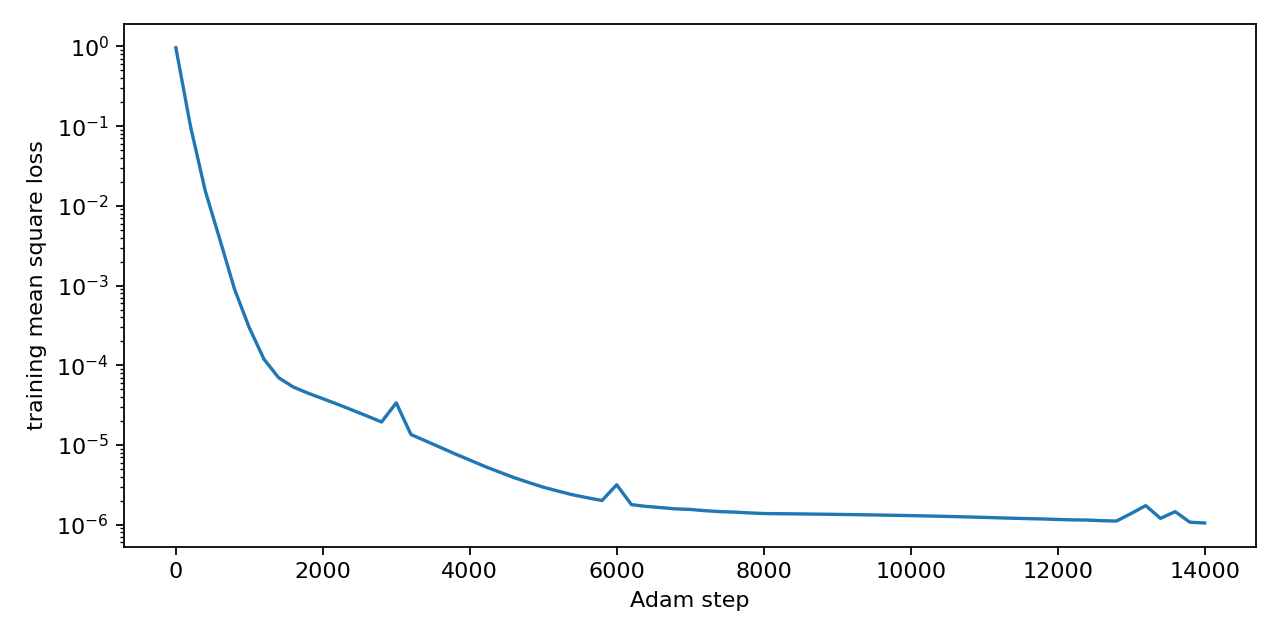

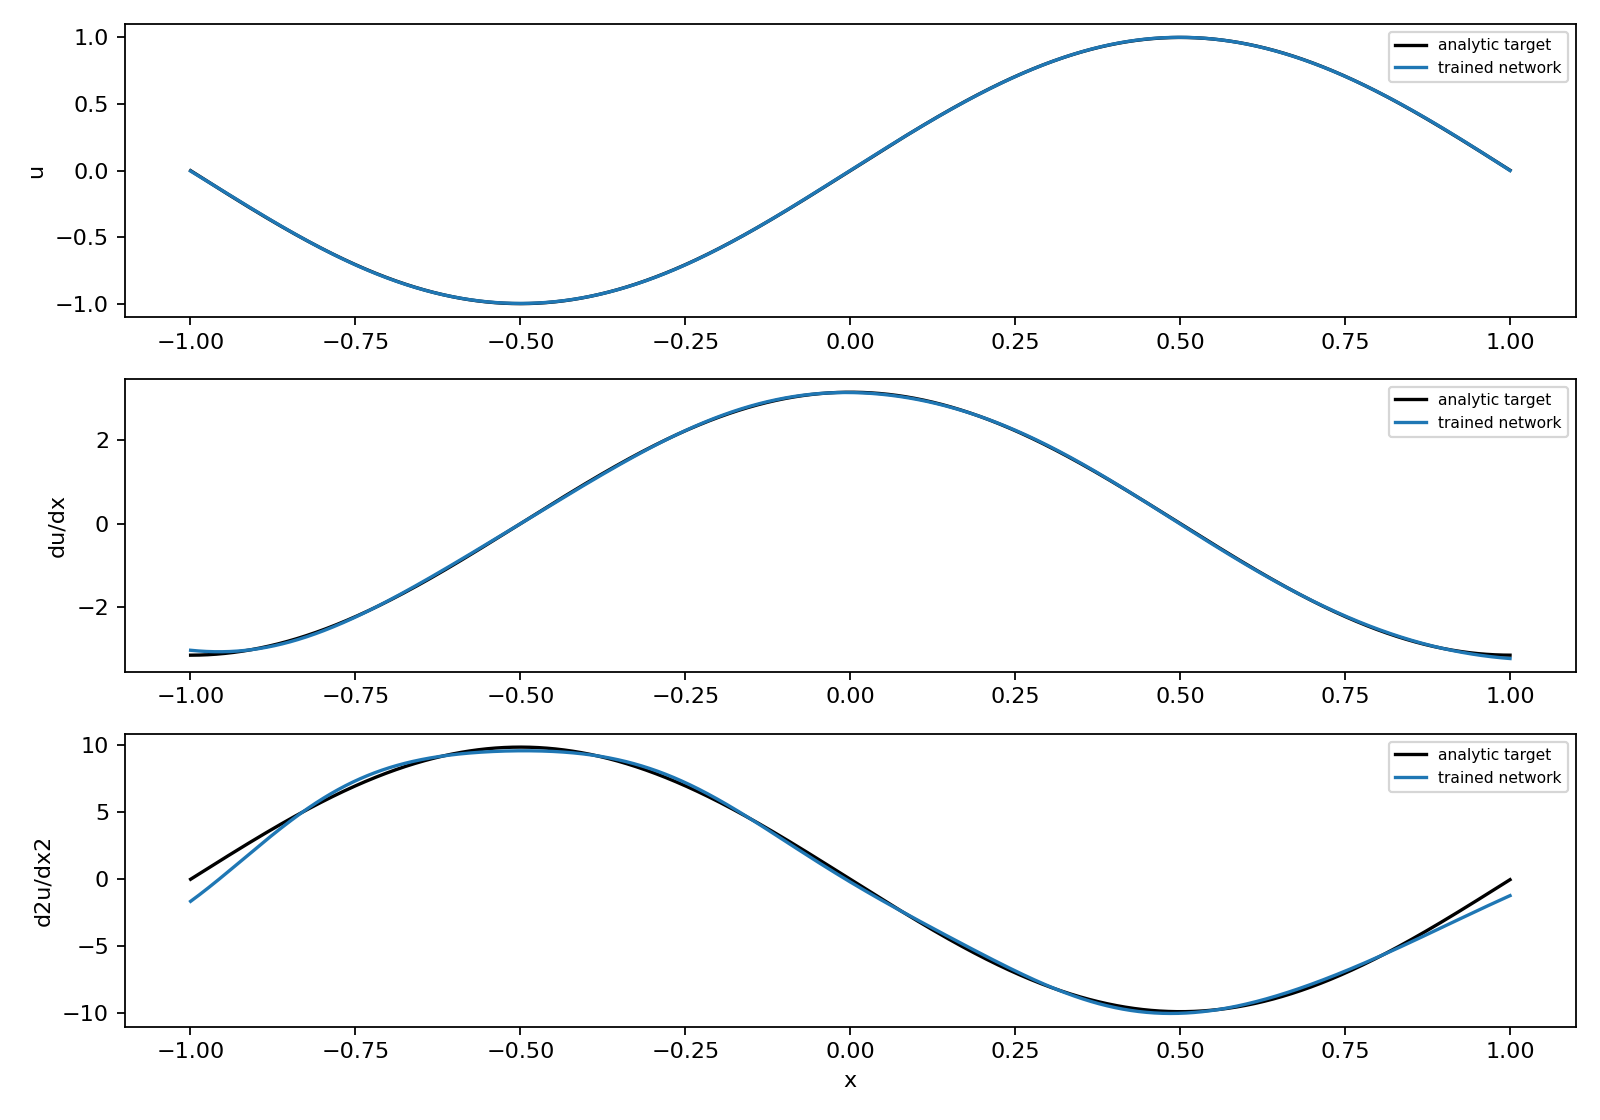

In [11]:
r = results['network']
print('Jet2 vs analytic network [value,d1,d2]:', r['jet_vs_analytic_max_differences'])
print('reverse vs analytic parameter gradients [a,w,b,c]:', r['reverse_vs_analytic_parameter_gradient_max_differences'])
print('parameter directional check:', r['directional_gradient'])
display(Image(filename='G8-附件/ABC共用-图片/experiment-network-loss.png'))
display(Image(filename='G8-附件/ABC共用-图片/experiment-network-derivatives.png'))


**实际结果与局限。** 训练后值损失约 $1.09588\times10^{-6}$，训练点最大误差约0.003055；独立网格上值、一阶导、二阶导的最大绝对误差约0.003011、0.117060、1.64688。它是一次固定种子的小规模真实训练，未作多种子统计或超参数最优性研究。损失曲线可有震荡；仅降低值损失不保证导数误差同步降低。程序每200步保存一次更新前的loss，最终loss另在最后更新后重新计算。

Jet2与网络解析式最大差不超过 $3.56\times10^{-15}$，反向参数梯度与解析式差约 $10^{-19}$，方向差分差约 $6.06\times10^{-12}$。导数算得准确与导数逼近得准确必须区分。训练耗时以本次输出为准，机器、BLAS和平台可能使末位与耗时变化。

**两个可核查的反例。**

1. $\operatorname{ReLU}(x)=\max(0,x)$ 在零点不可微，其他点二阶导为零。在零点用中心二阶差分得到 $1/h$，步长越小越大，不能当作经典二阶导数；在远离零的同一线性段上二阶差分为零。因而强形式二阶微分方程需要额外关注激活光滑性。
2. $u(x)=f(x)+10^{-4}\sin(100x)$ 的函数误差连续上确界为 $10^{-4}$，一阶为0.01，二阶为1。这些值可由解析三角函数和区间内极值点直接证明，表明小振幅高频扰动会放大导数误差。它不是另一次训练结果。

PINN会用输入导数构造方程残差，再对参数求梯度。本实验只准备这两种求导，不进行PDE训练或声称已求解方程。

{
  "high_frequency": {
    "k": 100,
    "epsilon": 0.0001,
    "continuous_sup_errors": [
      0.0001,
      0.01,
      1.0
    ]
  },
  "relu": {
    "formula": "max(0,x): derivative 0 for x<0 and 1 for x>0; not differentiable at 0",
    "second_difference_away": [
      0.0,
      0.0
    ],
    "kink_second_difference": [
      9.999999999999998,
      100.0,
      1000.0000000000001
    ],
    "kink_steps": [
      0.1,
      0.01,
      0.001
    ]
  }
}


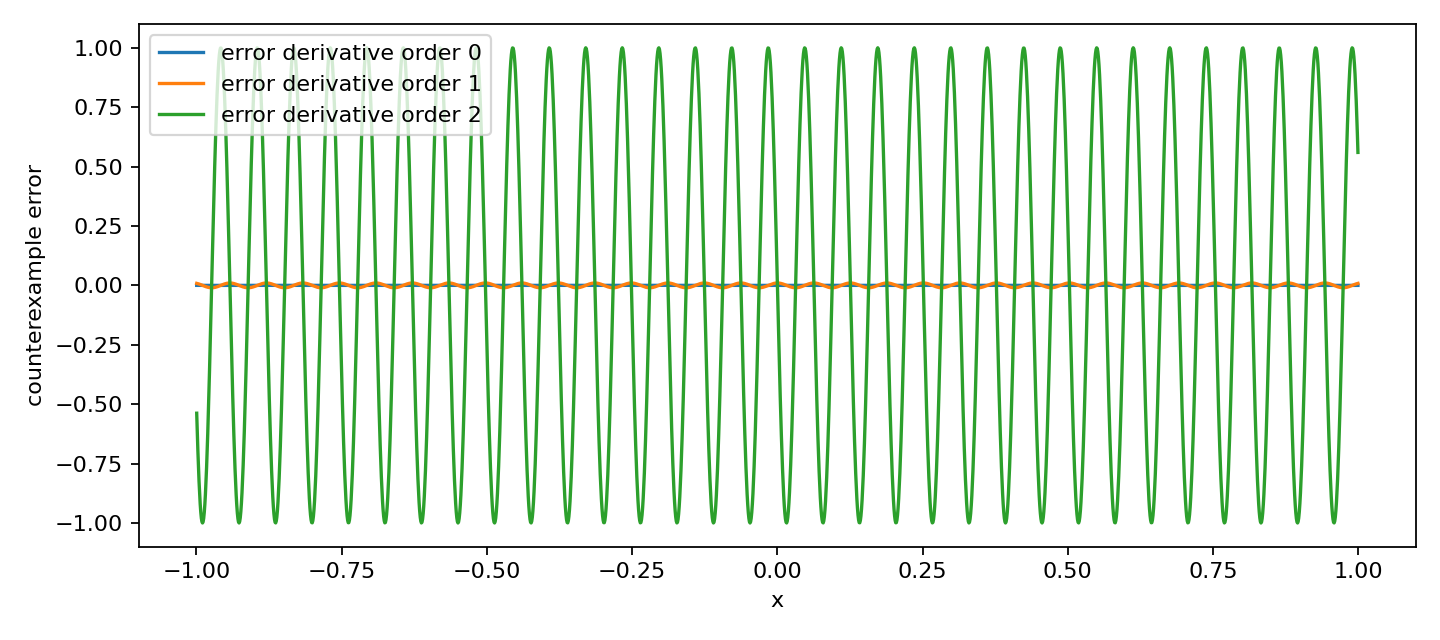

In [12]:
print(json.dumps(results['network']['counterexamples'], ensure_ascii=False, indent=2))
display(Image(filename='G8-附件/ABC共用-图片/experiment-high-frequency.png'))

## 回到开场：用证据回答

对明确给定的 $x^2$，4块变8块梯形的误差变成原来的四分之一，来自精确公式 $1/(6N^2)$，也由本Notebook的数值核查支持；河岸比喻不代表任意不光滑曲线都有同样收敛阶。

有限信息的可靠性由对象、节点/样本、表示、运算与评价量共同决定。插值匹配节点；最小二乘减少给定离散残差；自动微分计算给定程序的导数。它们各自的准确性都不能自动转化为区间内函数、独立数据或高阶导数的准确性。

**练习。** (1) 用实际结果设计一次“增加节点却更差”的判断题；(2) 解释同空间换基和改变次数的区别；(3) 手写 $F$ 的反向累加；(4) 给出值误差趋零但二阶导误差不趋零的函数列。参考答案在本章配套文件。

## 保存、来源与复现范围

导入图与 $x^2$ 梯形起步算法来自课程模板，本次保留其数学内容并增加4/8对照、独立参考与错误输入处理。其余代码及实验图为本章本次编写和实际运行产生，理论文献及原文定位统一见正文参考表与来源核查记录；没有将文献里的曲线伪称为本次结果。

最后一个单元把本次输出写入JSON并记录模块SHA256、解释器和库版本。Notebook依赖同目录模块及图片目录，从空内核顺序执行保存。可用仓库根目录工具 `tools/execute_notebook.py` 重新执行；须用课程指定Python调用该工具。所有断言在本次执行通过，只验证列出的案例与边界，不构成一般数学定理的证明。

In [13]:
(SUPPORT/'B1组-A1网络逼近-本地结果.json').write_text(json.dumps({'environment':cn.environment(),'network':results['network']},ensure_ascii=False,indent=2),encoding='utf-8')
print('完整Notebook顺序运行完成；只导出丁负责的网络实验数据。')

完整Notebook顺序运行完成；只导出丁负责的网络实验数据。


## B1独立验算与原稿数字对照
以上原稿静态说明保留作被审对象，其数字不自动替换为本轮结果。以代码输出和下列独立核对为准。

In [14]:
import csv
from math import tanh,pi,sin,cos
# 不调用A组求导函数，重新以标量表达式核对手算例。
a,w,b,c,x,y=2.,3.,0.,1.,0.,0.
t=tanh(w*x+b);s=1-t*t
sample=[c+a*t,a*w*s,-2*a*w*w*t*s]
gradient=[2*(sample[0]-y)*t,2*(sample[0]-y)*a*s*x,2*(sample[0]-y)*a*s,2*(sample[0]-y)]
assert sample==[1.,6.,0.] and gradient==[0.,0.,4.,2.]
print('独立手算例:',sample,'参数梯度(a,w,b,c):',gradient)
rr=results['network'];pp=rr['params'];xs=-1+2*(np.arange(2001)+.371)/2001
manual=np.array([[pp['c']+sum(aa*tanh(ww*xx+bb) for aa,ww,bb in zip(pp['a'],pp['w'],pp['b'])),
 sum(aa*ww*(1-tanh(ww*xx+bb)**2) for aa,ww,bb in zip(pp['a'],pp['w'],pp['b'])),
 sum(-2*aa*ww**2*tanh(ww*xx+bb)*(1-tanh(ww*xx+bb)**2) for aa,ww,bb in zip(pp['a'],pp['w'],pp['b']))] for xx in xs])
truth=np.column_stack([np.sin(pi*xs),pi*np.cos(pi*xs),-pi*pi*np.sin(pi*xs)])
err=np.max(abs(manual-truth),axis=0)
assert np.max(abs(err-np.array(list(rr['independent_grid_max_errors'].values()))))<1e-11
assert err[0]<5e-3
rows=[{'quantity':q,'max_abs_error':float(err[i]),'rmse':float(np.sqrt(np.mean((manual[:,i]-truth[:,i])**2)))} for i,q in enumerate(['u','du_dx','d2u_dx2'])]
with open('B1组-A1网络逼近-独立误差核对.csv','w',encoding='utf-8-sig',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
print('独立标量计算的误差:',rows)
for k in [2,10,100]:
    witness=pi/(2*k);assert 0<=witness<=1
    np.testing.assert_allclose([abs(sin(k*witness)/k**2),abs(cos(0)/k),abs(sin(k*witness))],[1/k**2,1/k,1],rtol=1e-14)
print('高频见证点检验通过；连续最佳常数的最大误差=1；平均绝对误差=2/pi=',2/pi)
# 连续残差界中的简单非平凡例 v=f+0.3(1-x^2)：M=0.6，eta=0，界取等。
assert abs(0.3-0.6/2)<1e-15
print('残差界常数1/2的取等例通过。')


独立手算例: [1.0, 6.0, -0.0] 参数梯度(a,w,b,c): [0.0, 0.0, 4.0, 2.0]
独立标量计算的误差: [{'quantity': 'u', 'max_abs_error': 0.0028647578849090574, 'rmse': 0.000983128937258394}, {'quantity': 'du_dx', 'max_abs_error': 0.1171684955937482, 'rmse': 0.020757098935332854}, {'quantity': 'd2u_dx2', 'max_abs_error': 1.6469419116608754, 'rmse': 0.3849962684551225}]
高频见证点检验通过；连续最佳常数的最大误差=1；平均绝对误差=2/pi= 0.6366197723675814
残差界常数1/2的取等例通过。


In [15]:
# 对原稿保存权重再评价：与重新训练分开，检查原误差表是否有数值依据。
saved_reference = {'params': {'a': [-0.20325742820395268, -1.0877754156120847, -0.4862351882743994, 0.598899778038808, 0.3093591192413919, -0.1686287784694143, 0.5040899895913984, -1.1659604846350464, -1.16228631158289, 0.0690777514260294, -0.6984322636757218, -1.2314753515316594], 'w': [-0.04820703311754782, 2.5447749344019206, 0.2693175333998367, -0.950494803790416, -0.18534450598223598, 0.37483654391650356, -0.3947133332148003, -2.284220232989256, -2.3892122440053196, 1.0681315948709047, 0.7346360999709722, 1.7788099404837865], 'b': [0.513694850431136, 2.3738861175183867, 0.03934776795387678, 0.9179269125411091, -0.7551759541524486, 0.14247211746032795, 0.004783403494990235, 0.5668570669499501, -0.32852613779057327, 0.042926551777351836, -0.5928201427437104, -1.7507711429479325], 'c': -0.3341248786383958}, 'independent_grid_max_errors': {'value': 0.0028647578849091684, 'first_derivative': 0.1171684955937482, 'second_derivative': 1.6469419116608754}}
p=saved_reference['params']; grid=-1+2*(np.arange(2001)+.371)/2001
z=grid[:,None]*np.array(p['w'])+np.array(p['b']);t=np.tanh(z);s=1-t*t
u=p['c']+np.sum(np.array(p['a'])*t,axis=1)
d1=np.sum(np.array(p['a'])*np.array(p['w'])*s,axis=1)
d2=np.sum(-2*np.array(p['a'])*np.array(p['w'])**2*t*s,axis=1)
fixed_errors=[float(np.max(abs(v-ref))) for v,ref in zip([u,d1,d2],[np.sin(np.pi*grid),np.pi*np.cos(np.pi*grid),-np.pi**2*np.sin(np.pi*grid)])]
np.testing.assert_allclose(fixed_errors,list(saved_reference['independent_grid_max_errors'].values()),atol=1e-12,rtol=1e-12)
print('原稿固定权重复核:',fixed_errors,'与原稿误差表一致。')


原稿固定权重复核: [0.0028647578849091684, 0.1171684955937482, 1.6469419116608754] 与原稿误差表一致。


## 丁：A2 2.4 网络逼近与 PINN 求导

- 源文件：`B1组验证结果\B1组-A2网络逼近-验证.ipynb`
- 保留 setup 与 A2 §2.4 及其 B1 独立复核单元；删除 2.3 单元。

In [1]:
from pathlib import Path
import sys, platform, json, csv, time
import numpy as np
import torch
from torch import nn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / 'B1组-A2网络逼近-验证.ipynb').exists(), '请在Notebook所在目录运行。'
FIG = ROOT; DATA = ROOT
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(2026)
np.random.seed(2026)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'figure.dpi':110})
ENV = dict(python=sys.version.split()[0], numpy=np.__version__, torch=torch.__version__,
           matplotlib=matplotlib.__version__, system=platform.system(), machine=platform.machine(),
           device='CPU', dtype='float64', threads=1, seed=2026)
print(json.dumps(ENV, ensure_ascii=False, indent=2))
METRICS = {'environment':ENV}
def save_csv(name, rows):
    if name in ['A2组-积分收敛.csv','A2组-差分步长.csv']: return
    name=name.replace('A2组-','B1组-A2网络逼近-')
    with (DATA / name).open('w', encoding='utf-8-sig', newline='') as f:
        w=csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
def showfig(fig, name):
    fig.tight_layout()
    if name not in ['A2组-积分收敛.png','A2组-差分步长.png']:
        fig.savefig(FIG / name.replace('A2组-','B1组-A2网络逼近-'), dpi=180, bbox_inches='tight')
    display(fig); plt.close(fig)
assert sys.version_info[:2]==(3,12), '请使用Python 3.12.x'


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\yzx\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


{
  "python": "3.12.14",
  "numpy": "2.5.4",
  "torch": "2.14.1+cpu",
  "matplotlib": "3.11.2",
  "system": "Windows",
  "machine": "AMD64",
  "device": "CPU",
  "dtype": "float64",
  "threads": 1,
  "seed": 2026
}


In [4]:
torch.manual_seed(2026)
model=nn.Sequential(nn.Linear(1,32),nn.Tanh(),nn.Linear(32,32),nn.Tanh(),nn.Linear(32,1))
x_train=torch.linspace(-1,1,41).reshape(-1,1)
y_train=torch.sin(torch.pi*x_train)
x_test_np=-1+(np.arange(400)+0.5)*2/400
assert np.min(np.abs(x_test_np[:,None]-x_train.numpy().ravel()[None,:]))>1e-12
history=[]
t_start=time.perf_counter()
opt=torch.optim.Adam(model.parameters(), lr=1e-3)
for step in range(2000):
    opt.zero_grad()
    loss=((model(x_train)-y_train)**2).mean()
    loss.backward(); opt.step()
    if step%100==0 or step==1999:
        history.append(dict(stage='Adam',step=step+1,mse=float(loss.detach())))
lbfgs=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=400,max_eval=500,
                      tolerance_grad=1e-12,tolerance_change=1e-14,
                      history_size=50,line_search_fn='strong_wolfe')
closure_count=0
def closure():
    global closure_count
    lbfgs.zero_grad()
    loss=((model(x_train)-y_train)**2).mean()
    loss.backward(); closure_count+=1
    if closure_count%20==0:
        history.append(dict(stage='LBFGS',step=closure_count,mse=float(loss.detach())))
    return loss
lbfgs.step(closure)
elapsed=time.perf_counter()-t_start
train_mse=float(((model(x_train)-y_train)**2).mean().detach())
print(f'参数数={sum(p.numel() for p in model.parameters())}; CPU训练秒数={elapsed:.3f}')
print(f'最终训练MSE={train_mse:.6e}; LBFGS闭包次数={closure_count}')
save_csv('A2组-训练过程.csv',history)

参数数=1153; CPU训练秒数=1.953
最终训练MSE=4.531031e-08; LBFGS闭包次数=471


In [5]:
def input_derivatives(model, values):
    x=torch.tensor(values,dtype=torch.float64).reshape(-1,1).requires_grad_(True)
    y=model(x)
    dy=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    d2y=torch.autograd.grad(dy,x,torch.ones_like(dy),create_graph=True)[0]
    return x,y,dy,d2y

x_test,u,ux,uxx=input_derivatives(model,x_test_np)
pred=[v.detach().numpy().ravel() for v in (u,ux,uxx)]
truth=[np.sin(np.pi*x_test_np),np.pi*np.cos(np.pi*x_test_np),
       -np.pi**2*np.sin(np.pi*x_test_np)]
names=['u','du_dx','d2u_dx2']; eval_rows=[]
for name,p,t in zip(names,pred,truth):
    eval_rows.append(dict(quantity=name,max_abs_error=float(np.max(np.abs(p-t))),
                          rmse=float(np.sqrt(np.mean((p-t)**2))),
                          relative_l2=float(np.linalg.norm(p-t)/np.linalg.norm(t))))
print(' quantity        max_abs_error       RMSE               relative_L2')
for r in eval_rows: print(f"{r['quantity']:12s} {r['max_abs_error']:.8e}   {r['rmse']:.8e}   {r['relative_l2']:.8e}")
assert eval_rows[0]['max_abs_error']<1e-2, '如失败，记录真实训练结果而非修改测试点。'
save_csv('A2组-网络误差.csv',eval_rows)

# 对相同已训练权重，用NumPy另写链式法则；不调用torch.autograd。
layers=[model[0],model[2],model[4]]
weights=[(layer.weight.detach().numpy(),layer.bias.detach().numpy()) for layer in layers]
z=x_test_np[:,None]; dz=np.ones_like(z); d2z=np.zeros_like(z)
for k,(w,b) in enumerate(weights):
    a=z@w.T+b; da=dz@w.T; d2a=d2z@w.T
    if k<2:
        z=np.tanh(a); s=1-z*z
        dz=s*da; d2z=s*d2a-2*z*s*da*da
    else:
        z,dz,d2z=a,da,d2a
manual_errors=[float(np.max(np.abs(a.ravel()-b))) for a,b in zip((z,dz,d2z),pred)]
assert max(manual_errors)<1e-10
print('NumPy链式法则 vs AD 最大差异(u, ux, uxx):',manual_errors)

# 仅评价一维Poisson残差，不以它更新权重。
# -u_xx = pi^2 sin(pi*x), x in (-1,1); u(-1)=u(1)=0。
r=-pred[2]-np.pi**2*np.sin(np.pi*x_test_np)
residual_rmse=float(np.sqrt(np.mean(r*r)))
boundary=model(torch.tensor([[-1.],[1.]])).detach().numpy().ravel()
print(f'Poisson残差RMSE={residual_rmse:.8e}; 边界预测={boundary}')
# 确认二阶输入导数的图仍可对参数传播；这里不进行残差优化。
res_loss=((-uxx-torch.pi**2*torch.sin(torch.pi*x_test))**2).mean()
parameter_grads=torch.autograd.grad(res_loss,tuple(model.parameters()),allow_unused=True)
grad_norm=float(torch.sqrt(sum((v*v).sum() for v in parameter_grads if v is not None)))
print(f'残差损失参数梯度范数={grad_norm:.8e}; 不依赖的参数组数={sum(v is None for v in parameter_grads)}')
assert np.isfinite(grad_norm)

METRICS['network']=dict(architecture='1-32-32-1, tanh',parameters=1153,train_points=41,
    test_points=400,train_mse=train_mse,adam_steps=2000,lbfgs_max_iter=400,
    lbfgs_closures=closure_count,seconds=elapsed,errors=eval_rows,
    ad_manual_errors=manual_errors,poisson_residual_rmse=residual_rmse,
    boundary_values=boundary.tolist(),residual_parameter_gradient_norm=grad_norm)
save_csv('A2组-测试点与导数.csv',[
    dict(x=float(x),u=float(a),ux=float(b),uxx=float(c),target=float(t),
         target_dx=float(d),target_dxx=float(e),residual=float(rr))
    for x,a,b,c,t,d,e,rr in zip(x_test_np,*pred,*truth,r)])
torch.save(model.state_dict(),DATA/'B1组-A2网络逼近-网络权重.pt')
fig,axs=plt.subplots(2,3,figsize=(12,6.4))
labels=['Function u','First derivative du/dx','Second derivative d2u/dx2']
for j in range(3):
    axs[0,j].plot(x_test_np,truth[j],label='Analytic target',lw=2)
    axs[0,j].plot(x_test_np,pred[j],'--',label='Fitted network')
    if j==0: axs[0,j].scatter(x_train.numpy(),y_train.numpy(),s=9,c='k',label='41 training points')
    axs[0,j].set(title=labels[j],xlabel='x (dimensionless)',ylabel=names[j]);axs[0,j].legend(fontsize=7)
    axs[1,j].plot(x_test_np,np.abs(pred[j]-truth[j]))
    axs[1,j].set(xlabel='x (dimensionless)',ylabel='Absolute error')
    for i in range(2):axs[i,j].grid(alpha=.25)
showfig(fig,'A2组-网络与导数.png')

 quantity        max_abs_error       RMSE               relative_L2
u            4.13572517e-04   2.14062490e-04   3.02730076e-04
du_dx        1.52329657e-02   4.26425630e-03   1.91958976e-03
d2u_dx2      3.56369788e-01   9.23991851e-02   1.32398600e-02
NumPy链式法则 vs AD 最大差异(u, ux, uxx): [4.440892098500626e-16, 1.3322676295501878e-15, 5.329070518200751e-15]
Poisson残差RMSE=9.23991851e-02; 边界预测=[-1.48923521e-04  4.52174550e-05]
残差损失参数梯度范数=5.22546380e-01; 不依赖的参数组数=1


<Figure size 1320x704 with 6 Axes>

### 实验2.4-B：可控反例与激活函数光滑性

教学构造 $v_k(x)=\sin(\pi x)+k^{-1}\sin(kx)$，$k=10,100,1000$。
虽然函数最大误差不超过 $1/k$，但导数差在 $x=0$ 恰为1；二阶导数差在 $x=\pi/(2k)$ 的大小恰为 $k$。
这是在指定位置的解析反例，不冒充网络训练输出；有限网格不保证找到全区间最大值。

另考察 $v(x)=\mathrm{ReLU}(x)$。在非零点AD二阶导数为0，在0点经典一阶导数不存在；框架在0返回的约定值不是经典导数存在的证明。

In [6]:
counter_rows=[]
for k in [10,100,1000]:
    x_witness=np.pi/(2*k)
    value_error=abs(np.sin(k*x_witness)/k)
    first_error_at_zero=abs(np.cos(0.))
    second_error_at_witness=abs(-k*np.sin(k*x_witness))
    counter_rows.append(dict(k=k,value_error_at_witness=float(value_error),
                             first_error_at_zero=float(first_error_at_zero),
                             second_error_at_witness=float(second_error_at_witness)))
print('高频扰动反例:',json.dumps(counter_rows,ensure_ascii=False))
rx=torch.tensor([-0.5,0.,0.5],requires_grad=True)
ry=torch.relu(rx)
rd=torch.autograd.grad(ry,rx,torch.ones_like(ry),create_graph=True)[0]
rdd=torch.autograd.grad(rd,rx,torch.ones_like(rd))[0]
print('ReLU x:',rx.detach().numpy(),' 框架一阶:',rd.detach().numpy(),' 框架二阶:',rdd.detach().numpy())
assert torch.equal(rdd,torch.zeros_like(rdd))
METRICS['counterexample']=counter_rows
save_csv('A2组-高频反例.csv',counter_rows)
fig,ax=plt.subplots(figsize=(6.4,4))
ks=[r['k'] for r in counter_rows]
ax.loglog(ks,[1/k for k in ks],'o-',label='Function sup error 1/k')
ax.loglog(ks,[1.]*len(ks),'s-',label='First derivative error at x=0: 1')
ax.loglog(ks,ks,'^-',label='Second derivative error at pi/(2k): k')
ax.set(xlabel='Frequency k',ylabel='Error magnitude',title='Constructed example: v_k = sin(pi*x) + sin(k*x)/k')
ax.legend(fontsize=8);ax.grid(True,which='both',alpha=.25)
showfig(fig,'A2组-高频反例.png')
(DATA/'B1组-A2网络逼近-本地结果.json').write_text(json.dumps({k:METRICS[k] for k in ['environment','network','counterexample']},ensure_ascii=False,indent=2),encoding='utf-8')
print('全部实验执行完成；表、图、权重与实测摘要均已保存。')

高频扰动反例: [{"k": 10, "value_error_at_witness": 0.1, "first_error_at_zero": 1.0, "second_error_at_witness": 10.0}, {"k": 100, "value_error_at_witness": 0.01, "first_error_at_zero": 1.0, "second_error_at_witness": 100.0}, {"k": 1000, "value_error_at_witness": 0.001, "first_error_at_zero": 1.0, "second_error_at_witness": 1000.0}]
ReLU x: [-0.5  0.   0.5]  框架一阶: [0. 0. 1.]  框架二阶: [0. 0. 0.]


<Figure size 704x440 with 1 Axes>

全部实验执行完成；表、图、权重与实测摘要均已保存。


### 实际运行解释与边界

1. 积分表与精确误差式交叉核对，$e^x$ 的独立例子也呈二阶收敛；仅涵盖一维、等距、小规模光滑例子。
2. 差分曲线低谷和回升的位置依赖精度与平台；解析式与AD之差很小并不能推广为任意程序的“无误差求导”。
3. 训练MSE、独立网格函数误差与导数误差分别报告；NumPy链式法则验证的是网络导数实现，目标解析导数验证的是逼近质量。
4. 此处只对已拟合网络计算Poisson残差并检查参数梯度链路，未用残差训练，未完成PINN/PDE求解。缺少足够光滑性时，强形式二阶残差也会失去经典意义。
5. 当前MLP各样本独立，`grad_outputs=ones`才可提取逐点输入导数；若网络跨样本耦合，须重新分析Jacobian。

来源：本地误差与插值课件（具体页码见正文）；[Baydin等，2018](https://jmlr.org/papers/v18/17-468.html)；[PyTorch autograd.grad](https://docs.pytorch.org/docs/2.14/generated/torch.autograd.grad.html)；[Raissi等，2017](https://arxiv.org/abs/1711.10561)。

**真实性**：代码与文字由Codex辅助生成并在本机执行；学生人工核验、B/C独立复现尚未发生，不作已完成声明。

## B1独立复核
保留原稿完整内容与本轮输出；其他小节只内嵌显示，不额外提交数据。原静态说明中的数值不等同本轮实测。

In [7]:
# 从误差定义重新计算，不以原汇总字典为唯一依据。
independent_rmse=float(np.linalg.norm(pred[2]-truth[2])/np.sqrt(len(x_test_np)))
assert abs(independent_rmse-residual_rmse)<1e-12
assert np.max(abs(x_train.numpy().ravel()[:,None]-x_test_np[None,:])==0)==False
assert max(manual_errors)<1e-10
assert all(p.dtype==torch.float64 for p in model.parameters())
print('B1核对：二阶误差RMSE=',independent_rmse,'残差RMSE=',residual_rmse)
print('两端绝对误差:',abs(boundary).tolist())
print('独立点、float64及NumPy/AD检查通过。')


B1核对：二阶误差RMSE= 0.0923991851475426 残差RMSE= 0.0923991851475426
两端绝对误差: [0.00014892352135579406, 4.5217454985389816e-05]
独立点、float64及NumPy/AD检查通过。


In [8]:
# 仅用NumPy传播原稿保存的权重，独立核对原误差表，绝不替代本轮训练。
saved_weights = [([[-0.708159860275253], [0.7014209433377658], [-0.8438754521975276], [-1.0790539506149817], [0.37787731416375436], [0.39885932178255395], [0.7379239695992106], [-0.7585914477223746], [-0.6524287623673255], [-1.1159565133242342], [-0.19662361342665197], [0.4744694274400928], [-0.9719191746702157], [-0.9205891944921945], [0.41970109801698363], [-0.020810924703825128], [0.7465048136853794], [0.9890186803015016], [-0.5824804588235413], [-1.1201196520390884], [0.43884047123146724], [0.37285113304050627], [1.0931665111799445], [0.45525336381982046], [-0.7511748667884223], [-0.890337678341437], [-0.26429529958795556], [-1.0894395279116786], [0.283835839789046], [0.9958768050893245], [1.1338381920453964], [0.43783907206506045]], [-0.06468508480798145, -0.21875936968462842, -0.6170032923417379, -0.15067511395764907, -0.12496863946826497, 0.6706170333303708, -0.36037810701518025, 0.029930265557541254, 0.8281333582574708, 0.28591524411099567, -0.7109392676031404, -0.6597011538133052, -0.7096286786635785, 0.9175227636267534, -0.6396081689845319, -0.8743203823428727, -0.7164024934684021, 0.4979685613380934, -0.6862788862612639, 0.18139321924682072, 0.7738304566966357, -0.36200219734437583, -0.3285016231001865, 0.8618397534270047, -0.20489456508098863, -0.0847034228754391, -0.6406759324925371, 0.11134102360489107, 0.21359395010002266, 0.5468314305457287, -0.6101666472914719, -0.43633958720471183]), ([[0.0785642113843177, -0.16832739575240918, 0.15352563327442845, 0.07913140226558339, -0.064661827951739, 0.03937865197177597, 0.059027387006303667, -0.015171349703434853, -0.08231822935752454, 0.09481207803867239, 0.15859436757697484, 0.07314483967703095, 0.01636748856838487, 0.02389901722314894, -0.14467745980002802, 0.14047236640927885, 0.10405677649042007, -0.04560115326508892, 0.22536349930155827, -0.19413220066394699, -0.005502129122415239, -0.18727735485805644, -0.1444410636029268, -0.01593310620283256, -0.07806095675188009, -0.008525578571295767, 0.14476550334255073, -0.06666361097389371, -0.1532133073696099, 0.01853704770489294, -0.13962964261059216, 0.03144765590230045], [0.13410575104360195, -0.004105278443826118, 0.19588274043908874, 0.142637951008834, 0.11777576097649209, -0.24772987248789666, -0.10203342430513088, -0.13599126409050838, -0.03563871881480309, 0.13286139801489472, -0.14395051919165963, 0.02074294888414988, -0.028880099369699246, 0.022175654042214023, -0.040929808731061806, -0.06516464342411116, 0.11798655230119362, -0.04361407709649618, -0.09789771508944478, 0.11466422594899117, -0.06714188681103828, -0.15862344780846468, 0.1494839778739326, -0.10107540857850589, -0.07636887196059422, 0.1501865830899017, -0.0804574655798878, -0.17711250554611363, -0.11429974069015254, -0.12912616021347326, 0.13611911072318478, -0.04964871102925974], [-0.026601485594489768, -0.08006904125734159, 0.19130008870227785, 0.0759440067949587, -0.23428176548190582, 0.019033249536763195, -0.2706865689987156, 0.17626118645249403, 0.3136957553714228, 0.003388540025156051, 0.12944353143679335, -0.30904769010385114, 0.2507862718362691, 0.1825737839742686, 0.04926341975055932, -0.1476059015881942, -0.21051892208270334, -0.19151640931155173, 0.17685830173044692, 0.1383056332016939, -0.046210644250876426, -0.2171661785231652, -0.26593233374777386, 0.07735342622772774, 0.047376981108798254, 0.04336708079913216, 0.07936285831122633, 0.2845767562988929, -0.1681425364804294, -0.23631971152047598, -0.2505778383314373, -0.21976848200675586], [0.15734948555505243, -0.18406944578123643, 0.0972119872004244, -0.0013017388050306157, -0.1081196610751263, -0.1250716917756053, -0.047072782177492084, -0.07945924673858666, -0.08559659994240999, -0.07295719492264233, -0.029605400428891353, 0.0591369005971371, 0.20143041841284395, -0.015270194258047352, -0.13638812262112315, 0.06775502899566588, 0.10365614963685274, -0.2718433298523369, 0.30648931950705893, 0.1607952428819359, -0.1869827295495623, -0.07104040185741413, 0.0607488222104153, -0.22489133776726064, 0.23774675918915364, 0.1327000904775753, 0.270340727665677, 0.03204668140558326, -0.46505029110121127, -0.027900898638006752, 0.10225969713171909, 0.028287770085793928], [0.11793850504207393, -0.057962365432446934, -0.0836507908670707, -0.014709556444563917, -0.17241923078170213, 0.06476981220206808, -0.285490463755176, 0.19218905677757075, 0.15270950170136774, -0.04952168355806562, 0.08345076187450591, -0.2577351881724657, -0.0743574067444742, 0.36980326659784457, -0.2576820611291912, -0.3326067459159184, -0.3788524899657379, -0.03530711966575229, 0.09511996548295609, 0.04364315349789271, 0.08044780368709507, -0.27642015063330727, -0.10641636634283001, -0.14115687824343626, 0.11432107391855345, 0.007071551103624947, 0.099954203323998, 0.10992278904065203, -0.43383326467487454, 0.09987894002126055, -0.03179854340340016, -0.13124982908774316], [-0.27472713915967084, 0.11388508099208297, 0.07551887716093755, 0.01106328955743792, 0.220079504385196, 0.13677781563825597, 0.19033528911842656, -0.15032153047703042, -0.07679588556475753, -0.0863351164286074, -0.032670218435932354, 0.0932250911105751, 0.10426010020261298, -0.18859506006649412, -0.0659998563160827, 0.10302650342759621, 0.1525577003930692, 0.17291736397509425, -0.10385519825708227, -0.18199894992492724, -0.0011260358632495739, 0.05008561261649176, 0.1776363910161608, 0.042928425357319805, -0.1491128797885834, -0.19214769720908828, -0.08611544862670988, -0.05320020515007434, 0.3276774480623807, 0.17054649869893598, 0.2925703641691794, 0.14826303400892568], [0.10099785224802492, -0.06703121608926833, 0.032634011071850946, 0.031891614935104645, -0.03576047999027075, 0.1501859074756774, 0.06251386253686622, 0.025426045263316596, -0.17833545061599432, 0.1172780990502494, -0.020934518738727252, 0.077888286436649, -0.09903471332888719, 0.08445993926200679, 0.026275289797860577, 0.03800493259690088, 0.16083662991382336, -0.1269642094074311, -0.275024003577498, -0.12285668535240972, 0.2455670616519651, 0.03364188221385148, 0.010339128007031458, 0.032556334557955695, 0.06598656291205449, -0.0923731465148934, 0.07900142947762866, -0.004601753586737662, 0.008992786461136854, 0.05668093833215884, 0.1716064005727922, -0.12291643919777535], [-0.07343871384968888, 0.010591032823566545, -0.11565056027382412, -0.08165987458064444, 0.20976907472168613, 0.2192793263321987, 0.13339773178092884, 0.14085107732046087, 0.030141985277321426, 0.03106973700176663, 0.11026575823988306, -0.09153542047278031, -0.06288970293650781, -0.0932898214485958, 0.04716451383978349, 0.09325372751005974, 0.04583579021919053, 0.12980882414664294, -0.07850900540379392, 0.18406057957999303, -0.08623459693002768, 0.04494184378955448, 0.020388535162910032, -0.07641825471288267, 0.1602486944846446, 0.15439644393243596, -0.026824656448331815, -0.03774470139381544, 0.09529351275163568, 0.13573555284987487, 0.12076797112382902, 0.14651644139743242], [0.08990218399319642, 0.067681004370347, -0.1031923435765198, 0.20616218323629165, -0.0003679209304793554, 0.06527646219136714, -0.16862478483696114, -0.10620685543214926, -0.1622847886551375, -0.020103261463911302, 0.16771187257480066, 0.08647101812742888, -0.1005577745732186, 0.01911719757593985, -0.013192388572777946, -0.014937767338983299, -0.09957101915163984, -0.003805104620770573, 0.0831945305678346, -0.02006117153511657, -0.07961585819557629, -0.05034139200613826, -0.08036237308901394, 0.023152629292171954, -0.04737997461952881, 0.05594838166214349, -0.008090359158285319, 0.16775766639734213, 0.16222711049477992, 0.06545207751661686, 0.10834056265314669, -0.02274250434213712], [0.09048225360465321, -0.20301898165869706, 0.3593184478143921, 0.263598577838523, -0.16016765611787842, -0.42494149409347076, 0.04019103276496484, 0.020184985283572144, -0.17055491319908234, -0.01052299169845152, 0.13124579097245617, 0.09381655637928718, 0.47138075386763884, -0.15610691552479655, 0.11905829570936417, 0.33108771738984155, -0.14412136543730228, -0.39486820425455965, 0.3667986240147748, 0.1908618239495377, -0.45359718369077945, 0.042914782695074316, -0.019798810360782553, -0.41444925560881024, 0.25594551341335986, 0.22366452658844635, 0.25242217841935927, -0.04364017672064999, -0.46237771311184117, -0.3592099786992623, -0.020727044437354333, -0.2660917315537534], [-0.1700359651058691, 0.1500011917233239, -0.050684744483053996, 0.03399107473501573, -0.21310061182830356, -0.2077498471462991, 0.027772378302261654, -0.14954848054834224, 0.1509641156510626, 0.07510925542079605, 0.13812959549581308, 0.02525880036112284, -0.09041764317053186, 0.1025372445333456, -0.11535872422546563, 0.0950254845947465, -0.06455603587961051, 0.14790370273503717, 0.23808283126059893, -0.16338874525372876, -0.0319254413575126, -0.010050872513351999, -0.11875915260350232, 0.08100950779985212, -0.02767461547241852, -0.026520153016968268, 0.04732423401548483, 0.03302834761353633, -0.015594506858071032, -0.027724511056508326, 0.05031003005358127, -0.04968417139957436], [-0.032552836257521, 0.220670810019993, -0.0542236081060414, -0.32296988684444194, 0.25244068797282465, 0.3957583481322591, 0.15981171893603235, -0.30479343258499086, -0.2162166945479872, -0.09071496285032508, -0.4633377907104451, 0.24985639486527844, -0.3844463968390481, -0.14675111618947506, -0.07441226346344106, -0.18590430236329236, 0.14813484991470957, 0.06913318793189352, -0.39081403181048274, -0.2631529670357682, 0.3076438419543161, 0.12877030430357714, 0.3101715034082665, 0.39206128247009703, -0.22547405500258955, -0.20122484800782947, -0.32387728680155387, -0.26015869828156635, 0.30620625758848596, 0.34978248439339066, -0.02655002968937908, 0.3082340861923988], [-0.08537471369265333, 0.1884167799241465, -0.21991980926219504, 0.002969813661364527, 0.07999383188201381, 0.2545418458278968, -0.047228908836842054, -0.007649057305608165, 0.08594426420198147, -0.05318855446336063, -0.051849855054156055, 0.006438268760814489, -0.15294050315688282, -0.13663746257925377, 0.043789909643560686, 0.006372274676382308, 0.2014615819548597, -0.027519589250222472, -0.15080329404211518, 0.10886981769645296, 0.01771695388554136, 0.05583554729255671, -0.13864872062075942, -0.06090972628777702, -0.09822447595304541, 0.10657637773377994, -0.2356640927494158, 0.04070096296514254, 0.2597740576250928, -0.05651178196485211, -0.15427622784905856, 0.2072487153268914], [0.11086107424261589, -0.1557244379337564, -0.1491352528850342, 0.08003606078934049, 0.06450458546544165, -0.00869929107814655, 0.024341751517839422, 0.04841074791958327, 0.17057262478174098, -0.028349018844478876, -0.1019819233654224, 0.09151959011764389, 0.18215400184142572, 0.0140790478525544, 0.08391875456092406, -0.017268024254048938, -0.0789725388843945, -0.17599486272749534, -0.011754180177310771, -0.03302220550902542, -0.08673341141824564, 0.0266731234999292, 0.1121840161102593, -0.12226793072732754, 0.1923311451111746, 0.16295188966695331, -0.042943171522444916, 0.16800638757270828, 0.017826738739611356, 0.027392803136946225, -0.012550084425051957, -0.1632361283023516], [-0.053282222257295384, 0.1250003530684481, 0.05008359048089106, 0.08681942003626983, 0.19355267443005303, 0.062033423977417325, -0.11053326234335444, -0.05746278840430073, -0.11655709967022762, 0.17832985972483434, -0.0770367779414416, -0.012937901250616899, 0.005216372273911253, -0.20862000276030224, 0.10560714029451777, 0.2425470721781938, 0.1968968697179007, 0.13998205726191792, 0.013796454100199194, -0.06728941284240784, -0.04134214288265758, -0.0890313726022348, -0.18675576768268273, 0.04034663629615673, -0.034895770884488996, -0.0897249039640052, 0.023658663971440775, -0.06943207982637047, 0.16648878044691848, 0.04843516771894349, 0.14828705534090172, -0.035606440004581574], [0.11375966263202916, 0.17645712610343478, -0.045300499796149855, 0.016279787345083886, -0.017555823224288752, 0.13902021187721392, -0.03598173357632016, 0.12781539048056975, -0.20294464937404938, 0.06325848958515598, -0.17368721293895145, 0.1586824189418255, -0.1678747834763542, -0.041894002030746426, 0.17613457234525873, -0.088931893782494, 0.0034631494414760623, 0.12528401606514253, 0.09190719681843693, 0.1550159239463405, -0.08308400498505987, 0.10233513976086926, -0.031157853103217205, -0.047276415540890245, -0.03332546368266946, -0.16570614662323546, -0.18355592922042213, 0.07469431788950379, 0.3486357281552057, -0.03216670524484229, 0.03312444458310116, -0.05248136725826809], [-0.09789269218367817, 0.14303435563838512, -0.30379208390999746, -0.138677756034942, 0.1807053080972437, 0.4502336619182171, 0.21636551042978505, -0.18800386101063032, 0.3058793973924749, 0.011045493119440726, -0.4006451177177769, 0.021803125623625276, -0.49050266091673383, 0.0960188818950796, -0.009479429452787796, -0.3429300222740532, -0.1512877804961635, 0.4371062233638386, -0.24965835740916417, 0.07092699885805515, 0.5715503681330115, 0.12638257705045683, -0.023236357957504342, 0.40940879828695925, -0.38677530504896, -0.3340142579301193, -0.5570071041210247, -0.21570593607692165, 0.4564666667733116, 0.48300093272284794, -0.07133465025715514, 0.052035812108482724], [-0.042584224752305215, 0.10107451603769499, 0.0021387038872609995, -0.03390370857118602, 0.002251066454819821, 0.18204772188413304, 0.018179547625366155, -0.09797281967617705, -0.2695905134132467, 0.08566499873461167, -0.15907632979180486, -0.0940286732576905, -0.22930463095716824, -0.003486643984214534, 0.101723734367327, 0.03633473205725347, -0.020099536555988985, 0.10666166458046493, -0.15464059463069346, 0.022506603764398687, -0.04028812032604943, 0.024497208744697737, 0.15984595067350335, 0.015367059330679705, 0.10363413904845291, 0.021488200462874123, -0.02107660205111476, 0.16118067545510115, 0.180296085002558, -0.12491833610355595, -0.10518342184562998, 0.15872290602435254], [-0.1843393243551064, 0.1890214901471721, -0.19298461532243125, -0.3193550478965118, 0.18084435648249744, 0.1503561186591495, 0.13476781472500962, -0.16393116756214737, -0.25575684809215077, -0.27223748888837707, -0.18770847072625632, -0.00033429701719183563, -0.29841248223010763, -0.19756466675639617, 0.1254490389312601, -0.1346331734016854, 0.10711990724423859, 0.31700269138462184, -0.09673138434639512, -0.07419007801925798, 0.36255695259278226, 0.14529780448196827, 0.17469721903607133, 0.30419861666848336, -0.27503058116615514, 0.017553343083660924, 0.017962987231272393, -0.28113250020661895, -0.036254964868687505, -0.00013594523398741703, 0.09732382784695404, 0.11206405039131243], [0.028584418202486278, -0.04858448564047314, 0.16459248553781589, -0.06565603835087987, 0.06814052583340323, -0.1704228473058016, -0.08730010491666539, -0.12034024920723534, -0.05358232234899683, -0.11473036062974276, -0.06744277823962186, 0.05866935993814273, 0.006733996799655185, 0.18764488345043676, 0.05888767323975753, 0.013194701178044494, -0.1694114596428569, -0.022223130641454536, 0.12516753949288997, -0.07528327466798836, -0.04998789226496171, 0.008008294912372718, 0.07432875556922351, 0.02918792500869473, 0.08100134470169987, 0.023795641068641755, -0.10906951547953432, 0.14617711116308657, 0.018991092071315954, 0.030959693664789536, 0.12264190363186062, -0.012362200080575255], [0.1510970362155914, -0.004657640449956042, 0.28725458522572883, -0.014404165843392196, -0.039970641264114544, -0.4525968538162937, -0.158905455028388, -0.01240612337676894, 0.21063830326630936, -0.05255716946587865, 0.10331496436055045, 0.024150344086293463, 0.02682134709049021, -0.06648255844773256, -0.2494684306108435, 0.1801165660202029, -0.2177383864615641, -0.0958506318301082, 0.26587565353581444, 0.009630557182511648, -0.34783468175495724, -0.0002637062620786755, 0.212841457714962, -0.19413206289010573, 0.21228538744664227, 0.15340416488123065, 0.15050418766364645, -0.1961926354314965, -0.44026785864341017, 0.017991558667176704, 0.22728988925834132, -0.15428522920121626], [0.16763305092030484, -0.026407693106099864, 0.04934162415849605, -0.10196937414824471, -0.030256510160888244, -0.2391827008682849, -0.09130499871373744, 0.02316754125611443, -0.0020892667965982064, -0.1932201704729057, 0.1080011509772885, -0.05334137389060449, 0.1669382906931276, 0.09135546591722025, -0.10620666385191199, 0.1664764924934416, -0.09928289824955652, 0.0008203944631784069, 0.27892982769467367, -0.005200191226511033, -0.2649207636579932, 0.058658018153908816, -0.03394273310717585, 0.0034484981786866045, 0.16871362669232787, 0.06858641674331419, 0.0780621566393269, -0.04815424095197589, -0.3722339579637383, -0.26879355501834346, 0.14038105661991768, -0.09693252840555679], [-0.24742581939858213, 0.15395733888075167, 0.06753348207590919, -0.15552930001758455, -0.034577795174643676, 0.07791972840028154, 0.13108354931400226, -0.11148129254128401, -0.057264933506137136, -0.2545498610981233, -0.058163946451870494, -0.079004756192777, -0.11261192164746463, 0.09577748806166174, 0.013518322380807078, 0.13071688910693705, 0.15580034292801462, 0.2625987892842794, -0.08265143620705681, -0.10519111333043356, 0.06940000543190983, 0.11096136958248193, 0.16447262357203524, 0.17459501906904606, -0.08103868556013226, -0.22779341258485072, -0.029448646025059286, -0.1880136489911099, 0.01469360875643419, 0.1939625824712274, -0.032492735890533635, -0.02326194709435741], [-0.18064325676464973, 0.16304526213371737, 0.1593949777845445, -0.08825022821408883, -0.0736748446176849, 0.0637262674427433, 0.1932688687929142, -0.11638709144752643, 0.02123695397049286, -0.01565068919077085, 0.15026842958460315, 0.12815645967300773, -0.0960777667790454, 0.07327992343562428, -0.10540302988423192, -0.06133481827641633, 0.22938549733173316, 0.17051115299756486, 0.07107780357078006, -0.10849336569276923, 0.04046291620899248, -0.026776067240210494, 0.0478737373300081, -0.1818701040367056, 0.07538798123512382, 0.15475080944717162, -0.017916397484805495, 0.04269054386807082, 0.0012788519745116902, -0.07560212720786655, 0.03461327037691855, 0.1870804461483867], [-0.07352293518638099, -0.0901274887724596, 0.10246647919596709, 0.05563737743549148, -0.23151847233432077, 0.08346221276386265, -0.2272619015807054, -0.1338301489696257, 0.3644634246124669, 0.09808185377769423, -0.05954705917633113, -0.04355568952851318, 0.06180510617970626, 0.1542273973553858, -0.2684601799600142, -0.1288196620329621, -0.30114102240364965, 0.02268780932341429, 0.07958941121068952, -0.053913592460929194, 0.03617257980309885, 0.06173415765890541, -0.13737883027965028, 0.17408618366338155, 0.052830675899802365, -0.033309380701953155, 0.08260254660116761, -0.04317555146025616, -0.008928538377296062, -0.09308800079717533, -0.19875281058959604, -0.29104511454807047], [0.039531542458022775, -0.15653440592853118, 0.01796567859531941, 0.09493870887071915, -0.07418216500218333, 0.12950064438732894, 0.12806422336895978, 0.0268203558990626, 0.03630305168431914, 0.051874010402540645, 0.12990608710139417, -0.13680576709448142, -0.09838407711214055, 0.21849159001843688, 0.04358527232439873, 0.12093543659422247, -0.137915952642423, -0.06930031987658165, -0.07888336053913879, -0.0813163635881748, 0.053849442612597956, -0.016649436121610028, 0.020884093147061463, -0.14419008817568515, -0.02063042738028809, -0.08300708629158075, 0.14682670074899698, -0.1415899107529896, -0.1796467608361456, -0.15929833508664923, 0.015125060199546354, -0.052488470456109874], [0.20053409067087313, 0.08704001622388922, 0.06985433593534326, 0.04609584851139357, 0.12073948800740278, 0.18759986252239244, -0.007120164170245261, 0.04675222363387728, 0.10898840940186796, -0.0825525622111639, -0.02742673990514268, -0.10379091580245886, 0.13092107197912634, 0.14006310030885388, -0.2078983330482757, -0.01973437769899272, 0.04565986558338743, -0.24002592195339523, 0.16198273756535805, 0.039882122374586444, -0.10277023557140881, -0.04925568688512423, -0.21562772514385128, 0.09189142237713864, 0.17751754697690952, 0.23772995747963027, 0.061119806977778274, 0.041690476069284034, -0.1152354445092634, -0.19183198456344475, 0.10377997305058802, 0.08450194028152615], [0.16083808325309393, -0.07643197302054104, 0.17609218280891334, 0.22211029358511494, -0.13337703054388048, -0.14903343126927468, -0.2847117825501513, 0.005295044016937177, 0.017593001628051122, 0.07335006676499171, 0.09324499918794273, -0.211185573493222, 0.16304520974356468, 0.2894202157579937, -0.16683855969769257, -0.09817092739777668, -0.22813371098249915, -0.09777502511898954, 0.046737423393733164, 0.296511783711262, 0.002974331078622398, -0.009992701083272456, -0.22515223346880978, -0.008210010476152333, 0.09262716236200948, 0.00152695995150103, 0.04414423482667999, 0.058330065744328176, -0.11135218055271157, -0.13632496214946327, -0.2900460223375254, -0.2940969495505684], [-0.29266375355077673, 0.174214293972039, -0.25075040042019836, -0.159997127176843, 0.21579030580772346, 0.19401696229945323, 0.20950621393250807, -0.3037193043598627, -0.2118676077747366, -0.09854129152939868, -0.13706674839510835, 0.25559562789807366, -0.12313456438680159, -0.07451839650188825, -0.07055437347283708, -0.09444900490363572, 0.10120197771041027, 0.10515341980384703, -0.1722042710193444, -0.1667864183986747, 0.26763675779464446, 0.2554837903517851, 0.28032928761372866, -0.0028633895533225076, -0.30660047449033745, -0.1509364378458712, -0.04559816755338865, -0.029588778337706637, 0.2046466676117319, 0.28361048068905614, 0.2364335826251425, 0.2779131706632972], [0.21607452771522503, -0.12214718525930694, 0.1202903315216087, 0.1420096801058508, -0.036549566628695025, 0.1046314405779684, -0.12287607012816751, 0.10733629622724089, 0.0006095077061878595, 0.307145192796132, 0.11113903219563757, 0.05062858148203012, 0.1860643741751819, 0.21441490025632656, -0.050508967142512996, -0.25161939918990095, 0.014248344577427064, -0.08031138899535857, 0.22448716965105223, 0.10338510997206, -0.18840081208800805, -0.08619224501938756, -0.2749203272252061, 0.17251821786025773, 0.09581456356419178, 0.16666792641666162, 0.07555180008034759, 0.27145134383965963, 0.16546991859856772, -0.2789817344191121, -0.27925470693569904, -0.23785192691870888], [0.11589980245979539, -0.16111827352139058, 0.019912778834097155, 0.10552549448788956, -0.2846295037111476, 0.3222666037363563, -0.4494204604506062, 0.34145031421076955, 0.5952789244809557, 0.15902577116543998, -0.23123724599653298, -0.5752917642035796, -0.22666135654739322, 0.5223967567904659, -0.45097985533503826, -0.26172803664544153, -0.42083278949652053, -0.036027954293523304, -0.10966374362397174, 0.12102038652589227, 0.2183123848745915, -0.3520019964487126, -0.27773840710825365, 0.08520917543084994, 0.10698397285619256, 0.09979391451998329, -0.3028222809920846, 0.022870797665175337, -0.19884884222222698, 0.09648753883199945, -0.5089910182183941, -0.5736592729707397], [-0.10708110134219291, 0.2939268524341675, 0.056195757849917254, 0.0516257705472157, 0.3231082799183589, -0.07303658350328536, 0.216394989456899, -0.14358194498581694, -0.4522380044505321, -0.26189108194368693, 0.12405226563489886, 0.43372857791143377, -0.12085590199244414, -0.24349606534317494, 0.4462417470369729, 0.20970322224361265, 0.33071489559860057, -0.1340301425999874, -0.060130302054498694, -0.19782198775006968, -0.1477850350933549, 0.38630450183039816, 0.28180215471239833, 0.10316386839960118, -0.048387002028203195, 0.03535756220914041, 0.023167867860363282, -0.1893604133127834, 0.11832909246506448, -0.13876515069857476, 0.18702923911588226, 0.4608795748329281]], [-0.03175181303398433, -0.04595101606920569, 0.04893065903722962, -0.21918083028709548, 0.3411970908782716, 0.10424755900190932, -0.1427201050444099, -0.01180855401262254, -0.24403595720162327, -0.055952852048873084, -0.16812420036004208, 0.19737156198180406, 0.049581255732625, 0.0980790651882107, 0.004823685426043635, -0.09354867244516601, 0.45181897589368086, -0.12533495719425386, 0.11445741889438434, 0.15086301559894466, -0.03496288270261465, -0.1579723422992235, -0.0716074232669078, -0.1761142828218573, 0.11234588132702292, 0.010395643236318764, 0.02213069956206056, 0.17188484298962622, 0.07914264365286983, 0.0989560889683475, 0.3866818584322949, -0.17883159369157184]), ([[0.13596260027520682, 0.07757040950021858, -0.28296054356400374, 0.3052949110177182, 0.27292172271335247, 0.169828627783498, -0.10643058896183347, -0.12098390767647499, -0.13326634909065627, 0.26853554185667877, 0.04230095763355898, 0.21000138550388525, -0.17792117779131836, -0.00368555346512802, -0.21259252962923528, -0.1977319502258266, -0.32144183044498287, -0.22411139337472952, 0.2249265130638146, 0.03816301216782076, 0.22590583043455895, 0.3483987433398807, 0.25782720425486266, -0.1846646624095073, 0.26545207120560027, 0.2001672648773022, -0.09936050217556636, -0.22027696980520306, 0.35946548858094246, -0.2065255797659447, 0.29247034219541596, -0.48520657264885353]], [0.03495027751959888])]
expected_max = [0.00041350496418424143, 0.015227852404732456, 0.3562127654378718]
fixed_grid=-1+(np.arange(400)+.5)*2/400
v=fixed_grid[:,None];dv=np.ones_like(v);d2v=np.zeros_like(v)
for i,(w,b) in enumerate(saved_weights):
    w=np.array(w);b=np.array(b);aa=v@w.T+b;da=dv@w.T;dda=d2v@w.T
    if i<2:
        v=np.tanh(aa);s=1-v*v;dv=s*da;d2v=s*dda-2*v*s*da*da
    else: v,dv,d2v=aa,da,dda
fixed_errors=[float(np.max(abs(x.ravel()-ref))) for x,ref in zip([v,dv,d2v],[np.sin(np.pi*fixed_grid),np.pi*np.cos(np.pi*fixed_grid),-np.pi**2*np.sin(np.pi*fixed_grid)])]
np.testing.assert_allclose(fixed_errors,expected_max,atol=1e-12,rtol=1e-12)
print('原稿固定权重复核:',fixed_errors,'与原稿误差表一致。')


原稿固定权重复核: [0.00041350496418424143, 0.015227852404731568, 0.35621276543787356] 与原稿误差表一致。


## 丁：补充验证（模板题4同网格）

- 源文件：`B1组验证结果\B1组-A1网络逼近&A2网络逼近-补充验证.ipynb`
- 第二轮自查补充：同一 10001 点网格上的高频反例比较，2 个代码单元。

# B1组丁：公式独立核对与模板题4补充实验

2026-11-04第二轮自查。使用A2的Python 3.12环境及SymPy 1.14.0。这里是B1新增验证，未改两组原训练配置。

先以符号微分核对独立推导中的输入导数、参数导数、混合导数、二层传播公式与残差界代数。符号核对是实现检查，连续范数和凸性证明仍以独立推导为依据。

随后补做模板题4明确要求的“[0,1]上用同一组网格比较两类误差”。取目标$f=0$，逼近序列$v_k(x)=sin(kx)/k$，三种频率一律使用相同10001个等距点。解析上界及见证点提供连续范数依据；网格最大值另报，二者不混淆。

In [1]:
import sys,json,csv
from pathlib import Path
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
assert sys.version_info[:2]==(3,12)
print(json.dumps({'python':sys.version.split()[0],'sympy':sp.__version__,'numpy':np.__version__},indent=2))
x,a,w,b,c,y=sp.symbols('x a w b c y',real=True)
t=sp.tanh(w*x+b);s=1-t**2;h=-2*t*s;hdot=2*s*(3*t**2-1)
u=c+a*t;ux=a*w*s;uxx=a*w**2*h
checks={}
def verify(name,left,right):
    checks[name]=bool(sp.simplify(left-right)==0)
    assert checks[name],name
verify('input_first',sp.diff(u,x),ux)
verify('input_second',sp.diff(u,x,2),uxx)
parameters=[a,w,b,c]
for par,expected in zip(parameters,[t,a*s*x,a*s,1]):
    verify('parameter_'+str(par),sp.diff(u,par),expected)
for par,expected in zip(parameters,[w*s,a*s+a*w*h*x,a*w*h,0]):
    verify('mixed_first_'+str(par),sp.diff(ux,par),expected)
for par,expected in zip(parameters,[w**2*h,2*a*w*h+a*w**2*hdot*x,a*w**2*hdot,0]):
    verify('mixed_second_'+str(par),sp.diff(uxx,par),expected)
for par,expected in zip(parameters,[t,a*s*x,a*s,1]):
    verify('loss_gradient_'+str(par),sp.diff((u-y)**2,par),2*(u-y)*expected)
z=sp.symbols('z',real=True)
verify('tanh_third',sp.diff(sp.tanh(z),z,3),2*(1-sp.tanh(z)**2)*(3*sp.tanh(z)**2-1))
A=sp.Function('A')(x);v=sp.tanh(A)
verify('layer_second',sp.diff(v,x,2),(1-v**2)*sp.diff(A,x,2)-2*v*(1-v**2)*sp.diff(A,x)**2)
sample={a:2,w:3,b:0,c:1,x:0,y:0}
assert [sp.simplify(z.subs(sample)) for z in [u,ux,uxx]]==[1,6,0]
assert [sp.diff((u-y)**2,p).subs(sample) for p in parameters]==[0,0,4,2]
M,eta=sp.symbols('M eta',nonnegative=True);e=sp.Function('e')(x);r=sp.Function('r')(x)
phi=eta+M*(1-x*x)/2
verify('residual_comparison_upper',sp.diff(e-phi,x,2).subs(sp.diff(e,x,2),-r),M-r)
verify('residual_comparison_lower',sp.diff(-e-phi,x,2).subs(sp.diff(e,x,2),-r),M+r)
print(json.dumps({'symbolic_checks':checks,'passed':sum(checks.values()),'hand_example':[1,6,0],'gradient_order_awbc':[0,0,4,2]},ensure_ascii=False,indent=2))


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\yzx\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


{
  "python": "3.12.14",
  "sympy": "1.14.0",
  "numpy": "2.5.4"
}


{
  "symbolic_checks": {
    "input_first": true,
    "input_second": true,
    "parameter_a": true,
    "parameter_w": true,
    "parameter_b": true,
    "parameter_c": true,
    "mixed_first_a": true,
    "mixed_first_w": true,
    "mixed_first_b": true,
    "mixed_first_c": true,
    "mixed_second_a": true,
    "mixed_second_w": true,
    "mixed_second_b": true,
    "mixed_second_c": true,
    "loss_gradient_a": true,
    "loss_gradient_w": true,
    "loss_gradient_b": true,
    "loss_gradient_c": true,
    "tanh_third": true,
    "layer_second": true,
    "residual_comparison_upper": true,
    "residual_comparison_lower": true
  },
  "passed": 22,
  "hand_example": [
    1,
    6,
    0
  ],
  "gradient_order_awbc": [
    0,
    0,
    4,
    2
  ]
}


## 同一评价网格上的误差

固定 $x_i=i/10000$，$i=0,ldots,10000$，$k=10,100,1000$。误差为 $e_k=sin(kx)/k$，一阶导数误差为 $e_k'=cos(kx)$。连续最大值分别为 $1/k$ 与1；取等点分别为 $pi/(2k)$ 与0，均在[0,1]内。二阶误差另报作辅助解释。

同一网格保证比较口径一致，但不能单独证明连续范数结论；点数增大也不能自动消除采样遗漏。

[
  {
    "k": 10,
    "grid_points": 10001,
    "grid_start": 0.0,
    "grid_end": 1.0,
    "grid_max_value": 0.09999999998313445,
    "continuous_max_value": 0.1,
    "grid_max_first": 1.0,
    "continuous_max_first": 1.0,
    "grid_max_second": 9.999999998313445,
    "continuous_max_second": 10.0,
    "value_witness": 0.15707963267948966,
    "first_witness": 0.0
  },
  {
    "k": 100,
    "grid_points": 10001,
    "grid_start": 0.0,
    "grid_end": 1.0,
    "grid_max_value": 0.00999999995783614,
    "continuous_max_value": 0.01,
    "grid_max_first": 1.0,
    "continuous_max_first": 1.0,
    "grid_max_second": 99.99999957836138,
    "continuous_max_second": 100.0,
    "value_witness": 0.015707963267948967,
    "first_witness": 0.0
  },
  {
    "k": 1000,
    "grid_points": 10001,
    "grid_start": 0.0,
    "grid_end": 1.0,
    "grid_max_value": 0.0009999999998864147,
    "continuous_max_value": 0.001,
    "grid_max_first": 1.0,
    "continuous_max_first": 1.0,
    "grid_max_second"

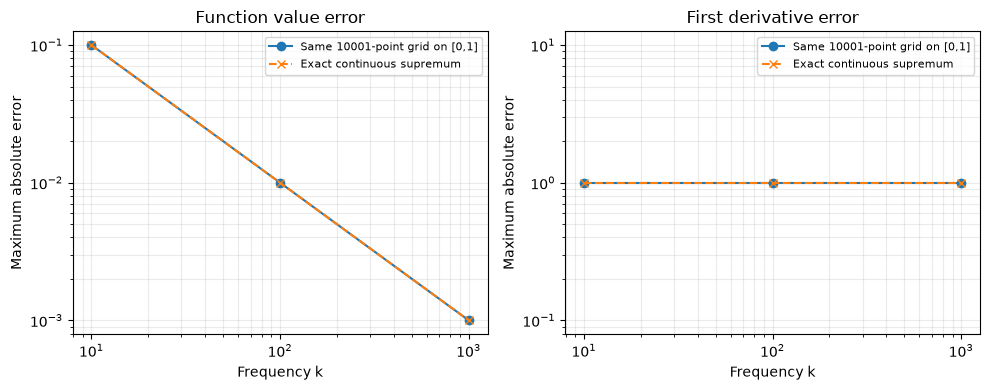

Conclusion: function errors decrease as 1/k, but derivative errors remain 1. Grid observations supplement, not replace, the witness-point proof.


In [2]:
grid=np.linspace(0.,1.,10001,dtype=np.float64)
rows=[]
for k in [10,100,1000]:
    ev=np.sin(k*grid)/k
    ed=np.cos(k*grid)
    ed2=-k*np.sin(k*grid)
    witness=np.pi/(2*k)
    assert 0<=witness<=1
    np.testing.assert_allclose([abs(np.sin(k*witness)/k),abs(np.cos(0.)),abs(-k*np.sin(k*witness))],[1/k,1,k],rtol=1e-14,atol=1e-14)
    row=dict(k=k,grid_points=len(grid),grid_start=0.,grid_end=1.,grid_max_value=float(np.max(abs(ev))),continuous_max_value=1/k,grid_max_first=float(np.max(abs(ed))),continuous_max_first=1.,grid_max_second=float(np.max(abs(ed2))),continuous_max_second=float(k),value_witness=witness,first_witness=0.)
    assert row['grid_max_value']<=1/k+1e-14
    assert row['grid_max_first']==1.
    rows.append(row)
with Path('B1组-A1网络逼近&A2网络逼近-模板同网格.csv').open('w',encoding='utf-8-sig',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
print(json.dumps(rows,ensure_ascii=False,indent=2))
fig,axs=plt.subplots(1,2,figsize=(10,4))
ks=np.array([r['k'] for r in rows])
for ax,key,theory,title in [(axs[0],'grid_max_value',1/ks,'Function value error'),(axs[1],'grid_max_first',np.ones(3),'First derivative error')]:
    ax.loglog(ks,[r[key] for r in rows],'o-',label='Same 10001-point grid on [0,1]')
    ax.loglog(ks,theory,'x--',label='Exact continuous supremum')
    ax.set(xlabel='Frequency k',ylabel='Maximum absolute error',title=title)
    ax.grid(True,which='both',alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig('B1组-A1网络逼近&A2网络逼近-模板同网格.png',dpi=160)
display(fig);plt.close(fig)
print('Conclusion: function errors decrease as 1/k, but derivative errors remain 1. Grid observations supplement, not replace, the witness-point proof.')
